In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 데이터 읽기
df = pd.read_csv('./data/i.csv', encoding='euc-kr')

In [2]:
print("데이터 크기:", df.shape)

print("\n컬럼명:")
print(df.columns.tolist())

print("\n데이터 유형:")
print(df.dtypes)

print("\n결측치 개수:")
print(df.isna().sum())

print("\n샘플 데이터:")
print(df.head(5).to_string())

데이터 크기: (3037, 32)

컬럼명:
['항명', '호출부호', '선명', '입항횟수', '입항횟수.1', '구분', '외내', '입출', '총톤수', '입항일시', '출항일시', 'CIQ수속일자', '수리일시', '항해구분', 'MRN 번호', '계선장소', '계선장소.1', '계선장소.2', '차항지', '전출항지', '선박용도', '외항:한국인선원수\n내항:해기사선원수', '외항:외국인선원수\n내항:보통선원수', '승무원승선수', '승무원하선수', '승객승선수', '승객하선수', '승객', '예선', '도선', '부선호출부호1', '부선호출부호2']

데이터 유형:
항명                          str
호출부호                        str
선명                          str
입항횟수                      int64
입항횟수.1                    int64
구분                          str
외내                          str
입출                          str
총톤수                         str
입항일시                        str
출항일시                        str
CIQ수속일자                     str
수리일시                        str
항해구분                        str
MRN 번호                      str
계선장소                        str
계선장소.1                    int64
계선장소.2                      str
차항지                         str
전출항지                        str
선박용도                        str
외

In [3]:


# 원본 보존
work = df.copy()

# 1. 입출 구분 확인
print("입출 구분별 행 수")
print(work["입출"].value_counts(dropna=False))

# 2. 입항일시·출항일시를 날짜 형식으로 변환
for col in ["입항일시", "출항일시", "CIQ수속일자", "수리일시"]:
    work[col + "_dt"] = pd.to_datetime(
        work[col].astype("string").str.strip(),
        errors="coerce"
    )

print("\n날짜 변환 실패 건수")
for col in ["입항일시", "출항일시", "CIQ수속일자", "수리일시"]:
    print(col, work[col + "_dt"].isna().sum())

# 3. 입항 행과 출항 행의 승객 정보 비교
passenger_cols = ["승객", "승객승선수", "승객하선수"]

print("\n입출 구분별 승객 정보 결측률")
print(
    work.groupby("입출")[passenger_cols]
        .agg(lambda s: s.isna().mean().round(3))
)

# 4. 연도별·입출 구분별 기록 수
work["입항연도"] = work["입항일시_dt"].dt.year

print("\n연도별 입출 기록 수")
print(
    work.groupby(["입항연도", "입출"])
        .size()
        .unstack(fill_value=0)
)

# 5. 입항 행만 별도로 확인
arrivals = work.loc[work["입출"].eq("입항")].copy()

print("\n입항 행 수:", len(arrivals))
print("입항일시 결측:", arrivals["입항일시_dt"].isna().sum())

print("\n입항 행의 승객 정보")
print(arrivals[passenger_cols].describe())

# 6. 입항일시·출항일시 역전 여부 확인
valid = work.dropna(
    subset=["입항일시_dt", "출항일시_dt"]
)

print(
    "\n출항일시가 입항일시보다 빠른 행:",
    (valid["출항일시_dt"] < valid["입항일시_dt"]).sum()
)

입출 구분별 행 수
입출
출항    1519
입항    1518
Name: count, dtype: int64

날짜 변환 실패 건수
입항일시 0
출항일시 0
CIQ수속일자 0
수리일시 2

입출 구분별 승객 정보 결측률
       승객  승객승선수  승객하선수
입출                     
입항  0.001  0.646  0.557
출항  0.003  0.400  0.329

연도별 입출 기록 수
입출     입항   출항
입항연도          
2013  106  106
2014  104  104
2015   64   64
2016  205  206
2017   89   89
2018   80   80
2019  107  107
2023  105  105
2024  114  114
2025  205  205
2026  339  339

입항 행 수: 1518
입항일시 결측: 0

입항 행의 승객 정보
                승객        승객승선수        승객하선수
count  1516.000000   538.000000   672.000000
mean   1828.970317   167.553903   171.217262
std    1402.751776   509.992334   504.249835
min       2.000000     0.000000     0.000000
25%     471.000000     2.000000     2.000000
50%    1875.500000     5.000000     6.000000
75%    2767.000000    20.000000    46.750000
max    5464.000000  2800.000000  2785.000000

출항일시가 입항일시보다 빠른 행: 0


In [4]:
# 같은 항차로 추정되는 기록을 연결하기 위한 기준
key_cols = [
    "호출부호",
    "선명",
    "입항일시_dt",
    "출항일시_dt"
]

# 입항·출항별로 동일 항차 키가 몇 건씩 있는지 확인
call_check = (
    work.groupby(key_cols + ["입출"])
        .size()
        .unstack(fill_value=0)
)

# 입항 또는 출항 기록 수가 서로 다른 항차
for col in ["입항", "출항"]:
    if col not in call_check.columns:
        call_check[col] = 0

mismatch = call_check.loc[
    call_check["입항"] != call_check["출항"]
]

print("전체 항차 후보 수:", len(call_check))
print("입항·출항 기록 수가 다른 항차 후보 수:", len(mismatch))
print("\n불일치 항차 후보:")
print(mismatch.to_string())

# 입항과 출항 기록이 각각 정확히 1건인 항차만 비교
matched_keys = call_check.index[
    (call_check["입항"] == 1) &
    (call_check["출항"] == 1)
]

matched = (
    work.set_index(key_cols)
        .loc[matched_keys]
        .reset_index()
)

# 승객 관련 값이 입항·출항 기록에서 어떻게 다른지 비교
for col in ["승객", "승객승선수", "승객하선수"]:
    print(f"\n[{col}] 입항·출항별 값 비교")

    comparison = (
        matched.pivot_table(
            index=key_cols,
            columns="입출",
            values=col,
            aggfunc="first"
        )
    )

    print(comparison.head(10).to_string())

전체 항차 후보 수: 1519
입항·출항 기록 수가 다른 항차 후보 수: 1

불일치 항차 후보:
입출                                                     입항  출항
호출부호  선명      입항일시_dt             출항일시_dt                    
ZCDM7 ARTANIA 2016-03-20 06:45:00 2016-03-20 17:57:00   0   1

[승객] 입항·출항별 값 비교
입출                                                                   입항      출항
호출부호  선명                입항일시_dt             출항일시_dt                            
2HFZ6 SAPPHIRE PRINCESS 2014-05-29 06:00:00 2014-05-29 18:05:00  2504.0  2500.0
                        2014-06-02 06:00:00 2014-06-02 19:06:00  2975.0  2972.0
                        2014-06-11 06:00:00 2014-06-11 18:00:00  1293.0  1289.0
                        2014-06-15 06:00:00 2014-06-15 18:06:00  2153.0  2150.0
                        2014-06-20 06:00:00 2014-06-20 23:06:00  1869.0  1860.0
                        2014-06-24 06:00:00 2014-06-24 18:06:00  2991.0  2986.0
                        2014-07-06 20:00:00 2014-07-07 04:07:00  2372.0  2362.0
                     

In [5]:

key_cols = [
    "호출부호", "선명", "입항일시_dt", "출항일시_dt"
]

# 1. 입항·출항이 모두 존재하는 항차의 승객 수 비교
passenger_pivot = (
    work[work["입출"].isin(["입항", "출항"])]
    .pivot_table(
        index=key_cols,
        columns="입출",
        values="승객",
        aggfunc="first"
    )
)

# 입항·출항 모두 승객 값이 있는 항차만 비교
both = passenger_pivot.dropna(subset=["입항", "출항"]).copy()
both["차이"] = both["출항"] - both["입항"]
both["절대차이"] = both["차이"].abs()

print("입항·출항 모두 승객 값이 있는 항차:", len(both))
print("\n승객 수 차이 요약")
print(both["차이"].describe())

print("\n절대 차이 구간별 항차 수")
print(
    pd.cut(
        both["절대차이"],
        bins=[-1, 0, 5, 20, 100, float("inf")],
        labels=["차이 없음", "1~5명", "6~20명", "21~100명", "100명 초과"]
    ).value_counts().sort_index()
)

# 2. 실제 승객 관련 값이 기록된 항차 사례 확인
# 승객 값이 입항·출항에서 모두 다른 사례를 절대차이 기준으로 정렬
print("\n승객 수 차이가 큰 항차 10건")
print(
    both.sort_values("절대차이", ascending=False)
        [["입항", "출항", "차이"]]
        .head(10)
        .to_string()
)

# 3. 대표 사례의 원자료 확인
sample = work[
    work["선명"].str.upper().eq("SAPPHIRE PRINCESS")
    & work["입항일시_dt"].between(
        pd.Timestamp("2014-05-29"),
        pd.Timestamp("2014-06-03")
    )
]

cols = [
    "선명", "호출부호", "입출",
    "입항일시_dt", "출항일시_dt",
    "계선장소.2", "항해구분", "선박용도",
    "승객", "승객승선수", "승객하선수",
    "승무원승선수", "승무원하선수"
]

print("\n대표 항차 원자료")
print(sample[cols].to_string(index=False))

입항·출항 모두 승객 값이 있는 항차: 1511

승객 수 차이 요약
count    1511.000000
mean      -15.353408
std       304.036737
min     -2775.000000
25%        -5.000000
50%        -1.000000
75%         2.000000
max      2367.000000
Name: 차이, dtype: float64

절대 차이 구간별 항차 수
절대차이
차이 없음      252
1~5명       653
6~20명      305
21~100명    136
100명 초과    165
Name: count, dtype: int64

승객 수 차이가 큰 항차 10건
입출                                                                     입항      출항      차이
호출부호  선명                  입항일시_dt             출항일시_dt                                    
ICAZ  COSTA SERENA        2023-06-11 11:00:00 2023-06-11 19:00:00  2786.0    11.0 -2775.0
                          2018-05-17 13:12:00 2018-05-17 18:18:00  3004.0   397.0 -2607.0
                          2019-05-12 12:00:00 2019-05-12 18:00:00  2684.0   240.0 -2444.0
C6FV9 MARINER OF THE SEAS 2014-10-16 08:00:00 2014-10-16 17:00:00  2442.0    20.0 -2422.0
                          2014-10-09 21:00:00 2014-10-10 16:30:00    80.0  2447.0  2367

In [6]:
# 입항·출항 승객 수 차이가 큰 항차 10건의 원자료 확인
top_keys = (
    both.sort_values("절대차이", ascending=False)
        .head(10)
        .index
)

detail_cols = [
    "선명", "호출부호", "입출",
    "입항일시_dt", "출항일시_dt",
    "CIQ수속일자", "수리일시",
    "MRN 번호", "계선장소", "계선장소.1", "계선장소.2",
    "항해구분", "선박용도",
    "승객", "승객승선수", "승객하선수",
    "승무원승선수", "승무원하선수"
]

# 같은 항차의 입항·출항 행을 모두 표시
top_detail = (
    work.set_index(key_cols)
        .loc[top_keys]
        .reset_index()
)

print(top_detail[detail_cols].to_string(index=False))

                 선명  호출부호 입출             입항일시_dt             출항일시_dt          CIQ수속일자             수리일시      MRN 번호 계선장소  계선장소.1       계선장소.2 항해구분 선박용도     승객  승객승선수  승객하선수  승무원승선수  승무원하선수
       COSTA SERENA  ICAZ 입항 2023-06-11 11:00:00 2023-06-11 19:00:00 2023-06-11 12:00  2023-06-12 8:54 23PKNS0612I  MBF       1 북항크루즈터미널 1선석   기타 크루즈선 2786.0    1.0 2785.0    17.0    12.0
       COSTA SERENA  ICAZ 출항 2023-06-11 11:00:00 2023-06-11 19:00:00 2023-06-11 18:00  2023-06-12 9:02 23PKNS0612E  MBF       1 북항크루즈터미널 1선석   기타 크루즈선   11.0   10.0 2785.0    17.0    15.0
       COSTA SERENA  ICAZ 출항 2018-05-17 13:12:00 2018-05-17 18:18:00 2018-05-17 17:00 2018-05-18 13:00 18PKNS0517E  MBF      14 국제여객터미널 14선석   기타 크루즈선  397.0  394.0    NaN     7.0     NaN
       COSTA SERENA  ICAZ 입항 2018-05-17 13:12:00 2018-05-17 18:18:00 2018-05-17 13:00  2018-05-18 9:48 18PKNS0517I  MBF      14 국제여객터미널 14선석   기타 크루즈선 3004.0    NaN    NaN     NaN     NaN
       COSTA SERENA  ICAZ 입항 2019-05-12 12:00:00 2019-05-12 

In [7]:
# 승객 관련 열의 기록 패턴 확인
cols = [
    "승객",
    "승객승선수",
    "승객하선수",
    "승무원승선수",
    "승무원하선수"
]

print("입출 구분별 승객 관련 열의 결측률")
print(
    work.groupby("입출")[cols]
        .agg(lambda s: s.isna().mean().round(3))
)

print("\n입출 구분별 승객 관련 열의 중앙값")
print(
    work.groupby("입출")[cols]
        .median(numeric_only=True)
)

# 입항 행과 출항 행을 각각 분리하여 원자료 확인
print("\n입항 행 예시")
print(
    work.loc[work["입출"].eq("입항"), cols]
        .describe()
)

print("\n출항 행 예시")
print(
    work.loc[work["입출"].eq("출항"), cols]
        .describe()
)

# 승객 값이 극단적으로 다른 항차의 신고 정보 확인
check_cols = [
    "선명", "호출부호", "입출",
    "입항일시_dt", "출항일시_dt",
    "CIQ수속일자", "수리일시", "MRN 번호",
    "계선장소.2", "승객",
    "승객승선수", "승객하선수"
]

print("\n승객 값이 극단적으로 다른 항차의 원자료")
print(
    work.loc[
        work["선명"].str.upper().eq("COSTA SERENA")
        & work["입항일시_dt"].between(
            pd.Timestamp("2023-06-10"),
            pd.Timestamp("2023-06-12")
        ),
        check_cols
    ].sort_values(["입항일시_dt", "입출"])
     .to_string(index=False)
)

입출 구분별 승객 관련 열의 결측률
       승객  승객승선수  승객하선수  승무원승선수  승무원하선수
입출                                     
입항  0.001  0.646  0.557   0.561   0.575
출항  0.003  0.400  0.329   0.235   0.357

입출 구분별 승객 관련 열의 중앙값
        승객  승객승선수  승객하선수  승무원승선수  승무원하선수
입출                                      
입항  1875.5    5.0    6.0     8.0     6.0
출항  1850.5    6.0    6.0     8.0     7.0

입항 행 예시
                승객        승객승선수        승객하선수      승무원승선수      승무원하선수
count  1516.000000   538.000000   672.000000  666.000000  645.000000
mean   1828.970317   167.553903   171.217262   12.833333   11.325581
std    1402.751776   509.992334   504.249835   15.847321   17.785193
min       2.000000     0.000000     0.000000    0.000000    0.000000
25%     471.000000     2.000000     2.000000    3.000000    2.000000
50%    1875.500000     5.000000     6.000000    8.000000    6.000000
75%    2767.000000    20.000000    46.750000   16.000000   13.000000
max    5464.000000  2800.000000  2785.000000  174.000000  285.000000

출항 행

In [8]:

# 입항 기록만 사용
arrivals = work.loc[work["입출"].eq("입항")].copy()

# 날짜 파생변수
arrivals["입항연도"] = arrivals["입항일시_dt"].dt.year
arrivals["입항월"] = arrivals["입항일시_dt"].dt.month
arrivals["입항요일"] = arrivals["입항일시_dt"].dt.dayofweek
arrivals["입항시간"] = arrivals["입항일시_dt"].dt.hour
arrivals["입항일자"] = arrivals["입항일시_dt"].dt.date

# 1. 연도별 기록 수
print("=== 연도별 입항 건수 ===")
print(arrivals.groupby("입항연도").size())

# 2. 월별 입항 건수
print("\n=== 월별 입항 건수 ===")
print(
    arrivals.groupby("입항월")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

# 3. 요일별 입항 건수
weekday_names = {
    0: "월요일", 1: "화요일", 2: "수요일",
    3: "목요일", 4: "금요일", 5: "토요일",
    6: "일요일"
}

weekday_counts = (
    arrivals.groupby("입항요일")
    .size()
    .reindex(range(7), fill_value=0)
)
weekday_counts.index = weekday_counts.index.map(weekday_names)

print("\n=== 요일별 입항 건수 ===")
print(weekday_counts)

# 4. 시간대별 입항 건수
print("\n=== 시간대별 입항 건수 ===")
print(
    arrivals.groupby("입항시간")
    .size()
    .reindex(range(24), fill_value=0)
)

# 5. 계선 장소별 입항 건수
print("\n=== 계선 장소별 입항 건수 ===")
print(
    arrivals["계선장소.2"]
    .value_counts(dropna=False)
)

# 6. 같은 날짜의 동시 입항 수요 확인
daily_calls = (
    arrivals.groupby("입항일자")
    .size()
    .sort_values(ascending=False)
)

print("\n=== 입항 건수가 많은 날짜 15개 ===")
print(daily_calls.head(15))

=== 연도별 입항 건수 ===
입항연도
2013    106
2014    104
2015     64
2016    205
2017     89
2018     80
2019    107
2023    105
2024    114
2025    205
2026    339
dtype: int64

=== 월별 입항 건수 ===
입항월
1      56
2      51
3     135
4     219
5     207
6     158
7     125
8     143
9     160
10    151
11     69
12     44
dtype: int64

=== 요일별 입항 건수 ===
입항요일
월요일    219
화요일    233
수요일    228
목요일    190
금요일    209
토요일    185
일요일    254
dtype: int64

=== 시간대별 입항 건수 ===
입항시간
0       3
1       1
2       1
3       1
4       3
5      70
6     386
7     359
8     214
9     173
10     79
11     75
12     63
13     46
14     19
15      6
16      8
17      5
18      1
19      1
20      2
21      2
22      0
23      0
dtype: int64

=== 계선 장소별 입항 건수 ===
계선장소.2
북항크루즈터미널 1선석          522
영도크루즈터미널              446
국제여객터미널 14선석          276
북항크루즈터미널 2선석          128
감만부두 3선석(신선대감만터미널)    121
1부두 14선석                7
자성대부두 64선석              4
남외항 N-4박지               4
남외항 N-5박지               2
감만부두 2선석(신선대감만터미널)    

In [9]:


# 입항 기록만 사용
arrivals = work.loc[work["입출"].eq("입항")].copy()

arrivals["입항일시_dt"] = pd.to_datetime(
    arrivals["입항일시_dt"], errors="coerce"
)
arrivals["출항일시_dt"] = pd.to_datetime(
    arrivals["출항일시_dt"], errors="coerce"
)

# 유효한 입항·출항 시간만 사용
valid = arrivals.dropna(
    subset=["입항일시_dt", "출항일시_dt"]
).copy()

valid = valid.loc[
    valid["출항일시_dt"] > valid["입항일시_dt"]
].copy()

print("분석 가능한 입항 기록:", len(valid))
print("제외된 기록:", len(arrivals) - len(valid))

# 시간대별 입항 건수
valid["입항시간"] = valid["입항일시_dt"].dt.hour

print("\n=== 시간대별 입항 건수 ===")
print(
    valid.groupby("입항시간")
    .size()
    .reindex(range(24), fill_value=0)
)

# 선박이 항만에 체류한 시간과 겹치는 시간대 계산
# 각 시간대와 선박의 체류 구간이 겹치면 해당 시간대의 체류 선박으로 계산
hourly_counts = {}

for _, row in valid.iterrows():
    start = row["입항일시_dt"]
    end = row["출항일시_dt"]

    hour_start = start.floor("h")

    while hour_start < end:
        next_hour = hour_start + pd.Timedelta(hours=1)

        # 선박 체류 구간과 해당 시간대가 실제로 겹치는지 확인
        if start < next_hour and end > hour_start:
            hourly_counts[hour_start] = (
                hourly_counts.get(hour_start, 0) + 1
            )

        hour_start = next_hour

hourly_occupancy = pd.Series(
    hourly_counts, name="동시체류선박수"
).sort_index()

print("\n=== 동시 체류 선박 수가 많은 시간대 ===")
print(
    hourly_occupancy.sort_values(ascending=False).head(20)
)

# 시간대별 동시 체류 선박 수의 분포
print("\n=== 동시 체류 선박 수 요약 ===")
print(hourly_occupancy.describe())

# 연도별 최대 동시 체류 선박 수
occupancy_df = hourly_occupancy.rename_axis(
    "시간"
).reset_index()

occupancy_df["연도"] = occupancy_df["시간"].dt.year

print("\n=== 연도별 최대 동시 체류 선박 수 ===")
print(
    occupancy_df.groupby("연도")["동시체류선박수"]
    .max()
)

분석 가능한 입항 기록: 1518
제외된 기록: 0

=== 시간대별 입항 건수 ===
입항시간
0       3
1       1
2       1
3       1
4       3
5      70
6     386
7     359
8     214
9     173
10     79
11     75
12     63
13     46
14     19
15      6
16      8
17      5
18      1
19      1
20      2
21      2
22      0
23      0
dtype: int64

=== 동시 체류 선박 수가 많은 시간대 ===
2024-04-03 11:00:00    4
2024-04-03 12:00:00    4
2024-04-03 13:00:00    4
2024-04-03 14:00:00    4
2024-04-03 15:00:00    4
2026-02-23 13:00:00    4
2026-02-23 14:00:00    4
2025-04-03 06:00:00    4
2025-04-03 07:00:00    4
2025-04-03 08:00:00    4
2026-02-23 15:00:00    4
2026-02-23 16:00:00    4
2026-02-23 17:00:00    4
2025-04-03 09:00:00    4
2025-04-03 10:00:00    4
2025-04-03 11:00:00    4
2025-04-03 12:00:00    4
2025-04-03 13:00:00    4
2025-04-03 14:00:00    4
2025-04-03 15:00:00    4
Name: 동시체류선박수, dtype: int64

=== 동시 체류 선박 수 요약 ===
count    20890.000000
mean         1.245093
std          0.532496
min          1.000000
25%          1.000000
50% 

In [11]:
# 1. 동시 체류 선박 수별 시간 구간 수
print("=== 동시 체류 선박 수별 시간 구간 ===")
print(
    hourly_occupancy
    .value_counts()
    .sort_index()
    .rename_axis("동시체류선박수")
    .rename("시간구간수")
)

# 2. 동시 체류 선박 수가 4척인 시간 구간
peak_hours = hourly_occupancy[hourly_occupancy == 4]

print("\n=== 동시 체류 4척 시간 구간 수 ===")
print(len(peak_hours))

# 3. 연도별 최대 혼잡 수준 및 4척 중첩 시간 구간 수
occupancy_summary = occupancy_df.groupby("연도").agg(
    최대동시체류선박수=("동시체류선박수", "max"),
    네척중첩시간구간수=(
        "동시체류선박수",
        lambda s: (s == 4).sum()
    ),
    관측시간구간수=("동시체류선박수", "size")
)

print("\n=== 연도별 체류 집중도 ===")
print(occupancy_summary)

# 4. 최대 혼잡 시간대의 날짜별 분포
if not peak_hours.empty:
    peak_by_date = peak_hours.groupby(
        peak_hours.index.date
    ).size().sort_values(ascending=False)

    print("\n=== 4척 중첩 시간 구간이 많았던 날짜 ===")
    print(peak_by_date.head(15))

=== 동시 체류 선박 수별 시간 구간 ===
동시체류선박수
1    16672
2     3443
3      648
4      127
Name: 시간구간수, dtype: int64

=== 동시 체류 4척 시간 구간 수 ===
127

=== 연도별 체류 집중도 ===
      최대동시체류선박수  네척중첩시간구간수  관측시간구간수
연도                                 
2013          2          0     1672
2014          3          0     1307
2015          2          0      697
2016          3          0     1953
2017          2          0     1000
2018          2          0      944
2019          3          0     1093
2023          3          0     1010
2024          4          8     1186
2025          4         28     5524
2026          4         91     4504

=== 4척 중첩 시간 구간이 많았던 날짜 ===
2025-04-15    11
2025-04-03    11
2026-03-27     9
2026-02-23     9
2026-05-23     9
2026-05-26     9
2024-04-03     8
2026-09-29     8
2026-05-28     8
2026-07-07     7
2026-03-11     7
2026-04-02     7
2026-10-13     7
2025-03-29     6
2026-04-22     6
Name: 동시체류선박수, dtype: int64


In [12]:
# 연도별 4척 중첩 비율 계산
occupancy_summary["네척중첩비율(%)"] = (
    occupancy_summary["네척중첩시간구간수"]
    / occupancy_summary["관측시간구간수"]
    * 100
).round(2)

print("=== 연도별 동시 체류 집중도 비교 ===")
print(
    occupancy_summary[
        [
            "최대동시체류선박수",
            "네척중첩시간구간수",
            "관측시간구간수",
            "네척중첩비율(%)"
        ]
    ]
)

=== 연도별 동시 체류 집중도 비교 ===
      최대동시체류선박수  네척중첩시간구간수  관측시간구간수  네척중첩비율(%)
연도                                            
2013          2          0     1672       0.00
2014          3          0     1307       0.00
2015          2          0      697       0.00
2016          3          0     1953       0.00
2017          2          0     1000       0.00
2018          2          0      944       0.00
2019          3          0     1093       0.00
2023          3          0     1010       0.00
2024          4          8     1186       0.67
2025          4         28     5524       0.51
2026          4         91     4504       2.02


In [13]:
# 입항 기록 기준 선석별 입항 건수 및 체류시간
berth_data = valid.copy()

berth_data["체류시간_시간"] = (
    berth_data["출항일시_dt"] - berth_data["입항일시_dt"]
).dt.total_seconds() / 3600

berth_summary = (
    berth_data.groupby("계선장소.2")
    .agg(
        입항건수=("호출부호", "size"),
        평균체류시간=("체류시간_시간", "mean"),
        중앙값체류시간=("체류시간_시간", "median"),
        최대체류시간=("체류시간_시간", "max")
    )
    .sort_values("입항건수", ascending=False)
)

print("=== 선석별 입항 및 체류시간 요약 ===")
print(berth_summary.round(2).head(15))

=== 선석별 입항 및 체류시간 요약 ===
                    입항건수  평균체류시간  중앙값체류시간  최대체류시간
계선장소.2                                           
북항크루즈터미널 1선석         522   11.51    10.62   62.18
영도크루즈터미널             446   12.83    11.12  345.25
국제여객터미널 14선석         276   31.61    10.19  322.00
북항크루즈터미널 2선석         128   20.48    10.33  970.00
감만부두 3선석(신선대감만터미널)   121   11.11    11.07   35.00
1부두 14선석               7    9.28    10.83   11.17
자성대부두 64선석             4   10.48    10.56   12.00
남외항 N-4박지              4  162.00   152.00  272.00
남외항 N-5박지              2   13.50    13.50   26.00
감만부두 2선석(신선대감만터미널)     2   11.50    11.50   12.00
감만부두 4선석(신선대감만터미널)     1   12.50    12.50   12.50
국제여객터미널 13선석           1    7.50     7.50    7.50
국제여객터미널 10선석           1   10.00    10.00   10.00
수영박지(집단박지)             1   24.62    24.62   24.62
신선대부두 5선석              1   11.00    11.00   11.00


In [15]:
# 장기 체류 기록 표시
berth_data = valid.copy()

berth_data["체류시간_시간"] = (
    berth_data["출항일시_dt"]
    - berth_data["입항일시_dt"]
).dt.total_seconds() / 3600

berth_data["24시간초과"] = berth_data["체류시간_시간"] > 24

# 선석별 장기 체류 현황
long_stay_summary = (
    berth_data.groupby("계선장소.2")
    .agg(
        입항건수=("호출부호", "size"),
        이십사시간초과건수=("24시간초과", "sum"),
        평균체류시간=("체류시간_시간", "mean"),
        중앙값체류시간=("체류시간_시간", "median")
    )
    .sort_values("입항건수", ascending=False)
)

long_stay_summary["이십사시간초과비율(%)"] = (
    long_stay_summary["이십사시간초과건수"]
    / long_stay_summary["입항건수"] * 100
).round(2)

print("=== 선석별 장기 체류 현황 ===")
print(long_stay_summary.round(2).head(10))

# 24시간 초과 기록 제외 후 민감도 분석
normal_stay = berth_data.loc[
    berth_data["체류시간_시간"] <= 24
]

sensitivity = (
    normal_stay.groupby("계선장소.2")
    .agg(
        분석건수=("호출부호", "size"),
        평균체류시간=("체류시간_시간", "mean"),
        중앙값체류시간=("체류시간_시간", "median")
    )
    .sort_values("분석건수", ascending=False)
)

print("\n=== 24시간 초과 기록 제외 후 비교 ===")
print(sensitivity.round(2).head(10))

=== 선석별 장기 체류 현황 ===
                    입항건수  이십사시간초과건수  평균체류시간  중앙값체류시간  이십사시간초과비율(%)
계선장소.2                                                            
북항크루즈터미널 1선석         522         16   11.51    10.62          3.07
영도크루즈터미널             446         22   12.83    11.12          4.93
국제여객터미널 14선석         276         67   31.61    10.19         24.28
북항크루즈터미널 2선석         128         15   20.48    10.33         11.72
감만부두 3선석(신선대감만터미널)   121          1   11.11    11.07          0.83
1부두 14선석               7          0    9.28    10.83          0.00
자성대부두 64선석             4          0   10.48    10.56          0.00
남외항 N-4박지              4          4  162.00   152.00        100.00
남외항 N-5박지              2          1   13.50    13.50         50.00
감만부두 2선석(신선대감만터미널)     2          0   11.50    11.50          0.00

=== 24시간 초과 기록 제외 후 비교 ===
                    분석건수  평균체류시간  중앙값체류시간
계선장소.2                                   
북항크루즈터미널 1선석         506   10.73    10.51
영도크루즈터미널             

In [16]:
# 장기 체류 기록 상위 20건 확인
long_stays = (
    berth_data.loc[berth_data["체류시간_시간"] > 24]
    .sort_values("체류시간_시간", ascending=False)
)

check_cols = [
    "선명",
    "호출부호",
    "입항일시_dt",
    "출항일시_dt",
    "계선장소.2",
    "체류시간_시간"
]

print("=== 장기 체류 기록 상위 20건 ===")
print(long_stays[check_cols].head(20).to_string(index=False))

=== 장기 체류 기록 상위 20건 ===
           선명   호출부호             입항일시_dt             출항일시_dt       계선장소.2  체류시간_시간
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00 북항크루즈터미널 2선석   970.00
 CLUB HARMONY  V7XN2 2013-01-31 06:45:00 2013-02-14 16:00:00     영도크루즈터미널   345.25
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00 국제여객터미널 14선석   322.00
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00 국제여객터미널 14선석   297.00
EASTERN VENUS 3E7469 2025-12-13 10:00:00 2025-12-24 18:00:00    남외항 N-4박지   272.00
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00    남외항 N-4박지   219.00
EASTERN VENUS 3E7469 2026-01-11 08:00:00 2026-01-17 18:00:00 국제여객터미널 14선석   154.00
EASTERN VENUS 3E7469 2025-11-01 20:00:00 2025-11-07 18:00:00 국제여객터미널 14선석   142.00
EASTERN VENUS 3E7469 2026-05-18 08:00:00 2026-05-23 19:00:00 국제여객터미널 14선석   131.00
EASTERN VENUS 3E7469 2026-02-01 08:00:00 2026-02-06 18:00:00 국제여객터미널 14선석   130.00
EASTERN VENUS 3E7469 2025-10-19 08:00:00 2025-10-24 18:00:00 국제

In [17]:


# 분석용 데이터
sensitivity_data = valid.copy()

sensitivity_data["체류시간_시간"] = (
    sensitivity_data["출항일시_dt"]
    - sensitivity_data["입항일시_dt"]
).dt.total_seconds() / 3600

# 주요 선석만 비교
main_berths = [
    "북항크루즈터미널 1선석",
    "영도크루즈터미널",
    "국제여객터미널 14선석",
    "북항크루즈터미널 2선석",
    "감만부두 3선석(신선대감만터미널)"
]

data_main = sensitivity_data[
    sensitivity_data["계선장소.2"].isin(main_berths)
].copy()

# 시나리오별 데이터 구성
scenarios = {
    "전체 기록": data_main,
    "24시간 초과 제외": data_main[
        data_main["체류시간_시간"] <= 24
    ],
    "EASTERN VENUS 제외": data_main[
        data_main["선명"].ne("EASTERN VENUS")
    ]
}

results = []

for scenario_name, scenario_data in scenarios.items():
    summary = (
        scenario_data.groupby("계선장소.2")
        .agg(
            분석건수=("체류시간_시간", "size"),
            평균체류시간=("체류시간_시간", "mean"),
            중앙값체류시간=("체류시간_시간", "median")
        )
    )

    summary["시나리오"] = scenario_name
    results.append(summary.reset_index())

comparison = pd.concat(results, ignore_index=True)

print("=== 장기 체류 민감도 분석 ===")
print(
    comparison.pivot(
        index="계선장소.2",
        columns="시나리오",
        values="평균체류시간"
    ).round(2)
)

print("\n=== 시나리오별 분석 건수 ===")
print(
    comparison.pivot(
        index="계선장소.2",
        columns="시나리오",
        values="분석건수"
    )
)

=== 장기 체류 민감도 분석 ===
시나리오                24시간 초과 제외  EASTERN VENUS 제외  전체 기록
계선장소.2                                                 
감만부두 3선석(신선대감만터미널)       10.91             11.11  11.11
국제여객터미널 14선석              9.95             10.62  31.61
북항크루즈터미널 1선석             10.73             11.51  11.51
북항크루즈터미널 2선석             10.16             13.03  20.48
영도크루즈터미널                 11.03             12.83  12.83

=== 시나리오별 분석 건수 ===
시나리오                24시간 초과 제외  EASTERN VENUS 제외  전체 기록
계선장소.2                                                 
감만부두 3선석(신선대감만터미널)         120               121    121
국제여객터미널 14선석               209               178    276
북항크루즈터미널 1선석               506               522    522
북항크루즈터미널 2선석               113               125    128
영도크루즈터미널                   424               446    446


In [18]:


# 분석할 주요 선석
main_berths = [
    "북항크루즈터미널 1선석",
    "영도크루즈터미널",
    "국제여객터미널 14선석",
    "북항크루즈터미널 2선석",
    "감만부두 3선석(신선대감만터미널)"
]

berth_data = valid[
    valid["계선장소.2"].isin(main_berths)
].copy()

# 선석별 시간대 중첩 계산
records = []

for _, row in berth_data.iterrows():
    start = row["입항일시_dt"]
    end = row["출항일시_dt"]
    berth = row["계선장소.2"]

    hour_start = start.floor("h")

    while hour_start < end:
        next_hour = hour_start + pd.Timedelta(hours=1)

        # 해당 시간 구간과 체류시간이 겹치는 경우
        if start < next_hour and end > hour_start:
            records.append({
                "시간": hour_start,
                "선석": berth,
                "호출부호": row["호출부호"]
            })

        hour_start = next_hour

overlap_df = pd.DataFrame(records)

# 시간-선석별 동시 체류 선박 수
berth_hourly = (
    overlap_df.groupby(["시간", "선석"])["호출부호"]
    .nunique()
    .rename("동시체류선박수")
    .reset_index()
)

# 선석별 최대 중첩 및 평균 중첩
berth_overlap_summary = (
    berth_hourly.groupby("선석")
    .agg(
        최대동시체류선박수=("동시체류선박수", "max"),
        평균동시체류선박수=("동시체류선박수", "mean"),
        관측시간구간수=("동시체류선박수", "size")
    )
    .sort_values("최대동시체류선박수", ascending=False)
)

print("=== 선석별 동시 체류 요약 ===")
print(berth_overlap_summary.round(2))

print("\n=== 선석별 동시 체류 2척 이상인 시간 구간 ===")
print(
    berth_hourly.loc[
        berth_hourly["동시체류선박수"] >= 2
    ].groupby("선석").size().sort_values(ascending=False)
)

=== 선석별 동시 체류 요약 ===
                    최대동시체류선박수  평균동시체류선박수  관측시간구간수
선석                                               
국제여객터미널 14선석                2       1.01     8745
북항크루즈터미널 2선석                2       1.06     2534
북항크루즈터미널 1선석                2       1.01     6210
영도크루즈터미널                    2       1.00     5941
감만부두 3선석(신선대감만터미널)          1       1.00     1414

=== 선석별 동시 체류 2척 이상인 시간 구간 ===
선석
북항크루즈터미널 2선석    143
국제여객터미널 14선석     97
북항크루즈터미널 1선석     37
영도크루즈터미널          1
dtype: int64


In [19]:
# 중첩된 시간 구간과 선박 목록 확인
overlap_cases = (
    overlap_df.groupby(["시간", "선석"])
    .agg(
        동시체류선박수=("호출부호", "nunique"),
        선박목록=("호출부호", lambda s: ", ".join(
            sorted(s.dropna().astype(str).unique())
        ))
    )
    .reset_index()
)

overlap_cases = overlap_cases.loc[
    overlap_cases["동시체류선박수"] >= 2
].sort_values(
    ["선석", "시간"]
)

print("=== 선석별 중첩 사례 ===")
print(overlap_cases.head(30).to_string(index=False))

print("\n=== 선석별 중첩 사례 수 ===")
print(
    overlap_cases.groupby("선석")
    .size()
    .sort_values(ascending=False)
)

=== 선석별 중첩 사례 ===
                 시간           선석  동시체류선박수         선박목록
2025-05-08 06:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 07:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 08:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 09:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 10:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 11:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 12:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 13:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 14:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-08 15:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 06:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 07:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 08:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 09:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 10:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 11:00:00 국제여객터미널 14선석        2 3E7469, ICAZ
2025-05-13 12:00:00 국제여객터미널 14선석        2 3E746

In [20]:
# EASTERN VENUS 호출부호
target_call_sign = "3E7469"

def get_overlap_summary(data):
    records = []

    for _, row in data.iterrows():
        start = row["입항일시_dt"]
        end = row["출항일시_dt"]
        berth = row["계선장소.2"]
        call_sign = row["호출부호"]

        hour_start = start.floor("h")

        while hour_start < end:
            next_hour = hour_start + pd.Timedelta(hours=1)

            if start < next_hour and end > hour_start:
                records.append({
                    "시간": hour_start,
                    "선석": berth,
                    "호출부호": call_sign
                })

            hour_start = next_hour

    temp = pd.DataFrame(records)

    if temp.empty:
        return pd.DataFrame(
            columns=["선석", "관측시간구간수", "중첩시간구간수"]
        )

    hourly = (
        temp.groupby(["시간", "선석"])["호출부호"]
        .nunique()
        .rename("동시체류선박수")
        .reset_index()
    )

    summary = (
        hourly.groupby("선석")
        .agg(
            관측시간구간수=("동시체류선박수", "size"),
            중첩시간구간수=(
                "동시체류선박수",
                lambda s: (s >= 2).sum()
            ),
            최대동시체류선박수=("동시체류선박수", "max")
        )
        .reset_index()
    )

    return summary


# 전체 데이터
summary_all = get_overlap_summary(berth_data)

# EASTERN VENUS 제외
berth_without_target = berth_data.loc[
    berth_data["호출부호"].astype(str) != target_call_sign
].copy()

summary_without_target = get_overlap_summary(berth_without_target)

comparison = summary_all.merge(
    summary_without_target,
    on="선석",
    how="outer",
    suffixes=("_전체", "_제외")
).fillna(0)

comparison["중첩구간 감소"] = (
    comparison["중첩시간구간수_전체"]
    - comparison["중첩시간구간수_제외"]
)

print(comparison.to_string(index=False))


# 앞서 만든 overlap_cases 활용
overlap_cases["날짜"] = overlap_cases["시간"].dt.date

print("=== 선석별 중첩 발생 날짜 수 ===")
print(
    overlap_cases.groupby("선석")["날짜"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n=== 선석별 선박 조합 수 ===")
overlap_cases["선박조합"] = overlap_cases["선박목록"].apply(
    lambda x: " + ".join(sorted(x.split(", ")))
)

print(
    overlap_cases.groupby("선석")["선박조합"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n=== 중첩 시간이 긴 선박 조합 ===")
print(
    overlap_cases.groupby(["선석", "선박조합"])
    .agg(
        중첩시간구간수=("시간", "size"),
        시작시간=("시간", "min"),
        종료시간=("시간", "max"),
        발생날짜수=("날짜", "nunique")
    )
    .sort_values("중첩시간구간수", ascending=False)
    .head(20)
    .to_string()
)

                선석  관측시간구간수_전체  중첩시간구간수_전체  최대동시체류선박수_전체  관측시간구간수_제외  중첩시간구간수_제외  최대동시체류선박수_제외  중첩구간 감소
감만부두 3선석(신선대감만터미널)        1414           0             1        1414           0             1        0
      국제여객터미널 14선석        8745          97             2        2001           0             1       97
      북항크루즈터미널 1선석        6210          37             2        6210          37             2        0
      북항크루즈터미널 2선석        2534         143             2        1684           0             1      143
          영도크루즈터미널        5941           1             2        5941           1             2        0
=== 선석별 중첩 발생 날짜 수 ===
선석
국제여객터미널 14선석    11
북항크루즈터미널 2선석    11
북항크루즈터미널 1선석     4
영도크루즈터미널         1
Name: 날짜, dtype: int64

=== 선석별 선박 조합 수 ===
선석
북항크루즈터미널 2선석    9
북항크루즈터미널 1선석    4
국제여객터미널 14선석    1
영도크루즈터미널        1
Name: 선박조합, dtype: int64

=== 중첩 시간이 긴 선박 조합 ===
                               중첩시간구간수                시작시간                종료시간  발생날짜수
선석           선박조합   

In [21]:
# 중첩이 확인된 두 선박의 원본 기록 확인
target_signs = ["3E7469", "ICAZ"]

cols = [
    "호출부호",
    "선명",
    "입항일시_dt",
    "출항일시_dt",
    "계선장소.2",
    "MRN 번호",
    "총톤수"
]

check = berth_data.loc[
    berth_data["호출부호"].astype(str).isin(target_signs),
    cols
].copy()

check = check.sort_values(["호출부호", "입항일시_dt"])

print(check.to_string(index=False))

# EASTERN VENUS가 포함되지 않은 중첩만 추출
other_overlaps = overlap_cases.loc[
    ~overlap_cases["선박목록"].str.contains(
        "3E7469", na=False
    )
].copy()

print("=== EASTERN VENUS 외 중첩 사례 ===")
print(
    other_overlaps[
        ["시간", "선석", "동시체류선박수", "선박목록"]
    ].to_string(index=False)
)

  호출부호            선명             입항일시_dt             출항일시_dt             계선장소.2      MRN 번호     총톤수
3E7469 EASTERN VENUS 2024-12-24 07:00:00 2024-12-24 20:00:00       북항크루즈터미널 2선석 24PKNS1224I  26,594
3E7469 EASTERN VENUS 2024-12-28 07:00:00 2024-12-28 17:00:00       북항크루즈터미널 2선석 24PKNS1228I  26,594
3E7469 EASTERN VENUS 2025-03-16 08:00:00 2025-04-25 18:00:00       북항크루즈터미널 2선석 25PKNS0316I  26,594
3E7469 EASTERN VENUS 2025-04-27 08:00:00 2025-05-01 15:00:00       국제여객터미널 14선석 25PKNS0427I  26,594
3E7469 EASTERN VENUS 2025-05-06 09:00:00 2025-05-09 17:00:00       국제여객터미널 14선석 25PKNS0506I  26,594
3E7469 EASTERN VENUS 2025-05-11 08:00:00 2025-05-23 17:00:00       국제여객터미널 14선석 25PKNS0511I  26,594
3E7469 EASTERN VENUS 2025-05-24 08:00:00 2025-06-06 18:00:00       국제여객터미널 14선석 25PKNS0524I  26,594
3E7469 EASTERN VENUS 2025-06-08 08:00:00 2025-06-13 18:00:00       국제여객터미널 14선석 25PKNS0609I  26,594
3E7469 EASTERN VENUS 2025-06-15 09:00:00 2025-06-20 18:00:00       국제여객터미널 14선석 25PKNS0616I  26,594


In [22]:

# 원본 입항 기록에서 필요한 열만 사용
ships = berth_data[
    [
        "호출부호",
        "선명",
        "입항일시_dt",
        "출항일시_dt",
        "계선장소.2",
        "MRN 번호"
    ]
].dropna(
    subset=["호출부호", "입항일시_dt", "출항일시_dt", "계선장소.2"]
).copy()

# 선박 조합별 실제 겹침 구간 계산
pairs = (
    overlap_cases[["선석", "선박조합"]]
    .drop_duplicates()
)

results = []

for _, pair in pairs.iterrows():
    berth = pair["선석"]
    signs = pair["선박조합"].split(" + ")

    if len(signs) != 2:
        continue

    a = ships[
        (ships["계선장소.2"] == berth) &
        (ships["호출부호"].astype(str) == signs[0])
    ]

    b = ships[
        (ships["계선장소.2"] == berth) &
        (ships["호출부호"].astype(str) == signs[1])
    ]

    for _, ra in a.iterrows():
        for _, rb in b.iterrows():
            start = max(ra["입항일시_dt"], rb["입항일시_dt"])
            end = min(ra["출항일시_dt"], rb["출항일시_dt"])

            if start < end:
                results.append({
                    "선석": berth,
                    "선박A": ra["선명"],
                    "호출부호A": ra["호출부호"],
                    "MRN_A": ra["MRN 번호"],
                    "선박B": rb["선명"],
                    "호출부호B": rb["호출부호"],
                    "MRN_B": rb["MRN 번호"],
                    "중첩시작": start,
                    "중첩종료": end,
                    "실제기록상_중첩시간": (
                        end - start
                    ).total_seconds() / 3600
                })

pair_overlap = pd.DataFrame(results)

if not pair_overlap.empty:
    pair_overlap = pair_overlap.sort_values(
        "실제기록상_중첩시간",
        ascending=False
    )

    print(
        pair_overlap.head(30).to_string(index=False)
    )
else:
    print("실제 입출항 구간이 겹치는 선박 조합이 없습니다.")

          선석                 선박A   호출부호A       MRN_A                  선박B   호출부호B       MRN_B                중첩시작                중첩종료  실제기록상_중첩시간
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I      AZAMARA PURSUIT 9HA4800 25UPBSC032I 2025-03-29 12:39:00 2025-03-30 18:08:00   29.483333
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I          SILVER NOVA   C6GA5 25WLSKB163I 2025-04-15 06:30:00 2025-04-15 23:00:00   16.500000
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I          SILVER MUSE   C6DC5 25WLSKB153I 2025-04-11 07:00:00 2025-04-11 23:00:00   16.000000
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I             EUROPA 2 9HA3283 25WLSKB119I 2025-03-17 06:00:00 2025-03-17 19:00:00   13.000000
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I       SEABOURN QUEST   C6YZ5 25WLSKB143I 2025-04-04 05:30:00 2025-04-04 18:00:00   12.500000
북항크루즈터미널 2선석       EASTERN VENUS  3E7469 25PKNS0316I   LE JACQUES CARTIER    FLYQ 25WLSKB157I 2025-04-14 06:00:00 2025-04-14

In [23]:
# 선박 조합별 중첩 유형 분류
pair_overlap["중첩유형"] = pair_overlap.apply(
    lambda row: (
        "EASTERN VENUS 포함"
        if "3E7469" in [
            str(row["호출부호A"]),
            str(row["호출부호B"])
        ]
        else "기타 선박 조합"
    ),
    axis=1
)

# 중첩유형별 요약
overlap_type_summary = (
    pair_overlap.groupby("중첩유형")
    .agg(
        중첩사례수=("실제기록상_중첩시간", "size"),
        평균중첩시간=("실제기록상_중첩시간", "mean"),
        중앙값중첩시간=("실제기록상_중첩시간", "median"),
        최대중첩시간=("실제기록상_중첩시간", "max")
    )
    .round(2)
)

print(overlap_type_summary)

                  중첩사례수  평균중첩시간  중앙값중첩시간  최대중첩시간
중첩유형                                            
EASTERN VENUS 포함     21   11.09     10.0   29.48
기타 선박 조합              5    7.12      9.3   11.00


In [24]:


# 1. 원본 데이터 복사
work = df.copy()

# 2. 입항 행만 추출
arrival = work[work["입출"] == "입항"].copy()

# 3. 날짜·시간 변수 생성
arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시"],
    errors="coerce"
)

arrival["날짜"] = arrival["입항일시_dt"].dt.date
arrival["연도"] = arrival["입항일시_dt"].dt.year
arrival["월"] = arrival["입항일시_dt"].dt.month
arrival["요일"] = arrival["입항일시_dt"].dt.dayofweek
arrival["시간"] = arrival["입항일시_dt"].dt.hour

# 4. 승객 수 숫자형 변환
arrival["승객"] = pd.to_numeric(
    arrival["승객"],
    errors="coerce"
)

# 5. 데이터 상태 확인
print("전체 데이터 행 수:", len(work))
print("입항 행 수:", len(arrival))
print("입항일시 결측 수:", arrival["입항일시_dt"].isna().sum())
print("승객 수 결측 수:", arrival["승객"].isna().sum())
print("승객 수 음수 행 수:", (arrival["승객"] < 0).sum())

print("\n=== 연도별 입항 건수 ===")
print(arrival.groupby("연도").size())

print("\n=== 승객 수 기초통계 ===")
print(arrival["승객"].describe())

print("\n=== 승객 수 결측 행 예시 ===")
print(
    arrival.loc[
        arrival["승객"].isna(),
        ["선명", "호출부호", "입항일시", "계선장소.2", "승객"]
    ].head(10)
)

전체 데이터 행 수: 3037
입항 행 수: 1518
입항일시 결측 수: 0
승객 수 결측 수: 2
승객 수 음수 행 수: 0

=== 연도별 입항 건수 ===
연도
2013    106
2014    104
2015     64
2016    205
2017     89
2018     80
2019    107
2023    105
2024    114
2025    205
2026    339
dtype: int64

=== 승객 수 기초통계 ===
count    1516.000000
mean     1828.970317
std      1402.751776
min         2.000000
25%       471.000000
50%      1875.500000
75%      2767.000000
max      5464.000000
Name: 승객, dtype: float64

=== 승객 수 결측 행 예시 ===
                 선명    호출부호              입항일시     계선장소.2  승객
1981  EASTERN VENUS  3E7469  2025-03-06 14:00  남외항 N-4박지 NaN
2340  EASTERN VENUS  3E7469  2025-12-13 10:00  남외항 N-4박지 NaN


In [25]:
# 날짜별 입항 건수와 기록 승객 수 집계

daily = (
    arrival
    .dropna(subset=["입항일시_dt"])
    .groupby(arrival["입항일시_dt"].dt.floor("D"))
    .agg(
        입항건수=("입항일시_dt", "size"),
        기록승객수=("승객", lambda x: x.sum(min_count=1))
    )
    .reset_index()
    .rename(columns={"입항일시_dt": "날짜"})
)

# 날짜 파생변수
daily["연도"] = daily["날짜"].dt.year
daily["월"] = daily["날짜"].dt.month
daily["요일"] = daily["날짜"].dt.dayofweek

print("일별 데이터 행 수:", len(daily))
print("분석 시작일:", daily["날짜"].min())
print("분석 종료일:", daily["날짜"].max())

print("\n=== 일별 입항 건수 기초통계 ===")
print(daily["입항건수"].describe())

print("\n=== 일별 기록 승객 수 기초통계 ===")
print(daily["기록승객수"].describe())

print("\n=== 입항 건수가 많은 날짜 상위 10개 ===")
print(
    daily.sort_values("입항건수", ascending=False)
         .head(10)
         [["날짜", "입항건수", "기록승객수"]]
         .to_string(index=False)
)

print("\n=== 집계 결과 예시 ===")
print(daily.head(10).to_string(index=False))

일별 데이터 행 수: 1189
분석 시작일: 2013-01-01 00:00:00
분석 종료일: 2026-10-16 00:00:00

=== 일별 입항 건수 기초통계 ===
count    1189.000000
mean        1.276703
std         0.547388
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         4.000000
Name: 입항건수, dtype: float64

=== 일별 기록 승객 수 기초통계 ===
count    1187.000000
mean     2335.904802
std      1738.843125
min         2.000000
25%       732.000000
50%      2234.000000
75%      3289.500000
max      8385.000000
Name: 기록승객수, dtype: float64

=== 입항 건수가 많은 날짜 상위 10개 ===
        날짜  입항건수  기록승객수
2026-07-07     4 4206.0
2026-10-13     4 7731.0
2026-09-29     4 4761.0
2026-03-25     3 5371.0
2026-04-04     3 7286.0
2026-06-09     3 4241.0
2026-06-10     3 5589.0
2026-03-27     3 3088.0
2025-05-11     3 3453.0
2026-09-02     3 7049.0

=== 집계 결과 예시 ===
        날짜  입항건수  기록승객수   연도  월  요일
2013-01-01     1  933.0 2013  1   1
2013-01-06     1  754.0 2013  1   6
2013-01-10     1  177.0 2013  1   3
2013-01-13     1  481.0 2013  1  

In [26]:
# 연도별 자료 범위 및 입항 건수 확인

coverage = (
    arrival
    .groupby("연도")
    .agg(
        첫입항일=("입항일시_dt", "min"),
        마지막입항일=("입항일시_dt", "max"),
        입항건수=("입항일시_dt", "size"),
        기록승객수결측=("승객", lambda x: x.isna().sum())
    )
)

# 연도별 달력 일수와 입항이 기록된 날짜 수 비교
coverage["해당기간일수"] = (
    coverage["마지막입항일"].dt.normalize()
    - coverage["첫입항일"].dt.normalize()
).dt.days + 1

coverage["입항기록일수"] = (
    arrival.groupby("연도")["날짜"].nunique()
)

coverage["입항기록없는날수"] = (
    coverage["해당기간일수"] - coverage["입항기록일수"]
)

print(coverage.to_string())

                    첫입항일              마지막입항일  입항건수  기록승객수결측  해당기간일수  입항기록일수  입항기록없는날수
연도                                                                                   
2013 2013-01-01 08:00:00 2013-11-03 06:45:00   106        0     307      95       212
2014 2014-01-29 08:30:00 2014-12-09 07:00:00   104        0     315      91       224
2015 2015-02-10 07:00:00 2015-12-08 06:30:00    64        0     302      58       244
2016 2016-01-02 07:00:00 2016-12-31 06:00:00   205        0     365     164       201
2017 2017-01-02 08:00:00 2017-10-22 00:01:00    89        0     294      80       214
2018 2018-02-28 06:30:00 2018-11-21 07:50:00    80        0     267      71       196
2019 2019-01-02 08:00:00 2019-12-14 05:30:00   107        0     347      87       260
2023 2023-03-12 17:00:00 2023-11-24 07:00:00   105        0     258      87       171
2024 2024-02-11 06:00:00 2024-12-30 07:30:00   114        0     324      95       229
2025 2025-01-02 05:30:00 2025-12-31 09:30:00   205    

In [27]:
# 연도별 관측 범위 안에서 날짜별 시계열 생성
# 전제: 해당 기간의 입항 기록이 완전한 이벤트 기록이어야 함

daily_parts = []

for year, group in arrival.groupby("연도"):
    start_date = group["입항일시_dt"].min().normalize()
    end_date = group["입항일시_dt"].max().normalize()

    # 해당 연도의 관측 범위 내 모든 날짜
    calendar = pd.DataFrame({
        "날짜": pd.date_range(start_date, end_date, freq="D")
    })

    # 기존 일별 집계 결과와 결합
    year_daily = daily.loc[daily["연도"] == year, [
        "날짜", "입항건수", "기록승객수"
    ]].copy()

    year_daily["날짜"] = pd.to_datetime(year_daily["날짜"])

    year_daily = calendar.merge(
        year_daily,
        on="날짜",
        how="left"
    )

    # 입항 기록 자체가 없는 날은 0건으로 처리
    no_arrival = year_daily["입항건수"].isna()
    year_daily.loc[no_arrival, "입항건수"] = 0
    year_daily.loc[no_arrival, "기록승객수"] = 0

    # 승객 수가 결측인 실제 입항일은 NaN으로 유지
    year_daily["연도"] = year
    year_daily["월"] = year_daily["날짜"].dt.month
    year_daily["요일"] = year_daily["날짜"].dt.dayofweek

    daily_parts.append(year_daily)

daily_ts = pd.concat(daily_parts, ignore_index=True)
daily_ts["입항건수"] = daily_ts["입항건수"].astype(int)

print("시계열 행 수:", len(daily_ts))
print("입항건수 합계:", daily_ts["입항건수"].sum())
print("승객 수 결측 행 수:", daily_ts["기록승객수"].isna().sum())

print("\n=== 연도별 일별 시계열 요약 ===")
print(
    daily_ts.groupby("연도").agg(
        날짜수=("날짜", "size"),
        입항건수합계=("입항건수", "sum"),
        무입항일수=("입항건수", lambda x: (x == 0).sum()),
        승객수결측일수=("기록승객수", lambda x: x.isna().sum())
    ).to_string()
)

시계열 행 수: 3432
입항건수 합계: 1518
승객 수 결측 행 수: 2

=== 연도별 일별 시계열 요약 ===
      날짜수  입항건수합계  무입항일수  승객수결측일수
연도                               
2013  307     106    212        0
2014  315     104    224        0
2015  302      64    244        0
2016  365     205    201        0
2017  294      89    214        0
2018  267      80    196        0
2019  347     107    260        0
2023  258     105    171        0
2024  324     114    229        0
2025  364     205    205        2
2026  289     339     87        0


In [28]:
# 월별 입항 건수
monthly = (
    daily_ts.groupby("월")["입항건수"]
    .agg(["sum", "mean"])
    .rename(columns={
        "sum": "입항건수합계",
        "mean": "일평균입항건수"
    })
)

# 요일: 월요일=0, 일요일=6
weekday_names = {
    0: "월요일",
    1: "화요일",
    2: "수요일",
    3: "목요일",
    4: "금요일",
    5: "토요일",
    6: "일요일"
}

weekday = (
    daily_ts.groupby("요일")["입항건수"]
    .agg(["sum", "mean"])
    .rename(columns={
        "sum": "입항건수합계",
        "mean": "일평균입항건수"
    })
)

weekday.index = weekday.index.map(weekday_names)

print("=== 월별 입항 패턴 ===")
print(monthly.round(3).to_string())

print("\n=== 요일별 입항 패턴 ===")
print(weekday.round(3).to_string())

=== 월별 입항 패턴 ===
    입항건수합계  일평균입항건수
월                  
1       56    0.303
2       51    0.216
3      135    0.409
4      219    0.664
5      207    0.607
6      158    0.479
7      125    0.367
8      143    0.419
9      160    0.485
10     151    0.476
11      69    0.303
12      44    0.358

=== 요일별 입항 패턴 ===
     입항건수합계  일평균입항건수
요일                  
월요일     219    0.448
화요일     233    0.476
수요일     228    0.464
목요일     190    0.387
금요일     209    0.426
토요일     185    0.378
일요일     254    0.518


In [30]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 날짜순 정렬
model_data = daily_ts.sort_values("날짜").copy()

# 현재 데이터셋의 관측 범위에서만 비교
split_idx = int(len(model_data) * 0.8)

train = model_data.iloc[:split_idx].copy()
test = model_data.iloc[split_idx:].copy()

# 학습 데이터의 평균
overall_mean = train["입항건수"].mean()

weekday_mean = train.groupby("요일")["입항건수"].mean()
month_weekday_mean = train.groupby(["월", "요일"])["입항건수"].mean()

# 기준 모델 1: 전체 학습 기간의 평균
test["예측_전체평균"] = overall_mean

# 기준 모델 2: 요일별 평균
test["예측_요일평균"] = (
    test["요일"].map(weekday_mean).fillna(overall_mean)
)

# 비교 모델 3: 월+요일별 평균
test["예측_월요일평균"] = [
    month_weekday_mean.get((m, w), overall_mean)
    for m, w in zip(test["월"], test["요일"])
]

# 성능 평가 함수
def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

results = pd.DataFrame({
    "전체평균": evaluate(test["입항건수"], test["예측_전체평균"]),
    "요일평균": evaluate(test["입항건수"], test["예측_요일평균"]),
    "월요일평균": evaluate(test["입항건수"], test["예측_월요일평균"])
}).T

print("학습 데이터:", train["날짜"].min(), "~", train["날짜"].max())
print("검증 데이터:", test["날짜"].min(), "~", test["날짜"].max())

print("\n=== 입항 건수 예측 성능 ===")
print(results.round(4))

print("\n=== 검증 데이터 예측 예시 ===")
print(
    test[[
        "날짜", "입항건수",
        "예측_전체평균", "예측_요일평균", "예측_월요일평균"
    ]].head(15).round(2).to_string(index=False)
)

학습 데이터: 2013-01-01 00:00:00 ~ 2024-11-26 00:00:00
검증 데이터: 2024-11-27 00:00:00 ~ 2026-10-16 00:00:00

=== 입항 건수 예측 성능 ===
          MAE    RMSE
전체평균   0.7812  1.0193
요일평균   0.7784  1.0178
월요일평균  0.7594  1.0123

=== 검증 데이터 예측 예시 ===
        날짜  입항건수  예측_전체평균  예측_요일평균  예측_월요일평균
2024-11-27     0     0.35     0.39      0.33
2024-11-28     1     0.35     0.34      0.19
2024-11-29     0     0.35     0.35      0.21
2024-11-30     0     0.35     0.31      0.10
2024-12-01     0     0.35     0.38      0.12
2024-12-02     1     0.35     0.35      0.11
2024-12-03     0     0.35     0.34      0.40
2024-12-04     1     0.35     0.39      0.38
2024-12-05     0     0.35     0.34      0.33
2024-12-06     0     0.35     0.35      0.22
2024-12-07     0     0.35     0.31      0.22
2024-12-08     0     0.35     0.38      0.12
2024-12-09     0     0.35     0.35      0.11
2024-12-10     0     0.35     0.34      0.40
2024-12-11     1     0.35     0.39      0.38


C:\Users\user\AppData\Local\Temp\ipykernel_24900\3644402104.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].head(15).round(2).to_string(index=False)


In [31]:
# 공식 통계와 비교할 수 있는 연도별 입항 건수
official = {
    2015: 71,
    2016: 209,
    2017: 108,
    2018: 84,
    2019: 108,
    2023: 106,
    2024: 114,
    2025: 203
}

comparison = (
    arrival.groupby("연도")
    .size()
    .rename("현재데이터")
    .to_frame()
)

comparison["공식통계"] = pd.Series(official)
comparison["차이"] = (
    comparison["현재데이터"] - comparison["공식통계"]
)

print(comparison.loc[comparison.index.isin(official)].to_string())

      현재데이터   공식통계    차이
연도                      
2015     64   71.0  -7.0
2016    205  209.0  -4.0
2017     89  108.0 -19.0
2018     80   84.0  -4.0
2019    107  108.0  -1.0
2023    105  106.0  -1.0
2024    114  114.0   0.0
2025    205  203.0   2.0


In [32]:
# 월별 입항 기록 범위와 건수 확인

arrival["연월"] = arrival["입항일시_dt"].dt.to_period("M")

monthly_coverage = (
    arrival.groupby("연월")
    .agg(
        입항건수=("입항일시_dt", "size"),
        첫입항일=("입항일시_dt", "min"),
        마지막입항일=("입항일시_dt", "max"),
        승객수결측=("승객", lambda x: x.isna().sum())
    )
    .reset_index()
)

print("=== 월별 자료 범위: 처음 30개월 ===")
print(monthly_coverage.head(30).to_string(index=False))

print("\n=== 월별 자료 범위: 마지막 24개월 ===")
print(monthly_coverage.tail(24).to_string(index=False))

print("\n=== 월별 입항 건수 통계 ===")
print(monthly_coverage["입항건수"].describe())

=== 월별 자료 범위: 처음 30개월 ===
     연월  입항건수                첫입항일              마지막입항일  승객수결측
2013-01    10 2013-01-01 08:00:00 2013-01-31 06:45:00      0
2013-03     7 2013-03-01 06:00:00 2013-03-29 07:00:00      0
2013-04    13 2013-04-02 07:50:00 2013-04-30 07:50:00      0
2013-05    13 2013-05-01 06:00:00 2013-05-28 10:00:00      0
2013-06    15 2013-06-01 06:00:00 2013-06-30 12:00:00      0
2013-07    14 2013-07-04 07:00:00 2013-07-28 07:30:00      0
2013-08    12 2013-08-01 09:00:00 2013-08-31 08:00:00      0
2013-09     9 2013-09-03 12:00:00 2013-09-29 10:45:00      0
2013-10    12 2013-10-01 09:00:00 2013-10-26 16:00:00      0
2013-11     1 2013-11-03 06:45:00 2013-11-03 06:45:00      0
2014-01     1 2014-01-29 08:30:00 2014-01-29 08:30:00      0
2014-02     4 2014-02-13 07:00:00 2014-02-25 07:00:00      0
2014-03     7 2014-03-01 08:00:00 2014-03-28 07:00:00      0
2014-04    10 2014-04-01 07:00:00 2014-04-27 07:00:00      0
2014-05    13 2014-05-02 06:00:00 2014-05-29 06:00:00      

In [33]:


# 입항 데이터 정리
arrival_model = arrival.copy()
arrival_model["입항일시_dt"] = pd.to_datetime(
    arrival_model["입항일시_dt"], errors="coerce"
)
arrival_model["승객"] = pd.to_numeric(
    arrival_model["승객"], errors="coerce"
)

# 날짜별 입항 건수와 기록 승객 수 집계
daily_observed = (
    arrival_model
    .groupby(arrival_model["입항일시_dt"].dt.normalize())
    .agg(
        입항건수=("입항일시_dt", "size"),
        기록승객수=("승객", lambda x: x.sum(min_count=1))
    )
)
daily_observed.index.name = "날짜"

# 전체 달력 생성
calendar = pd.date_range(
    start="2013-01-01",
    end="2026-10-16",
    freq="D"
)

daily_full = daily_observed.reindex(calendar)
daily_full.index.name = "날짜"

# 입항 기록이 없는 날은 0건으로 처리
no_arrival = daily_full["입항건수"].isna()
daily_full.loc[no_arrival, "입항건수"] = 0
daily_full.loc[no_arrival, "기록승객수"] = 0

daily_full["입항건수"] = daily_full["입항건수"].astype(int)

# 시간 변수
daily_full = daily_full.reset_index()
daily_full["연도"] = daily_full["날짜"].dt.year
daily_full["월"] = daily_full["날짜"].dt.month
daily_full["요일"] = daily_full["날짜"].dt.dayofweek

# 코로나19 운항 중단기 구분
daily_full["운항구간"] = np.select(
    [
        daily_full["날짜"] < pd.Timestamp("2020-01-01"),
        daily_full["날짜"] < pd.Timestamp("2023-01-01")
    ],
    [
        "코로나19 이전",
        "코로나19 무입항기"
    ],
    default="운항 재개 이후"
)

print("전체 날짜 수:", len(daily_full))
print("입항 건수 합계:", daily_full["입항건수"].sum())

print("\n=== 구간별 요약 ===")
print(
    daily_full.groupby("운항구간").agg(
        날짜수=("날짜", "size"),
        입항건수합계=("입항건수", "sum"),
        무입항일수=("입항건수", lambda x: (x == 0).sum()),
        평균일입항건수=("입항건수", "mean")
    ).to_string()
)

print("\n=== 2020~2022년 입항 건수 확인 ===")
print(
    daily_full.loc[
        daily_full["연도"].between(2020, 2022)
    ].groupby("연도")["입항건수"].agg(
        날짜수="size",
        입항건수합계="sum"
    ).to_string()
)

print("\n=== 승객 수 결측치 확인 ===")
print("결측 행 수:", daily_full["기록승객수"].isna().sum())

전체 날짜 수: 5037
입항 건수 합계: 1518

=== 구간별 요약 ===
             날짜수  입항건수합계  무입항일수   평균일입항건수
운항구간                                     
운항 재개 이후    1385     763    842  0.550903
코로나19 무입항기  1096       0   1096  0.000000
코로나19 이전    2556     755   1910  0.295383

=== 2020~2022년 입항 건수 확인 ===
      날짜수  입항건수합계
연도               
2020  366       0
2021  365       0
2022  365       0

=== 승객 수 결측치 확인 ===
결측 행 수: 2


In [34]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 운항 재개 이후 데이터만 사용
post = daily_full.loc[
    daily_full["날짜"] >= "2023-01-01"
].copy()

post = post.sort_values("날짜").reset_index(drop=True)

# 날짜순으로 80% 학습, 20% 검증
split_idx = int(len(post) * 0.8)
train = post.iloc[:split_idx].copy()
test = post.iloc[split_idx:].copy()

# 학습 데이터만으로 평균 계산
overall_mean = train["입항건수"].mean()

month_weekday_mean = train.groupby(
    ["월", "요일"]
)["입항건수"].mean()

# 예측값 생성
test["예측_전체평균"] = overall_mean

test["예측_월요일평균"] = [
    month_weekday_mean.get((month, weekday), overall_mean)
    for month, weekday in zip(test["월"], test["요일"])
]

# 성능 평가
def evaluate_model(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

results = pd.DataFrame({
    "전체평균": evaluate_model(
        test["입항건수"], test["예측_전체평균"]
    ),
    "월요일평균": evaluate_model(
        test["입항건수"], test["예측_월요일평균"]
    )
}).T

print("학습 기간:", train["날짜"].min(), "~", train["날짜"].max())
print("검증 기간:", test["날짜"].min(), "~", test["날짜"].max())

print("\n=== 운항 재개 이후 예측 성능 ===")
print(results.round(4))

print("\n=== 검증 데이터 예측 예시 ===")
print(
    test[[
        "날짜", "입항건수",
        "예측_전체평균", "예측_월요일평균"
    ]].head(20).round(2).to_string(index=False)
)

학습 기간: 2023-01-01 00:00:00 ~ 2026-01-12 00:00:00
검증 기간: 2026-01-13 00:00:00 ~ 2026-10-16 00:00:00

=== 운항 재개 이후 예측 성능 ===
          MAE    RMSE
전체평균   1.0371  1.2993
월요일평균  0.9630  1.2587

=== 검증 데이터 예측 예시 ===
        날짜  입항건수  예측_전체평균  예측_월요일평균
2026-01-13     1     0.39      0.00
2026-01-14     0     0.39      0.07
2026-01-15     0     0.39      0.40
2026-01-16     0     0.39      0.07
2026-01-17     1     0.39      0.21
2026-01-18     0     0.39      0.13
2026-01-19     1     0.39      0.19
2026-01-20     0     0.39      0.00
2026-01-21     1     0.39      0.07
2026-01-22     0     0.39      0.40
2026-01-23     0     0.39      0.07
2026-01-24     0     0.39      0.21
2026-01-25     2     0.39      0.13
2026-01-26     0     0.39      0.19
2026-01-27     3     0.39      0.00
2026-01-28     0     0.39      0.07
2026-01-29     1     0.39      0.40
2026-01-30     1     0.39      0.07
2026-01-31     0     0.39      0.21
2026-02-01     1     0.39      0.17


C:\Users\user\AppData\Local\Temp\ipykernel_24900\2871841235.py:57: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].head(20).round(2).to_string(index=False)


In [35]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 날짜순으로 전체 일별 데이터 정렬
series = (
    daily_full[["날짜", "입항건수", "월", "요일"]]
    .copy()
    .sort_values("날짜")
    .reset_index(drop=True)
)

series["날짜"] = pd.to_datetime(series["날짜"])

# 검증 기간의 시작일
test_start = pd.Timestamp("2026-01-13")

# 운항 재개 이후 데이터만 사용
post = series.loc[
    series["날짜"] >= "2023-01-01"
].copy().reset_index(drop=True)

split_idx = post.index[post["날짜"] >= test_start][0]

train = post.iloc[:split_idx].copy()
test = post.iloc[split_idx:].copy()

# 1. 전체 평균 모델
overall_mean = train["입항건수"].mean()
test["예측_전체평균"] = overall_mean

# 2. 월·요일 평균 모델
mw_mean = train.groupby(["월", "요일"])["입항건수"].mean()

test["예측_월요일평균"] = [
    mw_mean.get((m, d), overall_mean)
    for m, d in zip(test["월"], test["요일"])
]

# 3. 직전 7일 평균 모델
# 각 날짜 예측 시 해당 날짜 이전 7일의 실제 입항 건수만 사용
series_indexed = series.set_index("날짜")["입항건수"]

test["예측_최근7일평균"] = [
    series_indexed.loc[
        date - pd.Timedelta(days=7):
        date - pd.Timedelta(days=1)
    ].tail(7).mean()
    for date in test["날짜"]
]

# 평가
pred_cols = {
    "전체 평균": "예측_전체평균",
    "월·요일 평균": "예측_월요일평균",
    "최근 7일 평균": "예측_최근7일평균"
}

results = []

for model_name, pred_col in pred_cols.items():
    actual = test["입항건수"]
    predicted = test[pred_col]

    results.append({
        "모델": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

results = pd.DataFrame(results).set_index("모델")

print("검증 기간:", test["날짜"].min(), "~", test["날짜"].max())
print("\n=== 모델별 예측 성능 ===")
print(results.round(4))

print("\n=== 검증 데이터 예측 예시 ===")
print(
    test[[
        "날짜", "입항건수",
        "예측_전체평균",
        "예측_월요일평균",
        "예측_최근7일평균"
    ]].head(20).round(2).to_string(index=False)
)

검증 기간: 2026-01-13 00:00:00 ~ 2026-10-16 00:00:00

=== 모델별 예측 성능 ===
             MAE    RMSE
모델                      
전체 평균     1.0371  1.2993
월·요일 평균   0.9630  1.2587
최근 7일 평균  0.8391  1.0448

=== 검증 데이터 예측 예시 ===
        날짜  입항건수  예측_전체평균  예측_월요일평균  예측_최근7일평균
2026-01-13     1     0.39      0.00       0.43
2026-01-14     0     0.39      0.07       0.57
2026-01-15     0     0.39      0.40       0.57
2026-01-16     0     0.39      0.07       0.57
2026-01-17     1     0.39      0.21       0.43
2026-01-18     0     0.39      0.13       0.57
2026-01-19     1     0.39      0.19       0.43
2026-01-20     0     0.39      0.00       0.43
2026-01-21     1     0.39      0.07       0.29
2026-01-22     0     0.39      0.40       0.43
2026-01-23     0     0.39      0.07       0.43
2026-01-24     0     0.39      0.21       0.43
2026-01-25     2     0.39      0.13       0.29
2026-01-26     0     0.39      0.19       0.57
2026-01-27     3     0.39      0.00       0.43
2026-01-28     0     0.39      0.

C:\Users\user\AppData\Local\Temp\ipykernel_24900\978607115.py:82: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].head(20).round(2).to_string(index=False)


In [36]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# 날짜순으로 전체 일별 시계열 정렬
series = daily_full[["날짜", "입항건수"]].copy()
series["날짜"] = pd.to_datetime(series["날짜"])
series = series.sort_values("날짜").set_index("날짜")

# 운항 재개 이후 검증 데이터
test_start = pd.Timestamp("2026-01-13")
test_end = pd.Timestamp("2026-10-16")

test_dates = pd.date_range(test_start, test_end, freq="D")

actual = series.loc[test_dates, "입항건수"]

results = []
predictions = pd.DataFrame(index=test_dates)
predictions.index.name = "날짜"
predictions["실제_입항건수"] = actual

for window in [3, 7, 14]:
    pred = []

    for date in test_dates:
        # 예측일 이전의 실제 입항 건수만 사용
        previous_days = series.loc[
            date - pd.Timedelta(days=window):
            date - pd.Timedelta(days=1),
            "입항건수"
        ].tail(window)

        pred.append(previous_days.mean())

    pred = np.array(pred)
    predictions[f"최근{window}일평균"] = pred

    results.append({
        "모델": f"최근 {window}일 평균",
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred))
    })

results_df = pd.DataFrame(results).set_index("모델")

print("=== 최근 기간별 예측 성능 ===")
print(results_df.round(4))

print("\n=== 예측 예시 ===")
print(predictions.head(20).round(2).to_string())

=== 최근 기간별 예측 성능 ===
              MAE    RMSE
모델                       
최근 3일 평균   0.9422  1.1642
최근 7일 평균   0.8391  1.0448
최근 14일 평균  0.8192  0.9983

=== 예측 예시 ===
            실제_입항건수  최근3일평균  최근7일평균  최근14일평균
날짜                                          
2026-01-13        1    0.67    0.43     0.64
2026-01-14        0    1.00    0.57     0.64
2026-01-15        0    0.67    0.57     0.57
2026-01-16        0    0.33    0.57     0.43
2026-01-17        1    0.00    0.43     0.43
2026-01-18        0    0.33    0.57     0.50
2026-01-19        1    0.33    0.43     0.43
2026-01-20        0    0.67    0.43     0.43
2026-01-21        1    0.33    0.29     0.43
2026-01-22        0    0.67    0.43     0.50
2026-01-23        0    0.33    0.43     0.50
2026-01-24        0    0.33    0.43     0.43
2026-01-25        2    0.00    0.29     0.43
2026-01-26        0    0.67    0.57     0.50
2026-01-27        3    0.67    0.43     0.43
2026-01-28        0    1.67    0.86     0.57
2026-01-29        1    1

In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 날짜별 입항 건수와 기록 승객 수
passenger_ts = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

passenger_ts["날짜"] = pd.to_datetime(passenger_ts["날짜"])
passenger_ts = passenger_ts.sort_values("날짜").set_index("날짜")

# 운항 재개 이후 기간
post = passenger_ts.loc["2023-01-01":].copy()

# 기존과 동일한 검증 시작일
test_start = pd.Timestamp("2026-01-13")
test_end = pd.Timestamp("2026-10-16")

train = post.loc[post.index < test_start].copy()
test = post.loc[test_start:test_end].copy()

# 승객 수가 누락된 날은 평균 계산에서 제외
train_passengers = train["기록승객수"].dropna()

# 모델 1: 학습 기간 전체 평균
overall_mean = train_passengers.mean()

# 검증 기간 실제 입항일 중 승객 수가 기록된 날짜만 평가
evaluation = test.loc[test["기록승객수"].notna()].copy()

evaluation["예측_전체평균"] = overall_mean

# 모델 2: 직전 14일의 일별 기록 승객 수 평균
predictions = []

for date in evaluation.index:
    history = passenger_ts.loc[
        date - pd.Timedelta(days=14):
        date - pd.Timedelta(days=1),
        "기록승객수"
    ]

    # 최근 14일 중 기록 승객 수가 존재하는 날짜만 평균 계산
    predictions.append(history.dropna().mean())

evaluation["예측_최근14일평균"] = predictions

# 두 모델을 동일한 평가 날짜에서 비교
evaluation = evaluation.dropna(
    subset=["예측_전체평균", "예측_최근14일평균"]
)

results = []

for model_name, pred_col in [
    ("전체 평균", "예측_전체평균"),
    ("최근 14일 평균", "예측_최근14일평균")
]:
    actual = evaluation["기록승객수"]
    predicted = evaluation[pred_col]

    results.append({
        "모델": model_name,
        "평가일수": len(evaluation),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

results_df = pd.DataFrame(results).set_index("모델")

print("학습 기간:", train.index.min(), "~", train.index.max())
print("검증 기간:", test.index.min(), "~", test.index.max())
print("승객 수 평가 날짜 수:", len(evaluation))

print("\n=== 승객 수 예측 성능 ===")
print(results_df.round(2))

print("\n=== 예측 예시 ===")
print(
    evaluation[[
        "입항건수",
        "기록승객수",
        "예측_전체평균",
        "예측_최근14일평균"
    ]].head(20).round(1).to_string()
)

학습 기간: 2023-01-01 00:00:00 ~ 2026-01-12 00:00:00
검증 기간: 2026-01-13 00:00:00 ~ 2026-10-16 00:00:00
승객 수 평가 날짜 수: 277

=== 승객 수 예측 성능 ===
           평가일수      MAE     RMSE
모델                               
전체 평균       277  1917.83  2797.24
최근 14일 평균   277  2029.63  2395.30

=== 예측 예시 ===
            입항건수   기록승객수  예측_전체평균  예측_최근14일평균
날짜                                           
2026-01-13     1   870.0    515.5       804.6
2026-01-14     0     0.0    515.5       636.2
2026-01-15     0     0.0    515.5       577.8
2026-01-16     0     0.0    515.5       409.5
2026-01-17     1  1358.0    515.5       409.5
2026-01-18     0     0.0    515.5       506.5
2026-01-19     1   131.0    515.5       498.8
2026-01-20     0     0.0    515.5       441.4
2026-01-21     1  1509.0    515.5       441.4
2026-01-22     0     0.0    515.5       549.2
2026-01-23     0     0.0    515.5       549.2
2026-01-24     0     0.0    515.5       418.3
2026-01-25     2  2447.0    515.5       418.3
2026-01-26     0     0.

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 날짜별 승객 수 시계열
passenger_ts = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

passenger_ts["날짜"] = pd.to_datetime(passenger_ts["날짜"])
passenger_ts = passenger_ts.sort_values("날짜").set_index("날짜")

# 운항 재개 이후 학습 기간
train = passenger_ts.loc[
    "2023-01-01":"2026-01-12"
].copy()

# 검증 기간
test = passenger_ts.loc[
    "2026-01-13":"2026-10-16"
].copy()

# 학습 데이터 중 실제 입항일의 기록 승객 수만 사용
train_arrivals = train.loc[
    (train["입항건수"] > 0) &
    train["기록승객수"].notna(),
    "기록승객수"
]

mean_passengers_per_arrival_day = train_arrivals.mean()

# 실제 입항이 있었고 승객 수가 기록된 검증 날짜만 평가
evaluation = test.loc[
    (test["입항건수"] > 0) &
    test["기록승객수"].notna()
].copy()

# 모델 1: 과거 실제 입항일의 평균 기록 승객 수
evaluation["예측_입항일평균"] = mean_passengers_per_arrival_day

# 모델 2: 직전 14일의 실제 입항일 평균 기록 승객 수
predictions = []

for date in evaluation.index:
    history = passenger_ts.loc[
        date - pd.Timedelta(days=14):
        date - pd.Timedelta(days=1)
    ]

    history = history.loc[
        (history["입항건수"] > 0) &
        history["기록승객수"].notna(),
        "기록승객수"
    ]

    # 최근 14일에 입항 기록이 없으면 전체 입항일 평균 사용
    if len(history) == 0:
        predictions.append(mean_passengers_per_arrival_day)
    else:
        predictions.append(history.mean())

evaluation["예측_최근14일_입항일평균"] = predictions

# 동일한 날짜에서 모델 비교
results = []

for name, column in [
    ("입항일 전체 평균", "예측_입항일평균"),
    ("최근 14일 입항일 평균", "예측_최근14일_입항일평균")
]:
    actual = evaluation["기록승객수"]
    predicted = evaluation[column]

    results.append({
        "모델": name,
        "평가일수": len(evaluation),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

print("=== 실제 입항일의 승객 수 예측 성능 ===")
print(pd.DataFrame(results).set_index("모델").round(2))

print("\n=== 예측 예시 ===")
print(
    evaluation[[
        "입항건수",
        "기록승객수",
        "예측_입항일평균",
        "예측_최근14일_입항일평균"
    ]].head(20).round(1).to_string()
)

=== 실제 입항일의 승객 수 예측 성능 ===
               평가일수      MAE     RMSE
모델                                   
입항일 전체 평균       196  2117.95  2619.60
최근 14일 입항일 평균   196  2013.53  2398.51

=== 예측 예시 ===
            입항건수   기록승객수  예측_입항일평균  예측_최근14일_입항일평균
날짜                                                
2026-01-13     1   870.0    1652.6          1408.1
2026-01-17     1  1358.0    1652.6           955.5
2026-01-19     1   131.0    1652.6          1163.8
2026-01-21     1  1509.0    1652.6          1030.0
2026-01-25     2  2447.0    1652.6           976.0
2026-01-27     3  3155.0    1652.6          1263.0
2026-01-29     1  3406.0    1652.6          1720.0
2026-01-30     1  4761.0    1652.6          2001.0
2026-02-01     1   147.0    1652.6          2568.2
2026-02-02     1  5152.0    1652.6          2222.3
2026-02-04     1   318.0    1652.6          2939.6
2026-02-05     1   371.0    1652.6          2769.4
2026-02-06     1  2652.0    1652.6          2469.6
2026-02-08     2  5429.0    1652.6       

In [41]:
import pandas as pd
import numpy as np

# 입항이 있었고 기록 승객 수가 존재하는 날짜만 사용
passenger_days = daily_full.loc[
    (daily_full["입항건수"] > 0) &
    daily_full["기록승객수"].notna(),
    ["날짜", "입항건수", "기록승객수"]
].copy()

passenger_days["날짜"] = pd.to_datetime(passenger_days["날짜"])

# 운항 재개 이후 데이터
post = passenger_days.loc[
    passenger_days["날짜"] >= "2023-01-01"
].copy()

# 검증 기간
test = post.loc[
    post["날짜"] >= "2026-01-13"
].copy()

# 입항 건수별 승객 수 요약
print("=== 운항 재개 이후: 입항 건수별 기록 승객 수 ===")
print(
    post.groupby("입항건수")["기록승객수"].agg(
        날짜수="count",
        평균="mean",
        중앙값="median",
        최소="min",
        최대="max"
    ).round(1).to_string()
)

print("\n=== 검증 기간: 입항 건수별 기록 승객 수 ===")
print(
    test.groupby("입항건수")["기록승객수"].agg(
        날짜수="count",
        평균="mean",
        중앙값="median",
        최소="min",
        최대="max"
    ).round(1).to_string()
)

# 상관관계 확인
print("\n=== 입항 건수와 기록 승객 수의 상관관계 ===")
print(
    "운항 재개 이후:",
    round(post["입항건수"].corr(post["기록승객수"]), 3)
)
print(
    "검증 기간:",
    round(test["입항건수"].corr(test["기록승객수"]), 3)
)

=== 운항 재개 이후: 입항 건수별 기록 승객 수 ===
      날짜수      평균     중앙값      최소      최대
입항건수                                     
1     370  1461.4   726.0     2.0  5431.0
2     125  3156.6  2884.0   227.0  8277.0
3      43  4250.8  4219.0   598.0  7832.0
4       3  5566.0  4761.0  4206.0  7731.0

=== 검증 기간: 입항 건수별 기록 승객 수 ===
      날짜수      평균     중앙값      최소      최대
입항건수                                     
1      97  1699.9   688.0    20.0  5393.0
2      65  3774.4  3586.0   227.0  8277.0
3      31  4441.8  4425.0   598.0  7832.0
4       3  5566.0  4761.0  4206.0  7731.0

=== 입항 건수와 기록 승객 수의 상관관계 ===
운항 재개 이후: 0.519
검증 기간: 0.501


In [42]:
import pandas as pd
import numpy as np

# 운항 재개 이후 일별 데이터
workload = daily_full.loc[
    daily_full["날짜"] >= "2023-01-01",
    ["날짜", "입항건수", "기록승객수"]
].copy()

workload["날짜"] = pd.to_datetime(workload["날짜"])

# 실제 입항이 있었고 승객 수가 기록된 날짜
arrival_days = workload.loc[
    (workload["입항건수"] > 0) &
    workload["기록승객수"].notna()
].copy()

# 승객 수 분포의 33.3%, 66.7% 분위수
q33 = arrival_days["기록승객수"].quantile(1 / 3)
q67 = arrival_days["기록승객수"].quantile(2 / 3)

print("=== 업무량 등급 기준 ===")
print(f"저·중 업무량 경계: {q33:.1f}명")
print(f"중·고 업무량 경계: {q67:.1f}명")

# 등급 부여
def classify_workload(row):
    if row["입항건수"] == 0:
        return "무입항"

    if pd.isna(row["기록승객수"]):
        return "승객 수 확인 필요"

    if row["기록승객수"] <= q33:
        return "저업무량"
    elif row["기록승객수"] <= q67:
        return "중업무량"
    else:
        return "고업무량"

workload["업무량등급"] = workload.apply(
    classify_workload, axis=1
)

print("\n=== 업무량 등급별 날짜 수 ===")
print(
    workload["업무량등급"]
    .value_counts()
    .reindex(
        ["무입항", "저업무량", "중업무량",
         "고업무량", "승객 수 확인 필요"],
        fill_value=0
    )
    .to_string()
)

print("\n=== 업무량 등급별 입항·승객 요약 ===")
print(
    workload.loc[
        workload["업무량등급"].isin(
            ["저업무량", "중업무량", "고업무량"]
        )
    ].groupby("업무량등급").agg(
        날짜수=("날짜", "size"),
        평균입항건수=("입항건수", "mean"),
        평균기록승객수=("기록승객수", "mean"),
        중앙기록승객수=("기록승객수", "median"),
        최대기록승객수=("기록승객수", "max")
    ).round(1).to_string()
)

print("\n=== 검증 기간 업무량 등급 분포 ===")
print(
    workload.loc[
        workload["날짜"] >= "2026-01-13",
        "업무량등급"
    ].value_counts().to_string()
)

=== 업무량 등급 기준 ===
저·중 업무량 경계: 640.0명
중·고 업무량 경계: 2671.0명

=== 업무량 등급별 날짜 수 ===
업무량등급
무입항           842
저업무량          181
중업무량          180
고업무량          180
승객 수 확인 필요      2

=== 업무량 등급별 입항·승객 요약 ===
       날짜수  평균입항건수  평균기록승객수  중앙기록승객수  최대기록승객수
업무량등급                                        
고업무량   180     1.8   4285.7   3861.5   8277.0
저업무량   181     1.1    290.3    261.0    640.0
중업무량   180     1.3   1726.8   1927.5   2671.0

=== 검증 기간 업무량 등급 분포 ===
업무량등급
고업무량    102
무입항      81
저업무량     54
중업무량     40


In [43]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. 데이터 준비
data = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

data["날짜"] = pd.to_datetime(data["날짜"])
data = data.sort_values("날짜").reset_index(drop=True)

# 재개 이후 데이터 사용
data = data[data["날짜"] >= "2023-01-01"].copy()
data = data.reset_index(drop=True)

# 2. 업무량 등급 기준
LOW_LIMIT = 640
HIGH_LIMIT = 2671

def classify_workload(passengers, calls):
    if calls == 0:
        return "무입항"
    if pd.isna(passengers):
        return "승객 수 확인 필요"
    if passengers <= LOW_LIMIT:
        return "저업무량"
    elif passengers <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["실제등급"] = data.apply(
    lambda row: classify_workload(
        row["기록승객수"], row["입항건수"]
    ),
    axis=1
)

# 3. 과거 기록으로 다음 날 승객 수 예측
# 반드시 예측 대상 날짜보다 이전 데이터만 사용
data["예측승객수"] = (
    data["기록승객수"]
    .shift(1)
    .rolling(window=14, min_periods=7)
    .mean()
)

# 4. 예측 등급 생성
# 입항 건수는 실제 미래값을 사용하지 않고,
# 예측 승객 수 기준으로 업무량을 분류
def classify_predicted_workload(passengers):
    if pd.isna(passengers):
        return np.nan
    if passengers == 0:
        return "무입항"
    if passengers <= LOW_LIMIT:
        return "저업무량"
    elif passengers <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["예측등급"] = data["예측승객수"].apply(
    classify_predicted_workload
)

# 5. 검증 기간 설정
test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16")
].copy()

# 실제 승객 수 누락 날짜와 초기 예측 불가 날짜 제외
test = test.loc[
    test["기록승객수"].notna() &
    test["예측등급"].notna() &
    test["실제등급"].isin(
        ["무입항", "저업무량", "중업무량", "고업무량"]
    )
].copy()

labels = ["무입항", "저업무량", "중업무량", "고업무량"]

print("=== 검증 데이터 ===")
print("검증 날짜 수:", len(test))
print("검증 기간:", test["날짜"].min(), "~", test["날짜"].max())

# 6. 정확도
print("\n=== 전체 등급 예측 정확도 ===")
print(f"정확도: {accuracy_score(test['실제등급'], test['예측등급']):.3f}")

print("\n=== 등급별 성능 ===")
print(classification_report(
    test["실제등급"],
    test["예측등급"],
    labels=labels,
    zero_division=0
))

print("\n=== 혼동행렬 ===")
print("행 = 실제 등급 / 열 = 예측 등급")
print(pd.DataFrame(
    confusion_matrix(
        test["실제등급"],
        test["예측등급"],
        labels=labels
    ),
    index=labels,
    columns=labels
))

# 7. 고업무량일을 놓치는 정도
actual_high = test["실제등급"] == "고업무량"
pred_high = test["예측등급"] == "고업무량"

missed_high = (actual_high & ~pred_high).sum()
actual_high_count = actual_high.sum()

print("\n=== 고업무량일 탐지 성능 ===")
print("실제 고업무량일:", int(actual_high_count))
print("놓친 고업무량일:", int(missed_high))

if actual_high_count > 0:
    print(
        "고업무량 탐지율:",
        f"{(actual_high & pred_high).sum() / actual_high_count:.3f}"
    )


=== 검증 데이터 ===
검증 날짜 수: 277
검증 기간: 2026-01-13 00:00:00 ~ 2026-10-16 00:00:00

=== 전체 등급 예측 정확도 ===
정확도: 0.144

=== 등급별 성능 ===
              precision    recall  f1-score   support

         무입항       0.00      0.00      0.00        81
        저업무량       0.06      0.02      0.03        54
        중업무량       0.13      0.72      0.22        40
        고업무량       0.24      0.10      0.14       102

    accuracy                           0.14       277
   macro avg       0.11      0.21      0.10       277
weighted avg       0.12      0.14      0.09       277


=== 혼동행렬 ===
행 = 실제 등급 / 열 = 예측 등급
      무입항  저업무량  중업무량  고업무량
무입항     0    10    54    17
저업무량    0     1    47     6
중업무량    0     3    29     8
고업무량    0     2    90    10

=== 고업무량일 탐지 성능 ===
실제 고업무량일: 102
놓친 고업무량일: 92
고업무량 탐지율: 0.098


In [44]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. 데이터 준비
data = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

data["날짜"] = pd.to_datetime(data["날짜"])
data = data.sort_values("날짜").reset_index(drop=True)
data = data[data["날짜"] >= "2023-01-01"].reset_index(drop=True)

LOW_LIMIT = 640
HIGH_LIMIT = 2671
labels = ["무입항", "저업무량", "중업무량", "고업무량"]

def classify_workload(passengers, calls):
    if calls == 0:
        return "무입항"
    if pd.isna(passengers):
        return "승객 수 확인 필요"
    if passengers <= LOW_LIMIT:
        return "저업무량"
    elif passengers <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["실제등급"] = data.apply(
    lambda row: classify_workload(
        row["기록승객수"], row["입항건수"]
    ),
    axis=1
)

# 2. 과거 14일만 사용해 다음 날 예측
predicted_calls = []
predicted_passengers = []

for i in range(len(data)):
    # 예측 대상일은 제외하고 이전 14일만 선택
    history = data.iloc[max(0, i - 14):i]

    if len(history) < 7:
        predicted_calls.append(np.nan)
        predicted_passengers.append(np.nan)
        continue

    # 최근 14일의 평균 입항 건수
    avg_calls = history["입항건수"].mean()

    # 평균 입항 건수를 반올림해 입항 여부 예측
    # 0.5 미만이면 무입항, 0.5 이상이면 입항 예상
    calls_forecast = int(avg_calls >= 0.5)
    predicted_calls.append(calls_forecast)

    # 최근 14일 중 실제 입항했고 승객 수가 기록된 날만 사용
    arrival_history = history.loc[
        (history["입항건수"] > 0) &
        history["기록승객수"].notna()
    ]

    if calls_forecast == 0:
        predicted_passengers.append(0.0)
    elif len(arrival_history) > 0:
        predicted_passengers.append(
            arrival_history["기록승객수"].mean()
        )
    else:
        predicted_passengers.append(np.nan)

data["예측입항여부"] = predicted_calls
data["예측승객수"] = predicted_passengers

# 3. 예측 업무량 등급
def classify_prediction(row):
    if pd.isna(row["예측입항여부"]):
        return np.nan

    if row["예측입항여부"] == 0:
        return "무입항"

    if pd.isna(row["예측승객수"]):
        return np.nan

    if row["예측승객수"] <= LOW_LIMIT:
        return "저업무량"
    elif row["예측승객수"] <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["예측등급"] = data.apply(classify_prediction, axis=1)

# 4. 검증 기간
test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16")
].copy()

test = test.loc[
    test["기록승객수"].notna() &
    test["예측등급"].notna() &
    test["실제등급"].isin(labels)
].copy()

print("=== 검증 데이터 ===")
print("검증 날짜 수:", len(test))

print("\n=== 전체 등급 예측 정확도 ===")
print(f"{accuracy_score(test['실제등급'], test['예측등급']):.3f}")

print("\n=== 등급별 성능 ===")
print(classification_report(
    test["실제등급"],
    test["예측등급"],
    labels=labels,
    zero_division=0
))

print("\n=== 혼동행렬 ===")
print("행 = 실제 등급 / 열 = 예측 등급")
print(pd.DataFrame(
    confusion_matrix(
        test["실제등급"],
        test["예측등급"],
        labels=labels
    ),
    index=labels,
    columns=labels
))

actual_high = test["실제등급"] == "고업무량"
pred_high = test["예측등급"] == "고업무량"

print("\n=== 고업무량일 탐지 성능 ===")
print("실제 고업무량일:", int(actual_high.sum()))
print("정확히 예측한 고업무량일:", int((actual_high & pred_high).sum()))
print("놓친 고업무량일:", int((actual_high & ~pred_high).sum()))

if actual_high.sum() > 0:
    print(
        "고업무량 탐지율:",
        f"{(actual_high & pred_high).sum() / actual_high.sum():.3f}"
    )


=== 검증 데이터 ===
검증 날짜 수: 277

=== 전체 등급 예측 정확도 ===
0.292

=== 등급별 성능 ===
              precision    recall  f1-score   support

         무입항       0.38      0.04      0.07        81
        저업무량       0.00      0.00      0.00        54
        중업무량       0.17      0.45      0.24        40
        고업무량       0.37      0.59      0.46       102

    accuracy                           0.29       277
   macro avg       0.23      0.27      0.19       277
weighted avg       0.27      0.29      0.22       277


=== 혼동행렬 ===
행 = 실제 등급 / 열 = 예측 등급
      무입항  저업무량  중업무량  고업무량
무입항     3     0    31    47
저업무량    1     0    18    35
중업무량    3     0    18    19
고업무량    1     0    41    60

=== 고업무량일 탐지 성능 ===
실제 고업무량일: 102
정확히 예측한 고업무량일: 60
놓친 고업무량일: 42
고업무량 탐지율: 0.588


In [45]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. 데이터 준비
data = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

data["날짜"] = pd.to_datetime(data["날짜"])
data = data.sort_values("날짜").reset_index(drop=True)
data = data[data["날짜"] >= "2023-01-01"].reset_index(drop=True)

LOW_LIMIT = 640
HIGH_LIMIT = 2671
LABELS = ["무입항", "저업무량", "중업무량", "고업무량"]

def classify_actual(row):
    if row["입항건수"] == 0:
        return "무입항"
    if pd.isna(row["기록승객수"]):
        return np.nan
    if row["기록승객수"] <= LOW_LIMIT:
        return "저업무량"
    if row["기록승객수"] <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

def classify_passengers(passengers):
    if pd.isna(passengers):
        return np.nan
    if passengers == 0:
        return "무입항"
    if passengers <= LOW_LIMIT:
        return "저업무량"
    if passengers <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["실제등급"] = data.apply(classify_actual, axis=1)

# 2. 과거 데이터만 사용해 날짜별 예측 생성
pred_a = []
pred_b = []
pred_c = []

for i in range(len(data)):
    current = data.iloc[i]
    history = data.iloc[:i]

    # 학습 이력 최소 30일
    if len(history) < 30:
        pred_a.append(np.nan)
        pred_b.append(np.nan)
        pred_c.append(np.nan)
        continue

    # 모델 A: 최근 14일 입항일 승객 수 평균
    recent = history.tail(14)
    recent_arrivals = recent.loc[
        (recent["입항건수"] > 0) &
        recent["기록승객수"].notna(),
        "기록승객수"
    ]

    # 입항 빈도 기준: 최근 14일 중 입항일 비율 50% 이상이면 입항 예상
    arrival_rate = (recent["입항건수"] > 0).mean()

    if arrival_rate < 0.5:
        pred_a.append(0.0)
    elif len(recent_arrivals) > 0:
        pred_a.append(recent_arrivals.mean())
    else:
        pred_a.append(np.nan)

    # 모델 B: 과거 같은 월·요일의 입항일 승객 수 평균
    same_month_weekday = history.loc[
        (history["날짜"].dt.month == current["날짜"].month) &
        (history["날짜"].dt.dayofweek == current["날짜"].dayofweek) &
        (history["입항건수"] > 0) &
        history["기록승객수"].notna()
    ]

    if len(same_month_weekday) >= 3:
        pred_b.append(same_month_weekday["기록승객수"].mean())
    elif len(recent_arrivals) > 0:
        pred_b.append(recent_arrivals.mean())
    else:
        pred_b.append(np.nan)

    # 모델 C: 최근 14일 중 입항일 승객 수 중앙값
    if arrival_rate < 0.5:
        pred_c.append(0.0)
    elif len(recent_arrivals) > 0:
        pred_c.append(recent_arrivals.median())
    else:
        pred_c.append(np.nan)

data["예측_A"] = pred_a
data["예측_B"] = pred_b
data["예측_C"] = pred_c

# 3. 예측 등급 생성
for col in ["예측_A", "예측_B", "예측_C"]:
    data[col + "_등급"] = data[col].apply(classify_passengers)

# 4. 동일 검증 기간에서 평가
test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16") &
    data["실제등급"].isin(LABELS)
].copy()

results = []

for model in ["A", "B", "C"]:
    pred_col = f"예측_{model}_등급"
    valid = test.loc[test[pred_col].notna()]

    actual = valid["실제등급"]
    predicted = valid[pred_col]

    actual_high = actual == "고업무량"
    predicted_high = predicted == "고업무량"

    results.append({
        "모델": model,
        "검증일수": len(valid),
        "정확도": accuracy_score(actual, predicted),
        "고업무량_정밀도": precision_score(
            actual, predicted,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_탐지율": recall_score(
            actual, predicted,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_F1": f1_score(
            actual, predicted,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "무입항_탐지율": recall_score(
            actual, predicted,
            labels=["무입항"],
            average=None,
            zero_division=0
        )[0],
        "저업무량_탐지율": recall_score(
            actual, predicted,
            labels=["저업무량"],
            average=None,
            zero_division=0
        )[0]
    })

result_df = pd.DataFrame(results).set_index("모델")

print("=== 모델별 성능 비교 ===")
print(result_df.round(3).to_string())

# 5. 모델별 고업무량 오분류 확인
for model in ["A", "B", "C"]:
    pred_col = f"예측_{model}_등급"
    valid = test.loc[test[pred_col].notna()]

    missed = (
        (valid["실제등급"] == "고업무량") &
        (valid[pred_col] != "고업무량")
    ).sum()

    false_alarm = (
        (valid["실제등급"] != "고업무량") &
        (valid[pred_col] == "고업무량")
    ).sum()

    print(f"\n=== 모델 {model} 고업무량 오분류 ===")
    print("놓친 고업무량일:", int(missed))
    print("잘못 고업무량으로 예측한 날:", int(false_alarm))


=== 모델별 성능 비교 ===
    검증일수    정확도  고업무량_정밀도  고업무량_탐지율  고업무량_F1  무입항_탐지율  저업무량_탐지율
모델                                                             
A    277  0.300     0.373     0.588    0.456    0.062       0.0
B    277  0.188     0.338     0.216    0.263    0.000       0.0
C    277  0.296     0.394     0.598    0.475    0.062       0.0

=== 모델 A 고업무량 오분류 ===
놓친 고업무량일: 42
잘못 고업무량으로 예측한 날: 101

=== 모델 B 고업무량 오분류 ===
놓친 고업무량일: 80
잘못 고업무량으로 예측한 날: 43

=== 모델 C 고업무량 오분류 ===
놓친 고업무량일: 41
잘못 고업무량으로 예측한 날: 94


In [47]:

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import pandas as pd
import numpy as np

labels = ["무입항", "저업무량", "중업무량", "고업무량"]

# 학습 기간과 검증 기간 분리
train = data.loc[
    (data["날짜"] >= "2023-01-01") &
    (data["날짜"] < "2026-01-13") &
    data["실제등급"].isin(labels)
].copy()

test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16") &
    data["실제등급"].isin(labels)
].copy()

# 기준 1: 학습 기간에서 가장 흔했던 등급만 계속 예측
majority_class = train["실제등급"].mode().iloc[0]
test["기준_최빈등급"] = majority_class

# 기준 2: 전날 실제 등급을 다음 날 등급으로 예측
# 전날 결과를 알 수 있는 하루 앞 예측용 기준
data["전날등급예측"] = data["실제등급"].shift(1)

test = test.merge(
    data[["날짜", "전날등급예측"]],
    on="날짜",
    how="left"
)

# 기존 모델 C도 함께 비교
test["모델_C"] = data.set_index("날짜")["예측_C_등급"].reindex(
    test["날짜"]
).to_numpy()

rows = []

for name, col in [
    ("학습기간 최빈 등급", "기준_최빈등급"),
    ("전날 실제 등급", "전날등급예측"),
    ("모델 C 최근 중앙값", "모델_C")
]:
    valid = test.dropna(subset=[col]).copy()
    actual = valid["실제등급"]
    pred = valid[col]

    rows.append({
        "모델": name,
        "검증일수": len(valid),
        "정확도": accuracy_score(actual, pred),
        "고업무량_정밀도": precision_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_탐지율": recall_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_F1": f1_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0]
    })

print("학습 기간의 최빈 등급:", majority_class)
print("\n=== 단순 기준 모델과 비교 ===")
print(pd.DataFrame(rows).set_index("모델").round(3).to_string())


KeyError: ['전날등급예측']

In [48]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

labels = ["무입항", "저업무량", "중업무량", "고업무량"]

# 날짜순 정렬 및 전날 실제 등급 생성
data = data.sort_values("날짜").copy()
data["전날등급예측"] = data["실제등급"].shift(1)

# 학습 기간
train = data.loc[
    (data["날짜"] >= "2023-01-01") &
    (data["날짜"] < "2026-01-13") &
    data["실제등급"].isin(labels)
].copy()

# 검증 기간
test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16") &
    data["실제등급"].isin(labels)
].copy()

# 학습 기간의 최빈 등급을 기준 모델로 사용
majority_class = train["실제등급"].mode().iloc[0]
test["기준_최빈등급"] = majority_class

# 모델 C의 예측값은 날짜 기준으로 가져오기
model_c = data.set_index("날짜")["예측_C_등급"]
test["모델_C"] = test["날짜"].map(model_c)

# 세 모델 비교
rows = []

for name, col in [
    ("학습기간 최빈 등급", "기준_최빈등급"),
    ("전날 실제 등급", "전날등급예측"),
    ("모델 C 최근 중앙값", "모델_C")
]:
    valid = test.dropna(subset=[col]).copy()
    actual = valid["실제등급"]
    pred = valid[col]

    rows.append({
        "모델": name,
        "검증일수": len(valid),
        "정확도": accuracy_score(actual, pred),
        "고업무량_정밀도": precision_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_탐지율": recall_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_F1": f1_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0]
    })

print("학습 기간의 최빈 등급:", majority_class)
print("\n=== 단순 기준 모델과 비교 ===")
print(
    pd.DataFrame(rows)
    .set_index("모델")
    .round(3)
    .to_string()
)


학습 기간의 최빈 등급: 무입항

=== 단순 기준 모델과 비교 ===
             검증일수    정확도  고업무량_정밀도  고업무량_탐지율  고업무량_F1
모델                                                   
학습기간 최빈 등급    277  0.292     0.000     0.000    0.000
전날 실제 등급      277  0.264     0.366     0.363    0.365
모델 C 최근 중앙값   277  0.296     0.394     0.598    0.475


In [49]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 데이터 준비
data = daily_full[
    ["날짜", "입항건수", "기록승객수"]
].copy()

data["날짜"] = pd.to_datetime(data["날짜"])
data = (
    data.sort_values("날짜")
    .reset_index(drop=True)
)

data = data.loc[
    data["날짜"] >= "2023-01-01"
].reset_index(drop=True)

LOW_LIMIT = 640
HIGH_LIMIT = 2671

def actual_class(row):
    if row["입항건수"] == 0:
        return "무입항"
    if pd.isna(row["기록승객수"]):
        return np.nan
    if row["기록승객수"] <= LOW_LIMIT:
        return "저업무량"
    if row["기록승객수"] <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

def predicted_class(passengers):
    if pd.isna(passengers):
        return np.nan
    if passengers == 0:
        return "무입항"
    if passengers <= LOW_LIMIT:
        return "저업무량"
    if passengers <= HIGH_LIMIT:
        return "중업무량"
    return "고업무량"

data["실제등급"] = data.apply(actual_class, axis=1)

# 최근 14일 기록으로 다음 날을 예측
forecast_methods = ["중앙값", "평균", "75%분위수"]

for method in forecast_methods:
    forecasts = []

    for i in range(len(data)):
        history = data.iloc[max(0, i - 14):i]

        if len(history) < 7:
            forecasts.append(np.nan)
            continue

        # 최근 14일 중 실제 입항했고 승객 수가 기록된 날
        arrivals = history.loc[
            (history["입항건수"] > 0) &
            history["기록승객수"].notna(),
            "기록승객수"
        ]

        # 최근 14일 입항일 비율로 입항 여부를 단순 판단
        arrival_rate = (history["입항건수"] > 0).mean()

        if arrival_rate < 0.5:
            forecasts.append(0.0)
            continue

        if len(arrivals) == 0:
            forecasts.append(np.nan)
        elif method == "중앙값":
            forecasts.append(arrivals.median())
        elif method == "평균":
            forecasts.append(arrivals.mean())
        else:
            forecasts.append(arrivals.quantile(0.75))

    data[f"예측승객수_{method}"] = forecasts
    data[f"예측등급_{method}"] = (
        data[f"예측승객수_{method}"].apply(predicted_class)
    )

# 동일 검증 기간
test = data.loc[
    (data["날짜"] >= "2026-01-13") &
    (data["날짜"] <= "2026-10-16") &
    data["실제등급"].notna()
].copy()

results = []

for method in forecast_methods:
    pred_col = f"예측등급_{method}"
    valid = test.dropna(subset=[pred_col])

    actual = valid["실제등급"]
    pred = valid[pred_col]

    actual_high = actual == "고업무량"
    predicted_high = pred == "고업무량"

    tp = int((actual_high & predicted_high).sum())
    missed = int((actual_high & ~predicted_high).sum())
    false_alarm = int((~actual_high & predicted_high).sum())

    results.append({
        "방법": method,
        "검증일수": len(valid),
        "전체정확도": accuracy_score(actual, pred),
        "고업무량_정밀도": precision_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_탐지율": recall_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_F1": f1_score(
            actual, pred,
            labels=["고업무량"],
            average=None,
            zero_division=0
        )[0],
        "고업무량_정확탐지": tp,
        "고업무량_놓침": missed,
        "고업무량_오경보": false_alarm
    })

result_df = pd.DataFrame(results).set_index("방법")

print("=== 승객 수 추정 방법별 성능 비교 ===")
print(result_df.round(3).to_string())


=== 승객 수 추정 방법별 성능 비교 ===
        검증일수  전체정확도  고업무량_정밀도  고업무량_탐지율  고업무량_F1  고업무량_정확탐지  고업무량_놓침  고업무량_오경보
방법                                                                            
중앙값      277  0.296     0.394     0.598    0.475         61       41        94
평균       277  0.300     0.373     0.588    0.456         60       42       101
75%분위수   277  0.383     0.389     0.912    0.545         93        9       146


입항 데이터 행 수: 1518
선석 컬럼: 계선장소.2
분석 기간: 2013-01-01 08:00:00 ~ 2026-10-16 10:00:00

=== 시간대별 입항 및 승객 집계 ===
    입항건수     기록승객수  승객기록건수
시간                        
0      3    8102.0       3
1      1    4347.0       1
2      1    1793.0       1
3      1      85.0       1
4      3    3133.0       3
5     70  110381.0      70
6    386  847533.0     386
7    359  642485.0     359
8    214  291534.0     214
9    173  331762.0     173
10    79  114605.0      78
11    75  128500.0      75
12    63  116497.0      63
13    46  101743.0      46
14    19   34484.0      18
15     6   11469.0       6
16     8   13626.0       8
17     5    7339.0       5
18     1     212.0       1
19     1     266.0       1
20     2    2374.0       2
21     2     449.0       2
22     0       0.0       0
23     0       0.0       0


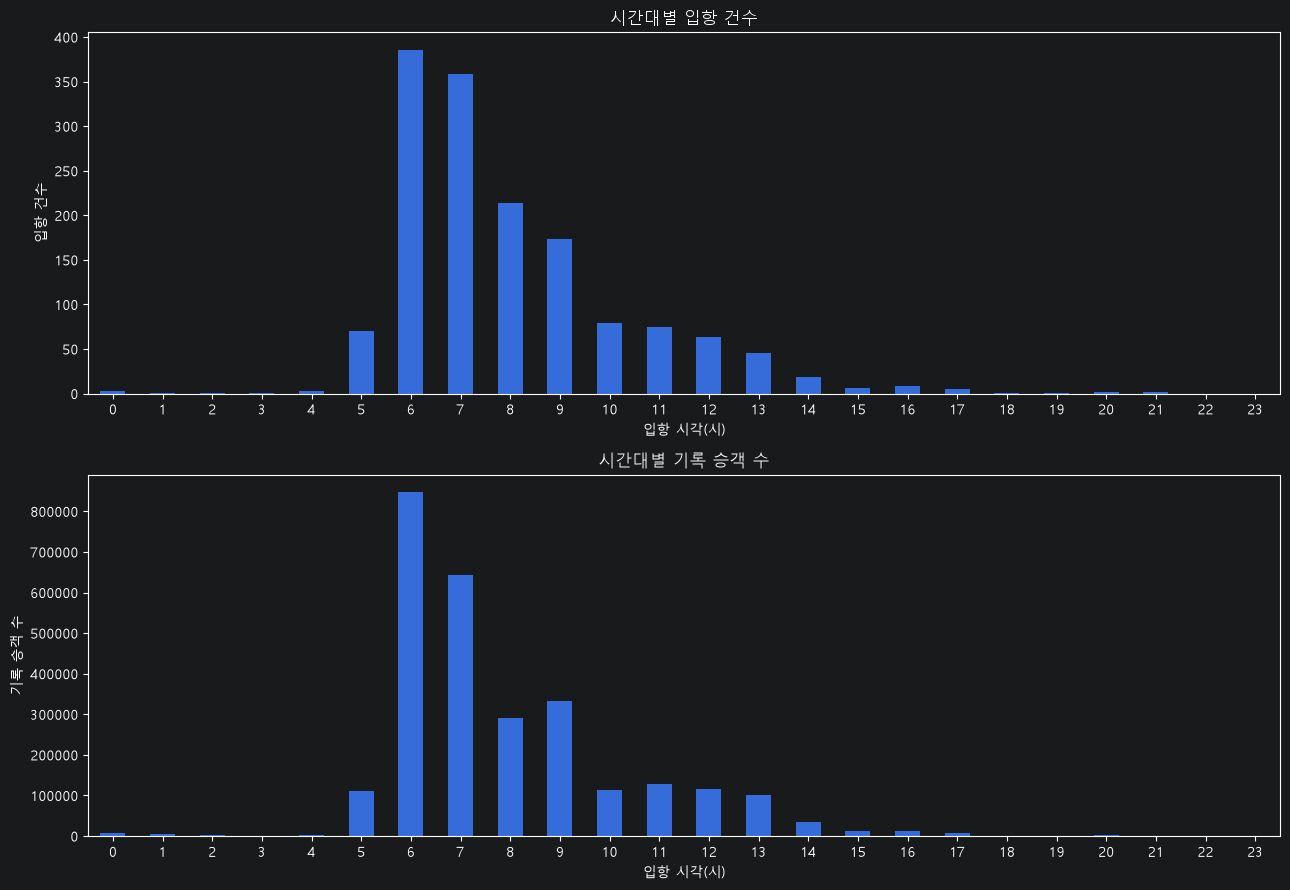

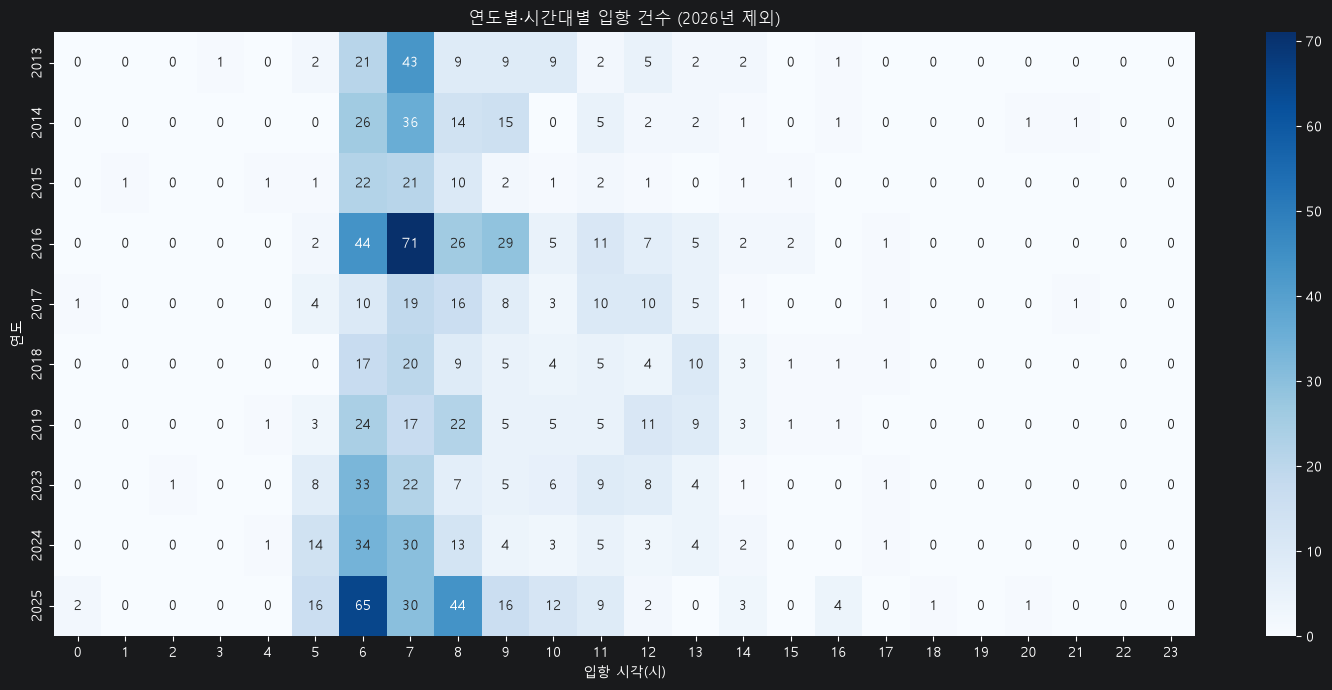


=== 선석별 입항 건수 ===
계선장소.2
북항크루즈터미널 1선석          522
영도크루즈터미널              446
국제여객터미널 14선석          276
북항크루즈터미널 2선석          128
감만부두 3선석(신선대감만터미널)    121
1부두 14선석                7
자성대부두 64선석              4
남외항 N-4박지               4
남외항 N-5박지               2
감만부두 2선석(신선대감만터미널)      2
감만부두 4선석(신선대감만터미널)      1
국제여객터미널 13선석            1
국제여객터미널 10선석            1
수영박지(집단박지)              1
신선대부두 5선석               1
신선대부두 2선석               1
dtype: int64


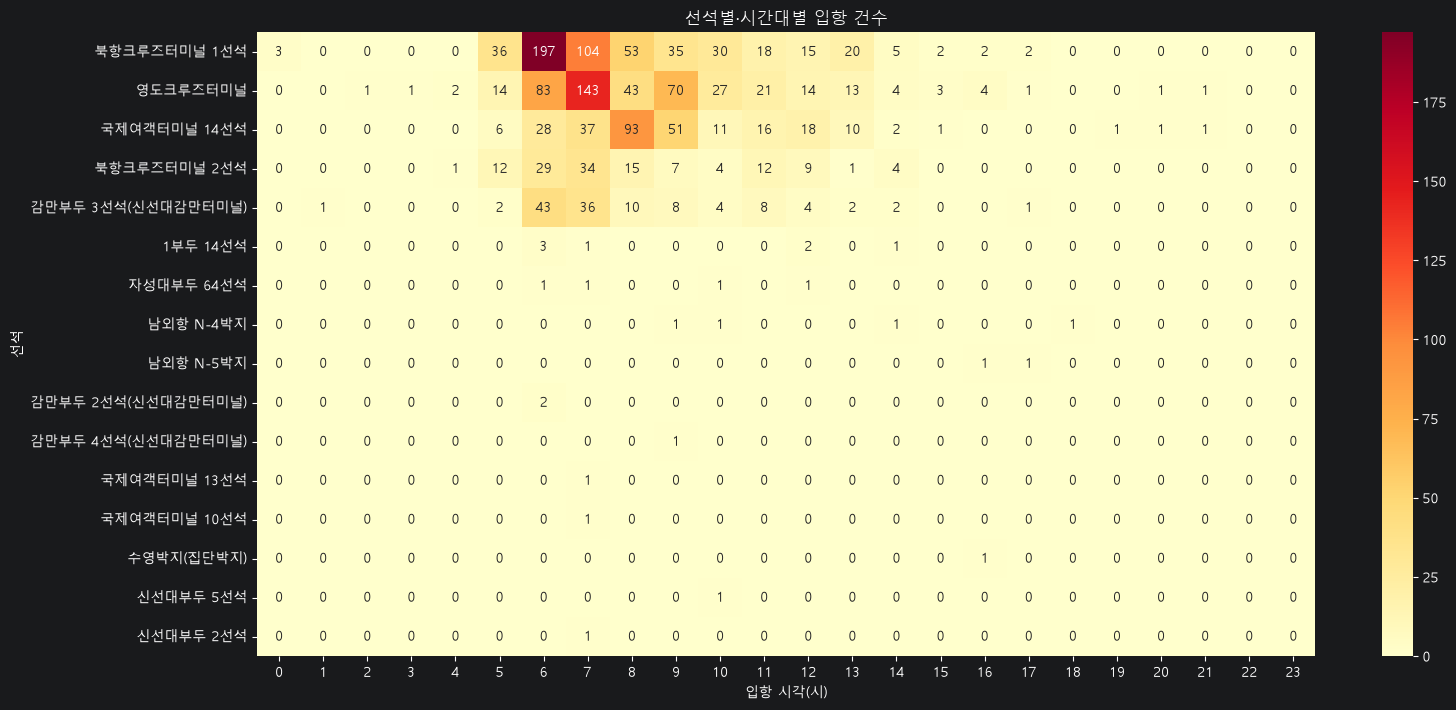


집계 파일 저장 완료


In [50]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 그래프 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# --------------------------------------------------
# 1. 입항 데이터 추출
# --------------------------------------------------
# 기존 df가 이미 존재한다고 가정합니다.
arrival = df[df["입출"].astype(str).str.strip() == "입항"].copy()

# 날짜·시간 변환
arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시"], errors="coerce"
)

# 승객 수 숫자 변환
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

# 시간 관련 변수 생성
arrival = arrival.dropna(subset=["입항일시_dt"]).copy()
arrival["연도"] = arrival["입항일시_dt"].dt.year
arrival["월"] = arrival["입항일시_dt"].dt.month
arrival["요일"] = arrival["입항일시_dt"].dt.dayofweek
arrival["시간"] = arrival["입항일시_dt"].dt.hour

요일명 = {
    0: "월", 1: "화", 2: "수", 3: "목",
    4: "금", 5: "토", 6: "일"
}
arrival["요일명"] = arrival["요일"].map(요일명)

# 선석 컬럼 자동 탐색
berth_candidates = [
    "계선장소.2", "계선장소.1", "계선장소"
]
berth_col = next(
    (col for col in berth_candidates if col in arrival.columns),
    None
)

print("입항 데이터 행 수:", len(arrival))
print("선석 컬럼:", berth_col)
print("분석 기간:",
      arrival["입항일시_dt"].min(),
      "~",
      arrival["입항일시_dt"].max())

if berth_col is None:
    print("선석 컬럼을 찾지 못했습니다.")
    print("계선장소 관련 컬럼:",
          [c for c in arrival.columns if "계선장소" in c])


# --------------------------------------------------
# 2. 시간대별 입항 건수 및 기록 승객 수
# --------------------------------------------------
hourly = (
    arrival.groupby("시간")
    .agg(
        입항건수=("입항일시_dt", "size"),
        기록승객수=("승객", "sum"),
        승객기록건수=("승객", "count")
    )
    .reindex(range(24), fill_value=0)
)

print("\n=== 시간대별 입항 및 승객 집계 ===")
print(hourly)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

hourly["입항건수"].plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("시간대별 입항 건수")
axes[0].set_xlabel("입항 시각(시)")
axes[0].set_ylabel("입항 건수")

hourly["기록승객수"].plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_title("시간대별 기록 승객 수")
axes[1].set_xlabel("입항 시각(시)")
axes[1].set_ylabel("기록 승객 수")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. 연도별·시간대별 입항 패턴
#    2026년은 10월 16일까지의 부분 자료이므로 제외
# --------------------------------------------------
historical = arrival[arrival["연도"] < 2026].copy()

year_hour = pd.crosstab(
    historical["연도"],
    historical["시간"]
).reindex(columns=range(24), fill_value=0)

plt.figure(figsize=(15, 7))
sns.heatmap(
    year_hour,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("연도별·시간대별 입항 건수 (2026년 제외)")
plt.xlabel("입항 시각(시)")
plt.ylabel("연도")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. 선석별·시간대별 입항 건수
# --------------------------------------------------
if berth_col is not None:
    berth_hour = pd.crosstab(
        arrival[berth_col].fillna("미상"),
        arrival["시간"]
    ).reindex(columns=range(24), fill_value=0)

    # 입항 건수가 많은 선석부터 표시
    berth_hour = berth_hour.loc[
        berth_hour.sum(axis=1).sort_values(ascending=False).index
    ]

    print("\n=== 선석별 입항 건수 ===")
    print(berth_hour.sum(axis=1))

    plt.figure(figsize=(16, max(6, len(berth_hour) * 0.45)))
    sns.heatmap(
        berth_hour,
        annot=True,
        fmt="d",
        cmap="YlOrRd"
    )
    plt.title("선석별·시간대별 입항 건수")
    plt.xlabel("입항 시각(시)")
    plt.ylabel("선석")
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 5. 분석 결과 저장
# --------------------------------------------------
hourly.to_csv(
    "시간대별_입항_승객_집계.csv",
    encoding="utf-8-sig"
)

if berth_col is not None:
    berth_hour.to_csv(
        "선석별_시간대별_입항_집계.csv",
        encoding="utf-8-sig"
    )

print("\n집계 파일 저장 완료")


In [51]:

# 선석별 입항 집중 시간대 확인
peak_rows = []

for berth, row in berth_hour.iterrows():
    total = row.sum()
    peak_hours = row.sort_values(ascending=False).head(3)

    peak_rows.append({
        "선석": berth,
        "전체입항건수": total,
        "06~08시입항건수": row.reindex([6, 7, 8], fill_value=0).sum(),
        "06~08시비중(%)": round(
            row.reindex([6, 7, 8], fill_value=0).sum()
            / total * 100, 1
        ) if total else 0,
        "입항집중시간대": ", ".join(
            f"{int(hour)}시({int(count)}건)"
            for hour, count in peak_hours.items()
        )
    })

berth_summary = pd.DataFrame(peak_rows)
berth_summary = berth_summary.sort_values(
    "전체입항건수", ascending=False
)

print(berth_summary.to_string(index=False))


                선석  전체입항건수  06~08시입항건수  06~08시비중(%)                     입항집중시간대
      북항크루즈터미널 1선석     522         354         67.8 6시(197건), 7시(104건), 8시(53건)
          영도크루즈터미널     446         269         60.3  7시(143건), 6시(83건), 9시(70건)
      국제여객터미널 14선석     276         158         57.2   8시(93건), 9시(51건), 7시(37건)
      북항크루즈터미널 2선석     128          78         60.9   7시(34건), 6시(29건), 8시(15건)
감만부두 3선석(신선대감만터미널)     121          89         73.6   6시(43건), 7시(36건), 8시(10건)
          1부두 14선석       7           4         57.1    6시(3건), 12시(2건), 14시(1건)
        자성대부두 64선석       4           2         50.0     6시(1건), 7시(1건), 12시(1건)
         남외항 N-4박지       4           0          0.0   18시(1건), 14시(1건), 10시(1건)
         남외항 N-5박지       2           0          0.0    16시(1건), 17시(1건), 0시(0건)
감만부두 2선석(신선대감만터미널)       2           2        100.0      6시(2건), 0시(0건), 2시(0건)
감만부두 4선석(신선대감만터미널)       1           0          0.0      9시(1건), 0시(0건), 2시(0건)
      국제여객터미널 13선석       1           1  

In [52]:

# 선석별 기록 승객 규모 및 오전 집중도 비교

berth_passenger = (
    arrival.groupby(berth_col)
    .agg(
        입항건수=("입항일시_dt", "size"),
        승객기록건수=("승객", "count"),
        기록승객수=("승객", "sum"),
        평균기록승객수=("승객", "mean"),
        중앙값기록승객수=("승객", "median")
    )
)

# 오전 6~8시 입항 기록만 추출
morning = arrival[arrival["시간"].between(6, 8)]

morning_summary = (
    morning.groupby(berth_col)
    .agg(
        오전입항건수=("입항일시_dt", "size"),
        오전기록승객수=("승객", "sum"),
        오전승객기록건수=("승객", "count")
    )
)

result = berth_passenger.join(morning_summary, how="left").fillna({
    "오전입항건수": 0,
    "오전기록승객수": 0,
    "오전승객기록건수": 0
})

result["전체 기록 승객 중 오전 비중(%)"] = (
    result["오전기록승객수"]
    / result["기록승객수"].replace(0, float("nan"))
    * 100
).round(1)

result["평균기록승객수"] = result["평균기록승객수"].round(1)
result["중앙값기록승객수"] = result["중앙값기록승객수"].round(1)

result = result.sort_values("입항건수", ascending=False)

print(result.to_string())


                    입항건수  승객기록건수      기록승객수  평균기록승객수  중앙값기록승객수  오전입항건수   오전기록승객수  오전승객기록건수  전체 기록 승객 중 오전 비중(%)
계선장소.2                                                                                                         
북항크루즈터미널 1선석         522     522   911376.0   1745.9    1929.0   354.0  629779.0     354.0                 69.1
영도크루즈터미널             446     446  1060842.0   2378.6    2507.0   269.0  617794.0     269.0                 58.2
국제여객터미널 14선석         276     276   289082.0   1047.4    1048.0   158.0  151301.0     158.0                 52.3
북항크루즈터미널 2선석         128     128    45844.0    358.2     228.5    78.0   31034.0      78.0                 67.7
감만부두 3선석(신선대감만터미널)   121     121   440160.0   3637.7    4172.0    89.0  339942.0      89.0                 77.2
1부두 14선석               7       7     2897.0    413.9     322.0     4.0    1106.0       4.0                 38.2
자성대부두 64선석             4       4     7484.0   1871.0    1777.0     2.0    4234.0       2.0              

In [53]:

import pandas as pd

# 입항 날짜 추출
arrival["입항일자"] = arrival["입항일시_dt"].dt.date

# 1) 날짜별 전체 입항 건수와 기록 승객 수
daily_summary = (
    arrival.groupby("입항일자")
    .agg(
        일별입항건수=("입항일시_dt", "size"),
        일별기록승객수=("승객", "sum"),
        승객기록건수=("승객", "count")
    )
)

# 오전 6~8시 입항 건수와 기록 승객 수
morning = arrival[arrival["시간"].between(6, 8)]

morning_daily = (
    morning.groupby("입항일자")
    .agg(
        오전입항건수=("입항일시_dt", "size"),
        오전기록승객수=("승객", "sum")
    )
)

daily_summary = daily_summary.join(morning_daily, how="left")

daily_summary[
    ["오전입항건수", "오전기록승객수"]
] = daily_summary[
    ["오전입항건수", "오전기록승객수"]
].fillna(0)

# 중복 입항 여부
daily_summary["중복입항일"] = (
    daily_summary["일별입항건수"] >= 2
)

daily_summary["오전중복입항일"] = (
    daily_summary["오전입항건수"] >= 2
)

# 2) 전체 입항일 기준 요약
print("=== 날짜별 입항 요약 ===")
print("입항이 있었던 날짜:", len(daily_summary))
print(
    "2척 이상 입항한 날짜:",
    int(daily_summary["중복입항일"].sum())
)
print(
    "전체 입항일 중 중복 입항일 비중(%):",
    round(daily_summary["중복입항일"].mean() * 100, 1)
)
print(
    "오전 6~8시에 2척 이상 입항한 날짜:",
    int(daily_summary["오전중복입항일"].sum())
)

# 3) 단독 입항일과 중복 입항일 비교
daily_summary["입항유형"] = daily_summary[
    "중복입항일"
].map({
    True: "중복 입항일(2척 이상)",
    False: "단독 입항일(1척)"
})

comparison = (
    daily_summary.groupby("입항유형")
    .agg(
        날짜수=("일별입항건수", "size"),
        평균입항건수=("일별입항건수", "mean"),
        평균기록승객수=("일별기록승객수", "mean"),
        중앙값기록승객수=("일별기록승객수", "median"),
        평균오전입항건수=("오전입항건수", "mean"),
        평균오전기록승객수=("오전기록승객수", "mean")
    )
    .round(1)
)

print("\n=== 단독 입항일 vs 중복 입항일 ===")
print(comparison)

# 4) 오전 6~8시 중복 입항일 상위 사례
morning_overlap = daily_summary[
    daily_summary["오전입항건수"] >= 2
].sort_values(
    ["오전입항건수", "오전기록승객수"],
    ascending=False
)

print("\n=== 오전 중복 입항일 상위 20개 ===")
print(morning_overlap.head(20).to_string())

# 5) 전체 중복 입항일 상위 사례
overlap = daily_summary[
    daily_summary["일별입항건수"] >= 2
].sort_values(
    ["일별입항건수", "일별기록승객수"],
    ascending=False
)

print("\n=== 전체 중복 입항일 상위 20개 ===")
print(overlap.head(20).to_string())

# 결과 저장
daily_summary.to_csv(
    "날짜별_중복입항_분석.csv",
    encoding="utf-8-sig"
)

print("\n날짜별 분석 결과 저장 완료")


=== 날짜별 입항 요약 ===
입항이 있었던 날짜: 1189
2척 이상 입항한 날짜: 273
전체 입항일 중 중복 입항일 비중(%): 23.0
오전 6~8시에 2척 이상 입항한 날짜: 117

=== 단독 입항일 vs 중복 입항일 ===
               날짜수  평균입항건수  평균기록승객수  중앙값기록승객수  평균오전입항건수  평균오전기록승객수
입항유형                                                              
단독 입항일(1척)     916     1.0   1883.6    1923.5       0.6     1236.7
중복 입항일(2척 이상)  273     2.2   3836.4    3652.0       1.4     2376.4

=== 오전 중복 입항일 상위 20개 ===
            일별입항건수  일별기록승객수  승객기록건수  오전입항건수  오전기록승객수  중복입항일  오전중복입항일           입항유형
입항일자                                                                               
2016-06-01       3   8385.0       3     3.0   8385.0   True     True  중복 입항일(2척 이상)
2026-05-04       3   5906.0       3     3.0   5906.0   True     True  중복 입항일(2척 이상)
2026-05-23       3   5378.0       3     3.0   5378.0   True     True  중복 입항일(2척 이상)
2019-04-16       3   3971.0       3     3.0   3971.0   True     True  중복 입항일(2척 이상)
2025-12-02       3   3643.0       3     3.0   3643.0   True     True

In [54]:

# 1) 선박명 컬럼 확인
print("선명 관련 컬럼:",
      [c for c in arrival.columns if "선명" in c])

# 일반적인 원본 컬럼명 사용
vessel_col = next(
    (c for c in ["선명", "선명.1"] if c in arrival.columns),
    None
)

# 2) 입항 시각순으로 정렬
cols = [
    "입항일시_dt", "입항일자", "시간",
    berth_col, "승객"
]

if vessel_col is not None:
    cols.insert(1, vessel_col)

calls = arrival[cols].copy()
calls = calls.sort_values("입항일시_dt")

# 3) 동일 날짜·동일 시각에 2척 이상 입항한 사례
calls["동일시각입항건수"] = (
    calls.groupby(["입항일자", "입항일시_dt"])["입항일시_dt"]
    .transform("size")
)

same_time = calls[
    calls["동일시각입항건수"] >= 2
].copy()

print("\n=== 동일 날짜·동일 시각 중복 입항 ===")
print("해당 입항 기록 수:", len(same_time))
print(same_time.to_string(index=False))

# 4) 입항이 3건 이상인 날짜의 개별 선박 기록 확인
busy_dates = daily_summary[
    daily_summary["일별입항건수"] >= 3
].sort_values(
    "일별기록승객수", ascending=False
).head(10).index

busy_calls = calls[
    calls["입항일자"].isin(busy_dates)
].sort_values(["입항일자", "입항일시_dt"])

print("\n=== 입항 3건 이상 날짜의 개별 기록 ===")
print(busy_calls.to_string(index=False))

# 5) 2026년 10월 13일 사례 별도 확인
case_date = pd.to_datetime("2026-10-13").date()

print("\n=== 2026년 10월 13일 입항 기록 ===")
print(
    calls[calls["입항일자"] == case_date]
    .to_string(index=False)
)


선명 관련 컬럼: ['선명']

=== 동일 날짜·동일 시각 중복 입항 ===
해당 입항 기록 수: 37
            입항일시_dt                  선명       입항일자  시간             계선장소.2     승객  동일시각입항건수
2016-05-02 12:00:00    DIAMOND PRINCESS 2016-05-02  12           영도크루즈터미널 2867.0         2
2016-05-02 12:00:00           LE SOLEAL 2016-05-02  12       북항크루즈터미널 2선석  226.0         2
2016-06-01 08:00:00 MARINER OF THE SEAS 2016-06-01   8           영도크루즈터미널 3495.0         2
2016-06-01 08:00:00  LEGEND OF THE SEAS 2016-06-01   8       북항크루즈터미널 1선석 1929.0         2
2016-06-11 07:00:00  LEGEND OF THE SEAS 2016-06-11   7 감만부두 3선석(신선대감만터미널) 2038.0         2
2016-06-11 07:00:00       COSTA FORTUNA 2016-06-11   7           영도크루즈터미널 2957.0         2
2016-08-08 07:00:00      COSTA VICTORIA 2016-08-08   7       국제여객터미널 14선석 1377.0         2
2016-08-08 07:00:00     CHINESE TAISHAN 2016-08-08   7           영도크루즈터미널  474.0         2
2016-09-04 07:30:00 OVATION OF THE SEAS 2016-09-04   7 감만부두 3선석(신선대감만터미널) 3925.0         2
2016-09-04 07:30:00       COSTA

In [55]:

from itertools import combinations

# 입항 기록 정리
calls = arrival.copy()
calls["입항일자"] = calls["입항일시_dt"].dt.date
calls["승객"] = pd.to_numeric(calls["승객"], errors="coerce")

# 같은 날짜 내 모든 선박 쌍의 입항 간격 계산
pairs = []

for date, group in calls.groupby("입항일자"):
    group = group.sort_values("입항일시_dt")
    records = group.to_dict("records")

    for a, b in combinations(records, 2):
        gap = (
            b["입항일시_dt"] - a["입항일시_dt"]
        ).total_seconds() / 60

        # 같은 날의 선박 중 입항 간격이 120분 이내인 쌍
        if 0 <= gap <= 120:
            passengers = [a["승객"], b["승객"]]

            pairs.append({
                "입항일자": date,
                "선박1": a["선명"],
                "입항시각1": a["입항일시_dt"],
                "선석1": a[berth_col],
                "기록승객1": a["승객"],
                "선박2": b["선명"],
                "입항시각2": b["입항일시_dt"],
                "선석2": b[berth_col],
                "기록승객2": b["승객"],
                "입항간격_분": gap,
                "두선박_기록승객합계": (
                    sum(passengers)
                    if pd.notna(passengers).all()
                    else float("nan")
                )
            })

pair_df = pd.DataFrame(pairs)

if pair_df.empty:
    print("입항 간격 120분 이내인 선박 쌍이 없습니다.")
else:
    # 1) 간격별 선박 쌍 수
    print("=== 입항 간격별 선박 쌍 ===")
    for minutes in [30, 60, 120]:
        subset = pair_df[
            pair_df["입항간격_분"] <= minutes
        ]
        print(f"{minutes}분 이내: {len(subset)}쌍")

    # 2) 60분 이내 입항 사례
    within_60 = pair_df[
        pair_df["입항간격_분"] <= 60
    ].sort_values(
        ["입항일자", "입항시각1", "입항시각2"]
    )

    print("\n=== 60분 이내 입항 사례 ===")
    print(within_60.to_string(index=False))

    # 3) 기록 승객 합계가 큰 사례
    print("\n=== 기록 승객 합계 상위 15쌍 ===")
    print(
        pair_df.sort_values(
            "두선박_기록승객합계",
            ascending=False
        ).head(15).to_string(index=False)
    )

    # 4) 파일 저장
    pair_df.to_csv(
        "크루즈_입항간격_선박쌍.csv",
        index=False,
        encoding="utf-8-sig"
    )
    print("\n분석 결과 저장 완료")


=== 입항 간격별 선박 쌍 ===
30분 이내: 65쌍
60분 이내: 139쌍
120분 이내: 220쌍

=== 60분 이내 입항 사례 ===
      입항일자                            선박1               입항시각1                선석1  기록승객1                   선박2               입항시각2                선석2  기록승객2  입항간격_분  두선박_기록승객합계
2013-04-30                  SILVER SHADOW 2013-04-30 07:40:00           1부두 14선석  350.0   VOYAGER OF THE SEAS 2013-04-30 07:50:00           영도크루즈터미널 3124.0    10.0      3474.0
2013-08-29                  PACIFIC VENUS 2013-08-29 06:00:00           1부두 14선석  305.0       COSTA ATLANTICA 2013-08-29 07:00:00           영도크루즈터미널 2634.0    60.0      2939.0
2014-03-28                            볼렌담 2014-03-28 06:30:00           영도크루즈터미널 1286.0       COSTA ATLANTICA 2014-03-28 07:00:00 감만부두 3선석(신선대감만터미널) 2649.0    30.0      3935.0
2014-04-27                   SUN PRINCESS 2014-04-27 06:00:00 감만부두 3선석(신선대감만터미널) 1914.0   MARINER OF THE SEAS 2014-04-27 07:00:00           영도크루즈터미널 2553.0    60.0      4467.0
2014-05-10                COSTA ATLANTI

In [58]:
import pandas as pd

# 1. 데이터 불러오기
df = pd.read_csv("./data/i.csv", encoding="euc-kr")

# 2. 입항 데이터만 추출
arrival = df[
    df["입출"].astype(str).str.strip() == "입항"
].copy()

# 3. 날짜 및 승객 수 전처리
arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시"],
    errors="coerce"
)

arrival["승객"] = pd.to_numeric(
    arrival["승객"],
    errors="coerce"
)

arrival = arrival.dropna(subset=["입항일시_dt"])

arrival["입항일자"] = arrival["입항일시_dt"].dt.date
arrival["입항시간"] = arrival["입항일시_dt"].dt.hour

# 4. 날짜별 입항 건수 및 기록 승객 합계
daily = (
    arrival.groupby("입항일자")
    .agg(
        입항건수=("입항일시_dt", "size"),
        기록승객수=("승객", "sum"),
        승객기록건수=("승객", "count"),
        입항시작시각=("입항일시_dt", "min"),
        입항종료시각=("입항일시_dt", "max")
    )
    .reset_index()
)

# 기록 승객 수가 결측인 경우 합계를 0으로 표시하지 않도록 보정
daily.loc[daily["승객기록건수"] == 0, "기록승객수"] = pd.NA

# 5. 입항 건수별 날짜 수
daily["입항건수구분"] = daily["입항건수"].apply(
    lambda x: "1척" if x == 1
    else "2척" if x == 2
    else "3척 이상"
)

print("\n=== 날짜별 입항 건수 분포 ===")
print(
    daily["입항건수구분"]
    .value_counts()
    .reindex(["1척", "2척", "3척 이상"], fill_value=0)
)

# 6. 두 척 이상 입항한 날짜의 비율
multi = daily[daily["입항건수"] >= 2]

print("\n=== 입항 집중도 요약 ===")
print(f"입항 기록이 있는 날짜: {len(daily):,}일")
print(f"2척 이상 입항한 날짜: {len(multi):,}일")

if len(daily) > 0:
    print(
        f"2척 이상 입항일 비율: "
        f"{len(multi) / len(daily) * 100:.2f}%"
    )

# 7. 입항 건수 상위 날짜
print("\n=== 입항 건수 상위 15일 ===")
print(
    daily.sort_values(
        ["입항건수", "기록승객수"],
        ascending=[False, False]
    ).head(15).to_string(index=False)
)

# 8. 기록 승객 합계 상위 날짜
print("\n=== 기록 승객 합계 상위 15일 ===")
print(
    daily.sort_values(
        "기록승객수",
        ascending=False,
        na_position="last"
    ).head(15).to_string(index=False)
)

# 9. 결과 저장
daily.to_csv(
    "날짜별_크루즈_입항집중도.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n분석 결과를 날짜별_크루즈_입항집중도.csv 파일로 저장했습니다.")


=== 날짜별 입항 건수 분포 ===
입항건수구분
1척       916
2척       220
3척 이상     53
Name: count, dtype: int64

=== 입항 집중도 요약 ===
입항 기록이 있는 날짜: 1,189일
2척 이상 입항한 날짜: 273일
2척 이상 입항일 비율: 22.96%

=== 입항 건수 상위 15일 ===
      입항일자  입항건수  기록승객수  승객기록건수              입항시작시각              입항종료시각 입항건수구분
2026-10-13     4 7731.0       4 2026-10-13 06:00:00 2026-10-13 09:00:00  3척 이상
2026-09-29     4 4761.0       4 2026-09-29 09:00:00 2026-09-29 09:49:00  3척 이상
2026-07-07     4 4206.0       4 2026-07-07 06:28:00 2026-07-07 10:00:00  3척 이상
2016-06-01     3 8385.0       3 2016-06-01 07:00:00 2016-06-01 08:00:00  3척 이상
2026-08-25     3 7832.0       3 2026-08-25 06:34:00 2026-08-25 09:00:00  3척 이상
2025-04-03     3 7761.0       3 2025-04-03 05:30:00 2025-04-03 06:30:00  3척 이상
2026-09-18     3 7721.0       3 2026-09-18 06:00:00 2026-09-18 12:00:00  3척 이상
2026-04-04     3 7286.0       3 2026-04-04 05:30:00 2026-04-04 09:00:00  3척 이상
2026-05-26     3 7172.0       3 2026-05-26 05:50:00 2026-05-26 11:00:00  3척 이상
2014-06-02    

In [59]:
import pandas as pd

# 기존 arrival 데이터프레임을 사용합니다.
# 없으면 앞서 작성한 입항 데이터 전처리 코드를 먼저 실행하세요.

arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시_dt"], errors="coerce"
)
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

arrival = arrival.dropna(subset=["입항일시_dt"]).copy()
arrival = arrival.sort_values("입항일시_dt")

# 입항일자 생성
arrival["입항일자"] = arrival["입항일시_dt"].dt.date

def find_peak_window(group, window_minutes=60):
    """하루 안에서 지정된 시간 이내에 입항한 선박이
    가장 많이 모인 구간을 찾습니다."""
    group = group.sort_values("입항일시_dt").reset_index(drop=True)

    best = None
    j = 0

    for i in range(len(group)):
        start = group.loc[i, "입항일시_dt"]
        limit = start + pd.Timedelta(minutes=window_minutes)

        while (
            j < len(group)
            and group.loc[j, "입항일시_dt"] <= limit
        ):
            j += 1

        # i부터 j-1까지가 해당 구간에 포함되는 선박
        subset = group.iloc[i:j]
        calls = len(subset)
        passengers = subset["승객"].sum(min_count=1)

        candidate = {
            "구간시작": start,
            "구간종료": subset["입항일시_dt"].max(),
            "구간내입항건수": calls,
            "구간내기록승객합계": passengers,
            "구간내선박": ", ".join(
                subset["선명"].fillna("선명 미상").astype(str)
            ) if "선명" in subset.columns else ""
        }

        # 입항 건수가 우선, 동률이면 기록 승객 합계가 큰 구간
        if best is None:
            best = candidate
        else:
            old_passengers = best["구간내기록승객합계"]
            new_passengers = candidate["구간내기록승객합계"]

            old_passengers = (
                old_passengers if pd.notna(old_passengers) else -1
            )
            new_passengers = (
                new_passengers if pd.notna(new_passengers) else -1
            )

            if (
                candidate["구간내입항건수"] > best["구간내입항건수"]
                or (
                    candidate["구간내입항건수"] == best["구간내입항건수"]
                    and new_passengers > old_passengers
                )
            ):
                best = candidate

    return pd.Series(best)


# 날짜별 최대 집중 구간 계산
peak = (
    arrival.groupby("입항일자", group_keys=False)
    .apply(find_peak_window, window_minutes=60)
    .reset_index()
)

print("\n=== 60분 내 입항 집중 상위 15일 ===")
print(
    peak.sort_values(
        ["구간내입항건수", "구간내기록승객합계"],
        ascending=[False, False]
    ).head(15).to_string(index=False)
)

# 결과 저장
peak.to_csv(
    "60분내_입항집중_분석.csv",
    index=False,
    encoding="utf-8-sig"
)


=== 60분 내 입항 집중 상위 15일 ===
      입항일자                구간시작                구간종료  구간내입항건수  구간내기록승객합계                                                                구간내선박
2026-09-29 2026-09-29 09:00:00 2026-09-29 09:49:00        4     4761.0 MITSUI OCEAN FUJI, ADORA MEDITERRANEA, EASTERN VENUS, STAR NAVIGATOR
2016-06-01 2016-06-01 07:00:00 2016-06-01 08:00:00        3     8385.0           SAPPHIRE PRINCESS, MARINER OF THE SEAS, LEGEND OF THE SEAS
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00        3     7761.0                         QUEEN ELIZABETH, COSTA SERENA, MEIN SCHIFF 6
2026-03-24 2026-03-24 05:30:00 2026-03-24 06:30:00        3     4425.0                                  MEIN SCHIFF 6, LE SOLEAL, WESTERDAM
2025-12-02 2025-12-02 06:00:00 2025-12-02 07:00:00        3     3643.0                   COSTA SERENA, ZHAO SHANG YI DUN, MITSUI OCEAN FUJI
2026-04-12 2026-04-12 07:00:00 2026-04-12 08:00:00        3      598.0                          MITSUI OCEAN FUJI, LE SOLEAL, EASTER

In [60]:
import pandas as pd
from itertools import combinations

# 입항 데이터 전처리
arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시_dt"], errors="coerce"
)
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

arrival = arrival.dropna(subset=["입항일시_dt"]).copy()
arrival["입항일자"] = arrival["입항일시_dt"].dt.date

# 선석 및 선박명 열 확인
print("선박명 열:", "선명" if "선명" in arrival.columns else "확인 필요")
print("선석 열:", "계선장소.2" if "계선장소.2" in arrival.columns else "확인 필요")

ship_col = "선명"
berth_col = "계선장소.2"

# 60분 이내 입항 집중 구간 찾기
def find_peak_window(group, window_minutes=60):
    group = group.sort_values("입항일시_dt").reset_index(drop=True)
    best_indices = []
    best_start = None
    best_end = None

    for i in range(len(group)):
        start = group.loc[i, "입항일시_dt"]
        end_limit = start + pd.Timedelta(minutes=window_minutes)

        mask = (
            (group["입항일시_dt"] >= start)
            & (group["입항일시_dt"] <= end_limit)
        )
        indices = group.index[mask].tolist()

        if len(indices) > len(best_indices):
            best_indices = indices
            best_start = start
            best_end = group.loc[indices[-1], "입항일시_dt"]

    result = group.loc[best_indices].copy()
    result["집중구간시작"] = best_start
    result["집중구간종료"] = best_end
    return result


# 날짜별 최대 집중 구간 생성
peak_rows = []

for date, group in arrival.groupby("입항일자"):
    peak_group = find_peak_window(group, window_minutes=60)
    if len(peak_group) >= 2:
        peak_rows.append(peak_group)

peak_detail = pd.concat(peak_rows, ignore_index=True)

# 분석 대상 주요 사례: 집중 구간 내 선박 수가 많은 순
case_summary = (
    peak_detail.groupby("입항일자")
    .agg(
        집중입항건수=(ship_col, "size"),
        집중기록승객합계=("승객", lambda x: x.sum(min_count=1)),
        집중구간시작=("집중구간시작", "first"),
        집중구간종료=("집중구간종료", "first")
    )
    .reset_index()
)

top_cases = case_summary.sort_values(
    ["집중입항건수", "집중기록승객합계"],
    ascending=[False, False]
).head(15)

print("\n=== 60분 집중 상위 사례 ===")
print(top_cases.to_string(index=False))

# 상위 사례의 선박별 선석 정보
detail = peak_detail[
    peak_detail["입항일자"].isin(top_cases["입항일자"])
].copy()

detail["선석명"] = detail[berth_col].fillna("선석 미상")
detail["선박명"] = detail[ship_col].fillna("선박명 미상")

print("\n=== 집중 사례별 선박 및 선석 ===")
print(
    detail[
        [
            "입항일자",
            "입항일시_dt",
            "선박명",
            "선석명",
            "승객",
            "집중구간시작",
            "집중구간종료"
        ]
    ]
    .sort_values(["입항일자", "입항일시_dt"])
    .to_string(index=False)
)

# 사례별 동일 선석 입항 건수
berth_summary = (
    detail.groupby(["입항일자", "선석명"])
    .agg(
        선박수=("선박명", "size"),
        기록승객합계=("승객", lambda x: x.sum(min_count=1))
    )
    .reset_index()
    .sort_values(
        ["입항일자", "선박수", "기록승객합계"],
        ascending=[True, False, False]
    )
)

print("\n=== 사례별 선석 집중 현황 ===")
print(berth_summary.to_string(index=False))

# 파일 저장
detail.to_csv(
    "60분집중_선박별선석현황.csv",
    index=False,
    encoding="utf-8-sig"
)

berth_summary.to_csv(
    "60분집중_선석별요약.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n분석 결과 CSV 파일 2개를 저장했습니다.")

선박명 열: 선명
선석 열: 계선장소.2

=== 60분 집중 상위 사례 ===
      입항일자  집중입항건수  집중기록승객합계              집중구간시작              집중구간종료
2026-09-29       4    4761.0 2026-09-29 09:00:00 2026-09-29 09:49:00
2016-06-01       3    8385.0 2016-06-01 07:00:00 2016-06-01 08:00:00
2025-04-03       3    7761.0 2025-04-03 05:30:00 2025-04-03 06:30:00
2026-03-24       3    4425.0 2026-03-24 05:30:00 2026-03-24 06:30:00
2025-12-02       3    3643.0 2025-12-02 06:00:00 2025-12-02 07:00:00
2026-04-12       3     598.0 2026-04-12 07:00:00 2026-04-12 08:00:00
2026-08-21       2    8277.0 2026-08-21 06:00:00 2026-08-21 06:00:00
2016-10-19       2    7708.0 2016-10-19 06:00:00 2016-10-19 07:00:00
2016-10-10       2    7575.0 2016-10-10 07:00:00 2016-10-10 08:00:00
2016-08-15       2    7490.0 2016-08-15 07:00:00 2016-08-15 08:00:00
2016-09-04       2    7262.0 2016-09-04 07:30:00 2016-09-04 07:30:00
2026-05-14       2    7221.0 2026-05-14 06:00:00 2026-05-14 06:00:00
2016-07-21       2    7045.0 2016-07-21 07:00:00 2016-07-2

In [61]:
import pandas as pd

# 전처리
arrival["입항일시_dt"] = pd.to_datetime(
    arrival["입항일시_dt"], errors="coerce"
)
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

arrival = arrival.dropna(subset=["입항일시_dt"]).copy()
arrival["입항일자"] = arrival["입항일시_dt"].dt.date
arrival["입항시간"] = arrival["입항일시_dt"].dt.hour
arrival["선석명"] = arrival["계선장소.2"].fillna("선석 미상")
arrival["선박명"] = arrival["선명"].fillna("선박명 미상")

# 날짜별 60분 집중 구간 분석
results = []

for date, group in arrival.groupby("입항일자"):
    group = group.sort_values("입항일시_dt").reset_index(drop=True)

    best = None

    for i in range(len(group)):
        start = group.loc[i, "입항일시_dt"]
        end_limit = start + pd.Timedelta(minutes=60)

        subset = group[
            (group["입항일시_dt"] >= start)
            & (group["입항일시_dt"] <= end_limit)
        ]

        if len(subset) < 2:
            continue

        passenger_sum = subset["승객"].sum(min_count=1)
        berth_count = subset["선석명"].nunique()

        candidate = {
            "입항일자": date,
            "구간시작": start,
            "구간종료": subset["입항일시_dt"].max(),
            "집중입항건수": len(subset),
            "동시대응거점수": berth_count,
            "기록승객합계": passenger_sum,
            "집중선박": ", ".join(subset["선박명"].astype(str)),
            "집중선석": ", ".join(
                sorted(subset["선석명"].astype(str).unique())
            )
        }

        if best is None:
            best = candidate
        elif (
            candidate["집중입항건수"] > best["집중입항건수"]
            or (
                candidate["집중입항건수"] == best["집중입항건수"]
                and (
                    pd.notna(candidate["기록승객합계"])
                    and (
                        pd.isna(best["기록승객합계"])
                        or candidate["기록승객합계"]
                        > best["기록승객합계"]
                    )
                )
            )
        ):
            best = candidate

    if best is not None:
        results.append(best)

peak_df = pd.DataFrame(results)

# 1) 집중 사례 상위 15개
print("\n=== 60분 집중 사례 상위 15개 ===")
print(
    peak_df.sort_values(
        ["집중입항건수", "기록승객합계"],
        ascending=False
    ).head(15).to_string(index=False)
)

# 2) 선석 수별 사례 분포
print("\n=== 집중 사례의 대응 거점 수 분포 ===")
print(
    peak_df["동시대응거점수"]
    .value_counts()
    .sort_index()
    .rename_axis("선석수")
    .to_frame("사례수")
)

# 3) 시간대별 집중 사례 빈도
peak_df["집중시작시간"] = pd.to_datetime(
    peak_df["구간시작"]
).dt.hour

print("\n=== 집중 구간 시작 시간대별 빈도 ===")
print(
    peak_df["집중시작시간"]
    .value_counts()
    .sort_index()
    .rename_axis("시작시간")
    .to_frame("집중사례수")
)

# 결과 저장
peak_df.to_csv(
    "크루즈_60분집중_통합분석.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n저장 완료: 크루즈_60분집중_통합분석.csv")


=== 60분 집중 사례 상위 15개 ===
      입항일자                구간시작                구간종료  집중입항건수  동시대응거점수  기록승객합계                                                                 집중선박                                               집중선석
2026-09-29 2026-09-29 09:00:00 2026-09-29 09:49:00       4        4  4761.0 MITSUI OCEAN FUJI, ADORA MEDITERRANEA, EASTERN VENUS, STAR NAVIGATOR 국제여객터미널 14선석, 북항크루즈터미널 1선석, 북항크루즈터미널 2선석, 영도크루즈터미널
2016-06-01 2016-06-01 07:00:00 2016-06-01 08:00:00       3        3  8385.0           SAPPHIRE PRINCESS, MARINER OF THE SEAS, LEGEND OF THE SEAS         감만부두 3선석(신선대감만터미널), 북항크루즈터미널 1선석, 영도크루즈터미널
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00       3        3  7761.0                         QUEEN ELIZABETH, COSTA SERENA, MEIN SCHIFF 6               국제여객터미널 14선석, 북항크루즈터미널 1선석, 영도크루즈터미널
2026-03-24 2026-03-24 05:30:00 2026-03-24 06:30:00       3        3  4425.0                                  MEIN SCHIFF 6, LE SOLEAL, WESTERDAM               북항크루즈터미널 1선석, 북항크루즈터미널 2선석, 영도크

In [62]:
import pandas as pd

# peak_df에 필요한 열이 있는지 확인
required_cols = [
    "입항일자",
    "집중입항건수",
    "동시대응거점수",
    "기록승객합계"
]

missing = [c for c in required_cols if c not in peak_df.columns]

if missing:
    raise ValueError(f"필요한 열이 없습니다: {missing}")

result = peak_df.copy()

# 초기 시범 분류 기준
def classify_operation(row):
    ships = row["집중입항건수"]

    if ships >= 3:
        return "집중 대응 검토"
    elif ships == 2:
        return "사전 점검"
    else:
        return "일반 모니터링"

result["운영준비분류"] = result.apply(
    classify_operation,
    axis=1
)

# 선석이 여러 곳인 경우 별도 확인 표시
result["복수거점여부"] = result["동시대응거점수"].apply(
    lambda x: "복수 거점" if x >= 2 else "단일 거점"
)

print("\n=== 운영 준비 분류 결과 ===")
print(
    result[
        [
            "입항일자",
            "구간시작",
            "구간종료",
            "집중입항건수",
            "동시대응거점수",
            "기록승객합계",
            "운영준비분류",
            "복수거점여부"
        ]
    ]
    .sort_values(
        ["집중입항건수", "기록승객합계"],
        ascending=False
    )
    .to_string(index=False)
)

print("\n=== 운영 준비 분류별 사례 수 ===")
print(result["운영준비분류"].value_counts())

result.to_csv(
    "크루즈_운영준비_시범분류.csv",
    index=False,
    encoding="utf-8-sig"
)


=== 운영 준비 분류 결과 ===
      입항일자                구간시작                구간종료  집중입항건수  동시대응거점수  기록승객합계   운영준비분류 복수거점여부
2026-09-29 2026-09-29 09:00:00 2026-09-29 09:49:00       4        4  4761.0 집중 대응 검토  복수 거점
2016-06-01 2016-06-01 07:00:00 2016-06-01 08:00:00       3        3  8385.0 집중 대응 검토  복수 거점
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00       3        3  7761.0 집중 대응 검토  복수 거점
2026-03-24 2026-03-24 05:30:00 2026-03-24 06:30:00       3        3  4425.0 집중 대응 검토  복수 거점
2025-12-02 2025-12-02 06:00:00 2025-12-02 07:00:00       3        3  3643.0 집중 대응 검토  복수 거점
2026-04-12 2026-04-12 07:00:00 2026-04-12 08:00:00       3        3   598.0 집중 대응 검토  복수 거점
2026-08-21 2026-08-21 06:00:00 2026-08-21 06:00:00       2        2  8277.0    사전 점검  복수 거점
2016-10-19 2016-10-19 06:00:00 2016-10-19 07:00:00       2        2  7708.0    사전 점검  복수 거점
2016-10-10 2016-10-10 07:00:00 2016-10-10 08:00:00       2        2  7575.0    사전 점검  복수 거점
2016-08-15 2016-08-15 07:00:00 2016-08-15 08:00:00       2 

In [63]:
# 운영 준비 분류의 실제 기준과 분류별 특성 확인
print("=== 분류별 사례 수 ===")
print(
    focus_cases["운영준비분류"]
    .value_counts(dropna=False)
)

print("\n=== 분류별 집중 입항 건수 ===")
print(
    focus_cases.groupby("운영준비분류")["집중입항건수"]
    .describe()
)

print("\n=== 분류별 거점 수 ===")
print(
    focus_cases.groupby("운영준비분류")["동시대응거점수"]
    .value_counts()
    .sort_index()
)

print("\n=== 분류별 기록 승객 합계 ===")
print(
    focus_cases.groupby("운영준비분류")["기록승객합계"]
    .describe()
)

=== 분류별 사례 수 ===


NameError: name 'focus_cases' is not defined

In [64]:
# 현재 정의된 데이터프레임 변수명 확인
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

df (3037, 32)
work (3037, 32)
valid (277, 10)
call_check (1519, 2)
mismatch (1, 2)
matched (3036, 37)
comparison (2, 6)
passenger_pivot (1519, 2)
both (1511, 4)
sample (4, 37)
top_detail (20, 37)
occupancy_df (20890, 3)
occupancy_summary (11, 4)
berth_data (1493, 38)
berth_summary (37, 4)
long_stay_summary (16, 5)
normal_stay (1391, 40)
sensitivity (14, 3)
long_stays (127, 40)
sensitivity_data (1518, 39)
data_main (1493, 39)
scenario_data (1392, 39)
summary (5, 4)
overlap_df (25122, 3)
berth_hourly (24844, 3)
berth_overlap_summary (5, 3)
overlap_cases (278, 6)
summary_all (5, 4)
berth_without_target (1392, 38)
summary_without_target (5, 4)
check (172, 7)
other_overlaps (38, 6)
ships (1493, 6)
pair_overlap (26, 11)
overlap_type_summary (2, 4)
arrival (1518, 37)
daily (1189, 7)
coverage (11, 7)
group (2, 37)
year_daily (289, 6)
daily_ts (3432, 6)
monthly (12, 2)
weekday (7, 2)
model_data (3432, 6)
train (1106, 11)
test (277, 10)
monthly_coverage (119, 5)
arrival_model (1518, 39)
daily_ob

In [65]:
# 운영 준비 분류 결과가 들어 있는 데이터프레임 찾기
for name in ["peak_df", "case_summary", "top_cases", "result"]:
    obj = globals().get(name)

    if obj is not None:
        print(f"\n=== {name}: {obj.shape} ===")
        print(obj.columns.tolist())


=== peak_df: (114, 9) ===
['입항일자', '구간시작', '구간종료', '집중입항건수', '동시대응거점수', '기록승객합계', '집중선박', '집중선석', '집중시작시간']

=== case_summary: (114, 5) ===
['입항일자', '집중입항건수', '집중기록승객합계', '집중구간시작', '집중구간종료']

=== top_cases: (15, 5) ===
['입항일자', '집중입항건수', '집중기록승객합계', '집중구간시작', '집중구간종료']

=== result: (114, 11) ===
['입항일자', '구간시작', '구간종료', '집중입항건수', '동시대응거점수', '기록승객합계', '집중선박', '집중선석', '집중시작시간', '운영준비분류', '복수거점여부']


In [66]:
# 1. 운영 준비 분류별 사례 수
print("=== 분류별 사례 수 ===")
print(result["운영준비분류"].value_counts(dropna=False))

# 2. 분류별 집중 입항 건수
print("\n=== 분류별 집중 입항 건수 ===")
print(
    result.groupby("운영준비분류")["집중입항건수"]
    .describe()
    .round(2)
)

# 3. 분류별 동시대응 거점 수
print("\n=== 분류별 동시대응 거점 수 ===")
print(
    pd.crosstab(
        result["운영준비분류"],
        result["동시대응거점수"],
        margins=True
    )
)

# 4. 분류별 기록 승객 합계
print("\n=== 분류별 기록 승객 합계 ===")
print(
    result.groupby("운영준비분류")["기록승객합계"]
    .describe()
    .round(2)
)

# 5. 기록 승객 합계가 큰 집중 사례 상위 10건
print("\n=== 기록 승객 합계 상위 10건 ===")
print(
    result.nlargest(10, "기록승객합계")[
        [
            "입항일자",
            "구간시작",
            "구간종료",
            "집중입항건수",
            "동시대응거점수",
            "기록승객합계",
            "운영준비분류"
        ]
    ].to_string(index=False)
)

=== 분류별 사례 수 ===
운영준비분류
사전 점검       108
집중 대응 검토      6
Name: count, dtype: int64

=== 분류별 집중 입항 건수 ===
          count  mean   std  min  25%  50%  75%  max
운영준비분류                                              
사전 점검     108.0  2.00  0.00  2.0  2.0  2.0  2.0  2.0
집중 대응 검토    6.0  3.17  0.41  3.0  3.0  3.0  3.0  4.0

=== 분류별 동시대응 거점 수 ===
동시대응거점수   1    2  3  4  All
운영준비분류                     
사전 점검     1  107  0  0  108
집중 대응 검토  0    0  5  1    6
All       1  107  5  1  114

=== 분류별 기록 승객 합계 ===
          count     mean      std    min     25%     50%     75%     max
운영준비분류                                                                  
사전 점검     108.0  3488.62  1969.88  227.0  2354.5  3189.0  4855.0  8277.0
집중 대응 검토    6.0  4928.83  2851.59  598.0  3838.5  4593.0  7011.0  8385.0

=== 기록 승객 합계 상위 10건 ===
      입항일자                구간시작                구간종료  집중입항건수  동시대응거점수  기록승객합계   운영준비분류
2016-06-01 2016-06-01 07:00:00 2016-06-01 08:00:00       3        3  8385.0 집중 대응 검토
2026-08-21 2

In [67]:
import numpy as np
import pandas as pd

# 기록 승객 수 기준: 기존 사전 점검 그룹의 75백분위수
passenger_threshold = (
    result.loc[
        result["집중입항건수"] == 2,
        "기록승객합계"
    ].quantile(0.75)
)

def classify_improved(row):
    ships = row["집중입항건수"]
    passengers = row["기록승객합계"]

    if ships >= 3:
        return "집중 대응 검토"
    elif pd.notna(passengers) and passengers >= passenger_threshold:
        return "승객 규모 추가 점검"
    else:
        return "일반 사전 점검"

result["개선분류"] = result.apply(classify_improved, axis=1)

print(f"기록 승객 수 기준값: {passenger_threshold:.0f}명")

print("\n=== 개선 분류별 사례 수 ===")
print(result["개선분류"].value_counts())

print("\n=== 개선 분류별 기록 승객 통계 ===")
print(
    result.groupby("개선분류")["기록승객합계"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(1)
)

print("\n=== 승객 규모 추가 점검 사례 ===")
print(
    result.loc[
        result["개선분류"] == "승객 규모 추가 점검",
        [
            "입항일자",
            "구간시작",
            "구간종료",
            "집중입항건수",
            "동시대응거점수",
            "기록승객합계"
        ]
    ]
    .sort_values("기록승객합계", ascending=False)
    .to_string(index=False)
)

기록 승객 수 기준값: 4855명

=== 개선 분류별 사례 수 ===
개선분류
일반 사전 점검       81
승객 규모 추가 점검    27
집중 대응 검토        6
Name: count, dtype: int64

=== 개선 분류별 기록 승객 통계 ===
             count    mean  median     min     max
개선분류                                              
승객 규모 추가 점검     27  6111.9  5668.0  4870.0  8277.0
일반 사전 점검        81  2614.2  2714.0   227.0  4850.0
집중 대응 검토         6  4928.8  4593.0   598.0  8385.0

=== 승객 규모 추가 점검 사례 ===
      입항일자                구간시작                구간종료  집중입항건수  동시대응거점수  기록승객합계
2026-08-21 2026-08-21 06:00:00 2026-08-21 06:00:00       2        2  8277.0
2016-10-19 2016-10-19 06:00:00 2016-10-19 07:00:00       2        2  7708.0
2016-10-10 2016-10-10 07:00:00 2016-10-10 08:00:00       2        2  7575.0
2016-08-15 2016-08-15 07:00:00 2016-08-15 08:00:00       2        2  7490.0
2016-09-04 2016-09-04 07:30:00 2016-09-04 07:30:00       2        2  7262.0
2026-05-14 2026-05-14 06:00:00 2026-05-14 06:00:00       2        2  7221.0
2016-07-21 2016-07-21 07:00:00 2016-07-

In [68]:
import pandas as pd

# 집중 사례별 선석 문자열을 개별 선석으로 분리
berth_cases = result[
    ["입항일자", "집중입항건수", "동시대응거점수",
     "기록승객합계", "집중선석"]
].copy()

berth_cases["집중선석"] = (
    berth_cases["집중선석"]
    .fillna("")
    .str.split(", ")
)

berth_cases = berth_cases.explode("집중선석")

berth_cases["집중선석"] = (
    berth_cases["집중선석"].str.strip()
)

berth_cases = berth_cases[
    berth_cases["집중선석"] != ""
].copy()

# 선석별 집중 사례 등장 횟수와 기록 승객 규모 요약
berth_summary = (
    berth_cases
    .groupby("집중선석")
    .agg(
        집중사례등장횟수=("입항일자", "nunique"),
        평균집중입항척수=("집중입항건수", "mean"),
        평균기록승객합계=("기록승객합계", "mean"),
        최대기록승객합계=("기록승객합계", "max")
    )
    .sort_values(
        ["집중사례등장횟수", "평균기록승객합계"],
        ascending=False
    )
)

print("=== 선석별 집중 사례 분석 ===")
print(berth_summary.round(1).to_string())

=== 선석별 집중 사례 분석 ===
                    집중사례등장횟수  평균집중입항척수  평균기록승객합계  최대기록승객합계
집중선석                                                      
북항크루즈터미널 1선석              67       2.1    3065.1    8385.0
영도크루즈터미널                  61       2.1    4443.2    8385.0
북항크루즈터미널 2선석              43       2.1    2590.1    5638.0
국제여객터미널 14선석              36       2.1    3277.2    7761.0
감만부두 3선석(신선대감만터미널)        24       2.0    5475.7    8385.0
1부두 14선석                   2       2.0    3206.5    3474.0
감만부두 2선석(신선대감만터미널)         1       2.0     880.0     880.0


In [69]:
import pandas as pd

# 입항 기록 복사
berth_passenger_check = arrival.copy()

# 필요한 열 정리
berth_passenger_check["승객"] = pd.to_numeric(
    berth_passenger_check["승객"],
    errors="coerce"
)

berth_passenger_check["선석명"] = (
    berth_passenger_check["계선장소.2"]
    .fillna("선석 미상")
    .astype(str)
    .str.strip()
)

# 선석별 기록 승객 규모 집계
berth_passenger_summary = (
    berth_passenger_check
    .groupby("선석명")
    .agg(
        입항건수=("선석명", "size"),
        승객기록건수=("승객", "count"),
        기록승객합계=("승객", "sum"),
        평균기록승객=("승객", "mean"),
        중앙값기록승객=("승객", "median")
    )
    .sort_values("기록승객합계", ascending=False)
)

print("=== 선석별 기록 승객 규모 ===")
print(berth_passenger_summary.round(1).to_string())

=== 선석별 기록 승객 규모 ===
                    입항건수  승객기록건수     기록승객합계  평균기록승객  중앙값기록승객
선석명                                                         
영도크루즈터미널             446     446  1060842.0  2378.6   2507.0
북항크루즈터미널 1선석         522     522   911376.0  1745.9   1929.0
감만부두 3선석(신선대감만터미널)   121     121   440160.0  3637.7   4172.0
국제여객터미널 14선석         276     276   289082.0  1047.4   1048.0
북항크루즈터미널 2선석         128     128    45844.0   358.2    228.5
자성대부두 64선석             4       4     7484.0  1871.0   1777.0
신선대부두 5선석              1       1     3475.0  3475.0   3475.0
감만부두 4선석(신선대감만터미널)     1       1     3032.0  3032.0   3032.0
1부두 14선석               7       7     2897.0   413.9    322.0
신선대부두 2선석              1       1     2329.0  2329.0   2329.0
국제여객터미널 13선석           1       1     1881.0  1881.0   1881.0
국제여객터미널 10선석           1       1     1372.0  1372.0   1372.0
남외항 N-5박지              2       2     1325.0   662.5    662.5
감만부두 2선석(신선대감만터미널)     2       2      780.0   390.0    390.0
수영박

=== 연도별 선석 이용 현황 ===
  연도                선석명  입항건수  승객기록건수   기록승객합계      평균기록승객
2013           1부두 14선석     7       7   2897.0  413.857143
2013          남외항 N-5박지     1       1    429.0  429.000000
2013          신선대부두 2선석     1       1   2329.0 2329.000000
2013          신선대부두 5선석     1       1   3475.0 3475.000000
2013           영도크루즈터미널    92      92 182556.0 1984.304348
2013         자성대부두 64선석     4       4   7484.0 1871.000000
2014 감만부두 3선석(신선대감만터미널)    12      12  27119.0 2259.916667
2014 감만부두 4선석(신선대감만터미널)     1       1   3032.0 3032.000000
2014          남외항 N-4박지     1       1    180.0  180.000000
2014           영도크루즈터미널    90      90 209920.0 2332.444444
2015 감만부두 3선석(신선대감만터미널)    15      15  59482.0 3965.466667
2015       국제여객터미널 14선석     1       1   2015.0 2015.000000
2015           영도크루즈터미널    48      48 100157.0 2086.604167
2016 감만부두 3선석(신선대감만터미널)    67      67 281865.0 4206.940299
2016       국제여객터미널 14선석    57      57  90114.0 1580.947368
2016       북항크루즈터미널 1선석     1      

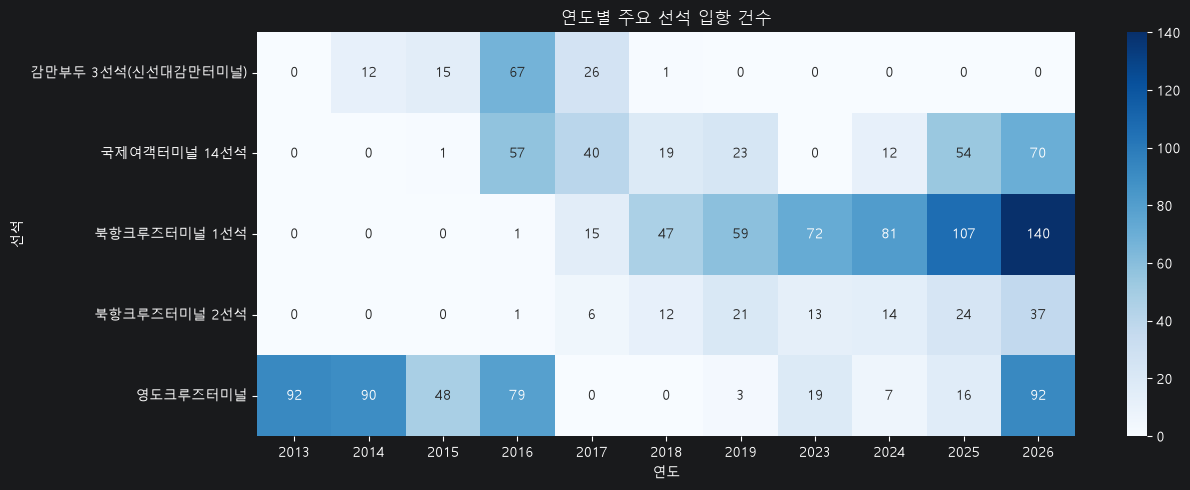

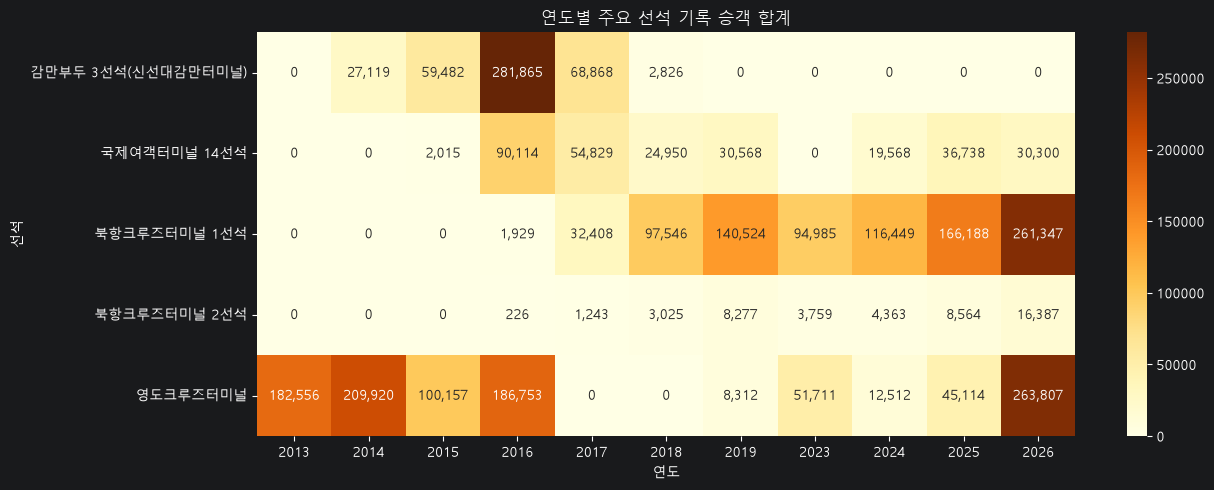


=== 2025년과 2026년 주요 선석 비교 ===
  연도          선석명  입항건수  승객기록건수   기록승객합계  평균기록승객
2025 국제여객터미널 14선석    54      54  36738.0   680.3
2026 국제여객터미널 14선석    70      70  30300.0   432.9
2025 북항크루즈터미널 1선석   107     107 166188.0  1553.2
2026 북항크루즈터미널 1선석   140     140 261347.0  1866.8
2025 북항크루즈터미널 2선석    24      24   8564.0   356.8
2026 북항크루즈터미널 2선석    37      37  16387.0   442.9
2025     영도크루즈터미널    16      16  45114.0  2819.6
2026     영도크루즈터미널    92      92 263807.0  2867.5


In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 입항 데이터 복사
year_berth = arrival.copy()

# 날짜 및 숫자 자료형 정리
year_berth["입항일시_dt"] = pd.to_datetime(
    year_berth["입항일시_dt"], errors="coerce"
)
year_berth["승객"] = pd.to_numeric(
    year_berth["승객"], errors="coerce"
)

year_berth["연도"] = year_berth["입항일시_dt"].dt.year
year_berth["선석명"] = (
    year_berth["계선장소.2"]
    .fillna("선석 미상")
    .astype(str)
    .str.strip()
)

# 연도별·선석별 집계
year_berth_summary = (
    year_berth
    .groupby(["연도", "선석명"])
    .agg(
        입항건수=("선석명", "size"),
        승객기록건수=("승객", "count"),
        기록승객합계=("승객", "sum"),
        평균기록승객=("승객", "mean")
    )
    .reset_index()
)

print("=== 연도별 선석 이용 현황 ===")
print(year_berth_summary.to_string(index=False))

# 주요 선석만 비교
main_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석",
    "감만부두 3선석(신선대감만터미널)",
    "국제여객터미널 14선석",
    "북항크루즈터미널 2선석"
]

main_year_berth = year_berth_summary[
    year_berth_summary["선석명"].isin(main_berths)
].copy()

# 연도별 입항 건수 히트맵
calls_pivot = main_year_berth.pivot(
    index="선석명",
    columns="연도",
    values="입항건수"
).fillna(0)

plt.figure(figsize=(13, 5))
sns.heatmap(
    calls_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)
plt.title("연도별 주요 선석 입항 건수")
plt.xlabel("연도")
plt.ylabel("선석")
plt.tight_layout()
plt.show()

# 연도별 기록 승객 합계 히트맵
passenger_pivot = main_year_berth.pivot(
    index="선석명",
    columns="연도",
    values="기록승객합계"
).fillna(0)

plt.figure(figsize=(13, 5))
sns.heatmap(
    passenger_pivot,
    annot=True,
    fmt=",.0f",
    cmap="YlOrBr"
)
plt.title("연도별 주요 선석 기록 승객 합계")
plt.xlabel("연도")
plt.ylabel("선석")
plt.tight_layout()
plt.show()

# 2025년과 2026년 비교
print("\n=== 2025년과 2026년 주요 선석 비교 ===")
print(
    main_year_berth[
        main_year_berth["연도"].isin([2025, 2026])
    ]
    .sort_values(["선석명", "연도"])
    .round(1)
    .to_string(index=False)
)

In [71]:
import pandas as pd

compare = arrival.copy()

compare["입항일시_dt"] = pd.to_datetime(
    compare["입항일시_dt"], errors="coerce"
)
compare["승객"] = pd.to_numeric(
    compare["승객"], errors="coerce"
)

# 2025년과 2026년의 동일 기간만 추출
start_date = "2025-01-01"
end_date = "2026-10-17"  # 10월 16일까지 포함

compare = compare[
    (compare["입항일시_dt"] >= start_date)
    & (compare["입항일시_dt"] < end_date)
    & (compare["입항일시_dt"].dt.year.isin([2025, 2026]))
].copy()

compare["연도"] = compare["입항일시_dt"].dt.year
compare["월"] = compare["입항일시_dt"].dt.month
compare["선석명"] = (
    compare["계선장소.2"]
    .fillna("선석 미상")
    .astype(str)
    .str.strip()
)

# 주요 선석별 동일 기간 비교
main_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "국제여객터미널 14선석",
    "감만부두 3선석(신선대감만터미널)"
]

comparison = (
    compare[compare["선석명"].isin(main_berths)]
    .groupby(["연도", "선석명"])
    .agg(
        입항건수=("선석명", "size"),
        기록승객합계=("승객", "sum"),
        평균기록승객=("승객", "mean")
    )
    .reset_index()
)

print("=== 2025년·2026년 동일 기간 선석별 비교 ===")
print(comparison.round(1).to_string(index=False))

# 월별 입항 추이
monthly_compare = (
    compare.groupby(["연도", "월"])
    .size()
    .unstack("연도", fill_value=0)
)

print("\n=== 월별 전체 입항 건수 ===")
print(monthly_compare.to_string())

=== 2025년·2026년 동일 기간 선석별 비교 ===
  연도          선석명  입항건수   기록승객합계  평균기록승객
2025 국제여객터미널 14선석    54  36738.0   680.3
2025 북항크루즈터미널 1선석   107 166188.0  1553.2
2025 북항크루즈터미널 2선석    24   8564.0   356.8
2025     영도크루즈터미널    16  45114.0  2819.6
2026 국제여객터미널 14선석    70  30300.0   432.9
2026 북항크루즈터미널 1선석   140 261347.0  1866.8
2026 북항크루즈터미널 2선석    37  16387.0   442.9
2026     영도크루즈터미널    92 263807.0  2867.5

=== 월별 전체 입항 건수 ===
연도  2025  2026
월             
1      9    18
2      5    20
3     17    50
4     35    46
5     28    46
6     13    41
7     10    33
8     14    27
9     17    38
10    19    20
11    23     0
12    15     0


In [72]:
# 2025년과 2026년 동일 기간의 선석별 입항 건수 비교
berth_compare = comparison.pivot(
    index="선석명",
    columns="연도",
    values="입항건수"
).fillna(0)

berth_compare["증감"] = (
    berth_compare[2026] - berth_compare[2025]
)

berth_compare["증감률(%)"] = (
    berth_compare["증감"]
    / berth_compare[2025].replace(0, float("nan"))
    * 100
)

print("=== 선석별 동일 기간 입항 건수 증감 ===")
print(
    berth_compare
    .sort_values("증감", ascending=False)
    .round(1)
    .to_string()
)

=== 선석별 동일 기간 입항 건수 증감 ===
연도            2025  2026  증감  증감률(%)
선석명                                 
영도크루즈터미널        16    92  76   475.0
북항크루즈터미널 1선석   107   140  33    30.8
국제여객터미널 14선석    54    70  16    29.6
북항크루즈터미널 2선석    24    37  13    54.2


In [73]:
import pandas as pd

# 기존 result 데이터 사용
peak_berth = result.copy()

# 날짜 자료형 정리
peak_berth["입항일자"] = pd.to_datetime(
    peak_berth["입항일자"], errors="coerce"
)

# 2025년과 2026년 동일 관측 기간만 선택
peak_berth = peak_berth[
    (peak_berth["입항일자"] >= "2025-01-01")
    & (peak_berth["입항일자"] < "2026-10-17")
    & (peak_berth["입항일자"].dt.year.isin([2025, 2026]))
].copy()

peak_berth["연도"] = peak_berth["입항일자"].dt.year

# 집중 구간에 등장한 선석 목록 분리
peak_berth["집중선석"] = (
    peak_berth["집중선석"]
    .fillna("")
    .astype(str)
    .str.split(", ")
)

peak_berth = peak_berth.explode("집중선석")
peak_berth["집중선석"] = peak_berth["집중선석"].str.strip()

peak_berth = peak_berth[
    peak_berth["집중선석"] != ""
].copy()

# 연도별·선석별 집중 사례 집계
peak_summary = (
    peak_berth
    .groupby(["연도", "집중선석"])
    .agg(
        집중사례등장횟수=("입항일자", "nunique"),
        평균집중입항척수=("집중입항건수", "mean"),
        평균기록승객합계=("기록승객합계", "mean")
    )
    .reset_index()
)

print("=== 연도별 선석 집중 입항 사례 ===")
print(peak_summary.round(1).to_string(index=False))

# 주요 선석 비교표
main_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "국제여객터미널 14선석",
    "감만부두 3선석(신선대감만터미널)"
]

main_peak = peak_summary[
    peak_summary["집중선석"].isin(main_berths)
]

peak_pivot = main_peak.pivot(
    index="집중선석",
    columns="연도",
    values="집중사례등장횟수"
).fillna(0)

# 두 연도 열이 모두 존재하도록 보정
for year in [2025, 2026]:
    if year not in peak_pivot.columns:
        peak_pivot[year] = 0

peak_pivot["증감"] = peak_pivot[2026] - peak_pivot[2025]

print("\n=== 주요 선석 집중 사례 증감 ===")
print(
    peak_pivot[[2025, 2026, "증감"]]
    .sort_values("증감", ascending=False)
    .to_string()
)

=== 연도별 선석 집중 입항 사례 ===
  연도         집중선석  집중사례등장횟수  평균집중입항척수  평균기록승객합계
2025 국제여객터미널 14선석         6       2.2    2917.2
2025 북항크루즈터미널 1선석        16       2.1    2882.8
2025 북항크루즈터미널 2선석        12       2.1    2156.2
2025     영도크루즈터미널         4       2.5    4221.0
2026 국제여객터미널 14선석        14       2.2    2748.2
2026 북항크루즈터미널 1선석        30       2.1    3148.6
2026 북항크루즈터미널 2선석        20       2.2    2887.6
2026     영도크루즈터미널        26       2.2    4147.0

=== 주요 선석 집중 사례 증감 ===
연도            2025  2026  증감
집중선석                        
영도크루즈터미널         4    26  22
북항크루즈터미널 1선석    16    30  14
국제여객터미널 14선석     6    14   8
북항크루즈터미널 2선석    12    20   8


=== 선석별·연도별·월별 집중 사례 ===
        집중선석   연도  월  집중사례수
북항크루즈터미널 1선석 2025  4      7
북항크루즈터미널 1선석 2025  5      3
북항크루즈터미널 1선석 2025  6      1
북항크루즈터미널 1선석 2025  8      2
북항크루즈터미널 1선석 2025 10      1
북항크루즈터미널 1선석 2025 11      1
북항크루즈터미널 1선석 2025 12      1
북항크루즈터미널 1선석 2026  1      1
북항크루즈터미널 1선석 2026  2      1
북항크루즈터미널 1선석 2026  3      5
북항크루즈터미널 1선석 2026  4      5
북항크루즈터미널 1선석 2026  5      5
북항크루즈터미널 1선석 2026  6      3
북항크루즈터미널 1선석 2026  7      2
북항크루즈터미널 1선석 2026  8      3
북항크루즈터미널 1선석 2026  9      3
북항크루즈터미널 1선석 2026 10      2
    영도크루즈터미널 2025  4      3
    영도크루즈터미널 2025 12      1
    영도크루즈터미널 2026  1      1
    영도크루즈터미널 2026  3      3
    영도크루즈터미널 2026  4      4
    영도크루즈터미널 2026  5      4
    영도크루즈터미널 2026  6      2
    영도크루즈터미널 2026  7      4
    영도크루즈터미널 2026  8      3
    영도크루즈터미널 2026  9      2
    영도크루즈터미널 2026 10      3

=== 선석별·연도별·집중 시작 시간 ===
        집중선석   연도  시작시  집중사례수
북항크루즈터미널 1선석 2025    0     16
북항크루즈터미널 1선석 2026    0     30
    영도크루즈터미널 2025    0      4
    영도크루즈터미널 2026

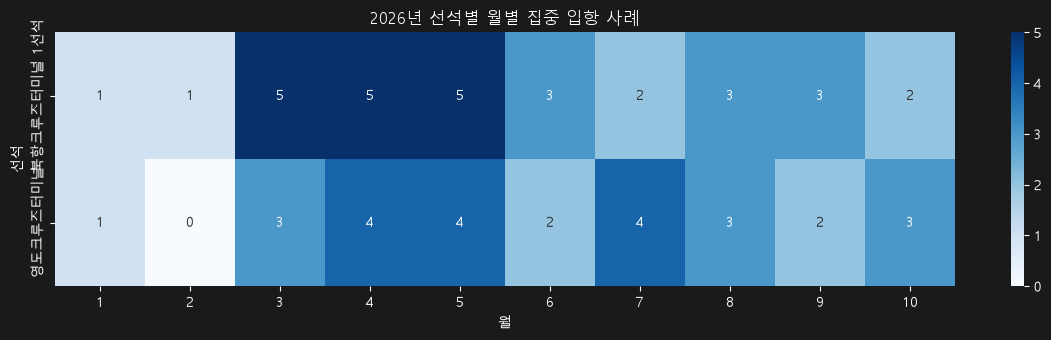

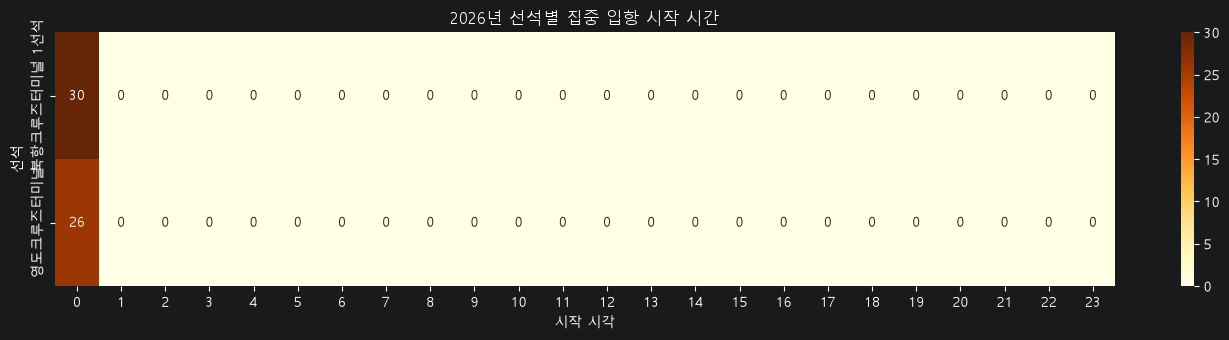

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 기존 result 복사
focus = result.copy()

focus["입항일자"] = pd.to_datetime(
    focus["입항일자"], errors="coerce"
)

# 2025년 및 2026년 동일 관측 기간
focus = focus[
    (focus["입항일자"] >= "2025-01-01")
    & (focus["입항일자"] < "2026-10-17")
    & (focus["입항일자"].dt.year.isin([2025, 2026]))
].copy()

focus["연도"] = focus["입항일자"].dt.year
focus["월"] = focus["입항일자"].dt.month

# 집중 시작 시각에서 시간 추출
focus["집중시작시간"] = pd.to_datetime(
    focus["집중시작시간"], errors="coerce"
)

focus["시작시"] = focus["집중시작시간"].dt.hour

# 분석 대상 선석
target_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석"
]

# 집중선석 문자열을 개별 선석으로 분리
focus["집중선석"] = (
    focus["집중선석"]
    .fillna("")
    .astype(str)
    .str.split(", ")
)

focus = focus.explode("집중선석")
focus["집중선석"] = focus["집중선석"].str.strip()

focus = focus[
    focus["집중선석"].isin(target_berths)
].copy()

# 1. 선석별·월별 집중 사례
monthly_focus = (
    focus.groupby(["집중선석", "연도", "월"])
    .agg(집중사례수=("입항일자", "nunique"))
    .reset_index()
)

print("=== 선석별·연도별·월별 집중 사례 ===")
print(monthly_focus.to_string(index=False))

# 2. 선석별·시작 시간대별 집중 사례
hourly_focus = (
    focus.groupby(["집중선석", "연도", "시작시"])
    .agg(집중사례수=("입항일자", "nunique"))
    .reset_index()
)

print("\n=== 선석별·연도별·집중 시작 시간 ===")
print(hourly_focus.to_string(index=False))

# 3. 히트맵: 선석별 2026년 월별 집중 사례
focus_2026 = focus[focus["연도"] == 2026]

monthly_pivot = focus_2026.pivot_table(
    index="집중선석",
    columns="월",
    values="입항일자",
    aggfunc="nunique",
    fill_value=0
).reindex(columns=range(1, 11), fill_value=0)

plt.figure(figsize=(12, 3.5))
sns.heatmap(
    monthly_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)
plt.title("2026년 선석별 월별 집중 입항 사례")
plt.xlabel("월")
plt.ylabel("선석")
plt.tight_layout()
plt.show()

# 4. 히트맵: 선석별 2026년 집중 시작 시간
hourly_pivot = focus_2026.pivot_table(
    index="집중선석",
    columns="시작시",
    values="입항일자",
    aggfunc="nunique",
    fill_value=0
).reindex(columns=range(24), fill_value=0)

plt.figure(figsize=(14, 3.5))
sns.heatmap(
    hourly_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrBr"
)
plt.title("2026년 선석별 집중 입항 시작 시간")
plt.xlabel("시작 시각")
plt.ylabel("선석")
plt.tight_layout()
plt.show()

In [75]:
import pandas as pd

focus = result.copy()

# 날짜와 시작 시각 정리
focus["입항일자"] = pd.to_datetime(
    focus["입항일자"], errors="coerce"
)
focus["구간시작_dt"] = pd.to_datetime(
    focus["구간시작"], errors="coerce"
)

# 두 연도 모두 1월 1일~10월 16일로 기간 통일
focus = focus[
    (focus["입항일자"] >= "2025-01-01")
    & (focus["입항일자"] < "2026-10-17")
    & (focus["입항일자"].dt.year.isin([2025, 2026]))
    & (focus["입항일자"].dt.month <= 10)
].copy()

focus["연도"] = focus["입항일자"].dt.year
focus["월"] = focus["입항일자"].dt.month

# 구간시작에서 실제 시각 추출
focus["시작시"] = focus["구간시작_dt"].dt.hour

# 분석 대상 선석만 선택
target_berths = [
    "북항크루즈터미널 1선석",
    "영도크루즈터미널"
]

focus["집중선석"] = (
    focus["집중선석"]
    .fillna("")
    .astype(str)
    .str.split(", ")
)

focus = focus.explode("집중선석")
focus["집중선석"] = focus["집중선석"].str.strip()

focus = focus[
    focus["집중선석"].isin(target_berths)
].copy()

# 시간 추출이 제대로 됐는지 먼저 확인
print("=== 구간 시작 시각 확인 ===")
print(
    focus[
        ["입항일자", "구간시작", "구간시작_dt", "시작시", "집중선석"]
    ].head(10).to_string(index=False)
)

# 월별 집중 사례
print("\n=== 선석별·연도별·월별 집중 사례 ===")
print(
    focus.groupby(["집중선석", "연도", "월"])["입항일자"]
    .nunique()
    .rename("집중사례수")
    .reset_index()
    .to_string(index=False)
)

# 시간대별 집중 사례
print("\n=== 선석별·연도별·시작 시간대 ===")
print(
    focus.groupby(["집중선석", "연도", "시작시"])["입항일자"]
    .nunique()
    .rename("집중사례수")
    .reset_index()
    .to_string(index=False)
    .replace("NaN", "시간 확인 필요")
)

=== 구간 시작 시각 확인 ===
      입항일자                구간시작             구간시작_dt  시작시         집중선석
2025-04-03 2025-04-03 05:30:00 2025-04-03 05:30:00    5 북항크루즈터미널 1선석
2025-04-03 2025-04-03 05:30:00 2025-04-03 05:30:00    5     영도크루즈터미널
2025-04-04 2025-04-04 05:30:00 2025-04-04 05:30:00    5 북항크루즈터미널 1선석
2025-04-08 2025-04-08 05:30:00 2025-04-08 05:30:00    5 북항크루즈터미널 1선석
2025-04-08 2025-04-08 05:30:00 2025-04-08 05:30:00    5     영도크루즈터미널
2025-04-14 2025-04-14 06:00:00 2025-04-14 06:00:00    6     영도크루즈터미널
2025-04-15 2025-04-15 05:30:00 2025-04-15 05:30:00    5 북항크루즈터미널 1선석
2025-04-17 2025-04-17 06:30:00 2025-04-17 06:30:00    6 북항크루즈터미널 1선석
2025-04-26 2025-04-26 07:00:00 2025-04-26 07:00:00    7 북항크루즈터미널 1선석
2025-04-30 2025-04-30 10:30:00 2025-04-30 10:30:00   10 북항크루즈터미널 1선석

=== 선석별·연도별·월별 집중 사례 ===
        집중선석   연도  월  집중사례수
북항크루즈터미널 1선석 2025  4      7
북항크루즈터미널 1선석 2025  5      3
북항크루즈터미널 1선석 2025  6      1
북항크루즈터미널 1선석 2025  8      2
북항크루즈터미널 1선석 2025 10      1
북항크루즈터미널 1선석 2026  1      1

In [76]:
import pandas as pd

# 1. 집중 사례 데이터 정리
focus = result.copy()

focus["입항일자"] = pd.to_datetime(
    focus["입항일자"], errors="coerce"
).dt.normalize()

focus["구간시작"] = pd.to_datetime(
    focus["구간시작"], errors="coerce"
)

focus["구간종료"] = pd.to_datetime(
    focus["구간종료"], errors="coerce"
)

focus["연도"] = focus["입항일자"].dt.year

# 2025년과 2026년의 1월 1일~10월 16일
focus = focus[
    (focus["입항일자"] >= "2025-01-01")
    & (focus["입항일자"] < "2026-10-17")
    & (focus["연도"].isin([2025, 2026]))
].copy()

# 두 선석이 포함된 집중 사례만 추출
target_berths = [
    "북항크루즈터미널 1선석",
    "영도크루즈터미널"
]

focus["집중선석목록"] = (
    focus["집중선석"]
    .fillna("")
    .astype(str)
    .str.split(", ")
)

focus = focus[
    focus["집중선석목록"].apply(
        lambda berths: any(b in target_berths for b in berths)
    )
].copy()

print("집중 사례 수:", len(focus))

# 2. 원본 입항 데이터 정리
arrival_detail = arrival.copy()

arrival_detail["입항일시_dt"] = pd.to_datetime(
    arrival_detail["입항일시_dt"], errors="coerce"
)

arrival_detail["승객"] = pd.to_numeric(
    arrival_detail["승객"], errors="coerce"
)

arrival_detail["입항일자"] = (
    arrival_detail["입항일시_dt"].dt.normalize()
)

arrival_detail["선석명"] = (
    arrival_detail["계선장소.2"]
    .fillna("선석 미상")
    .astype(str)
    .str.strip()
)

# 3. 집중 사례와 같은 날짜·시간 구간에 속한 선박 연결
detail_rows = []

for _, case in focus.iterrows():
    same_day = arrival_detail[
        arrival_detail["입항일자"] == case["입항일자"]
    ]

    in_window = same_day[
        (same_day["입항일시_dt"] >= case["구간시작"])
        & (same_day["입항일시_dt"] <= case["구간종료"])
    ].copy()

    if in_window.empty:
        continue

    in_window["집중사례일자"] = case["입항일자"]
    in_window["집중구간시작"] = case["구간시작"]
    in_window["집중구간종료"] = case["구간종료"]
    in_window["집중선박수"] = case["집중입항건수"]

    detail_rows.append(in_window)

if detail_rows:
    focus_detail = pd.concat(detail_rows, ignore_index=True)

    print("\n=== 집중 구간별 선박 상세 ===")
    columns_to_show = [
        "집중사례일자",
        "집중구간시작",
        "집중구간종료",
        "입항일시_dt",
        "선명",
        "선석명",
        "승객"
    ]

    print(
        focus_detail[columns_to_show]
        .sort_values(["집중사례일자", "입항일시_dt"])
        .to_string(index=False)
    )
else:
    print("해당 시간 구간에 일치하는 입항 기록이 없습니다.")

집중 사례 수: 59

=== 집중 구간별 선박 상세 ===
    집중사례일자              집중구간시작              집중구간종료             입항일시_dt                             선명          선석명     승객
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00 2025-04-03 05:30:00                QUEEN ELIZABETH     영도크루즈터미널 1950.0
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00 2025-04-03 06:00:00                   COSTA SERENA 국제여객터미널 14선석 3403.0
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00 2025-04-03 06:30:00                  MEIN SCHIFF 6 북항크루즈터미널 1선석 2408.0
2025-04-04 2025-04-04 05:30:00 2025-04-04 06:30:00 2025-04-04 05:30:00                 SEABOURN QUEST 북항크루즈터미널 2선석  442.0
2025-04-04 2025-04-04 05:30:00 2025-04-04 06:30:00 2025-04-04 06:30:00                        NOORDAM 북항크루즈터미널 1선석 1941.0
2025-04-08 2025-04-08 05:30:00 2025-04-08 05:30:00 2025-04-08 05:30:00               DIAMOND PRINCESS 북항크루즈터미널 1선석 2701.0
2025-04-08 2025-04-08 05:30:00 2025-04-08 05:30:00 2025-04-08 05:30:00                     AIDASTELLA     영도크루즈터

In [77]:
import pandas as pd

target_berths = [
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "영도크루즈터미널",
    "국제여객터미널 14선석"
]

# 1. 2025년과 2026년의 동일한 관측 기간 설정
start_date = pd.Timestamp("2025-01-01")
end_date = pd.Timestamp("2026-10-17")  # 10월 16일까지 포함

# 2. 전체 입항 건수
arr = arrival.copy()
arr["입항일시_dt"] = pd.to_datetime(
    arr["입항일시_dt"], errors="coerce"
)
arr["선석명"] = (
    arr["계선장소.2"]
    .fillna("")
    .astype(str)
    .str.strip()
)

arr = arr[
    (arr["입항일시_dt"] >= start_date)
    & (arr["입항일시_dt"] < end_date)
    & (arr["선석명"].isin(target_berths))
].copy()

arr["연도"] = arr["입항일시_dt"].dt.year

total_calls = (
    arr.groupby(["연도", "선석명"])
    .size()
    .rename("전체입항건수")
)

# 3. 집중 사례 등장 횟수
r = result.copy()
r["입항일자"] = pd.to_datetime(
    r["입항일자"], errors="coerce"
).dt.normalize()

r = r[
    (r["입항일자"] >= start_date)
    & (r["입항일자"] < end_date)
    & (r["입항일자"].dt.year.isin([2025, 2026]))
].copy()

r["연도"] = r["입항일자"].dt.year
r["선석목록"] = (
    r["집중선석"]
    .fillna("")
    .astype(str)
    .str.split(", ")
)

case_rows = []

for _, row in r.iterrows():
    for berth in set(row["선석목록"]):
        if berth in target_berths:
            case_rows.append({
                "연도": row["연도"],
                "선석명": berth,
                "입항일자": row["입항일자"]
            })

case_df = pd.DataFrame(case_rows)

case_counts = (
    case_df.groupby(["연도", "선석명"])["입항일자"]
    .nunique()
    .rename("집중사례수")
)

# 4. 결과 결합 및 비율 계산
comparison = pd.concat(
    [total_calls, case_counts], axis=1
).fillna(0)

comparison["집중사례비율(%)"] = (
    comparison["집중사례수"]
    / comparison["전체입항건수"]
    * 100
)

print("=== 선석별 전체 입항 대비 집중 사례 비율 ===")
print(comparison.round(2).to_string())

=== 선석별 전체 입항 대비 집중 사례 비율 ===
                   전체입항건수  집중사례수  집중사례비율(%)
연도   선석명                                   
2025 국제여객터미널 14선석      54      6      11.11
     북항크루즈터미널 1선석     107     16      14.95
     북항크루즈터미널 2선석      24     12      50.00
     영도크루즈터미널          16      4      25.00
2026 국제여객터미널 14선석      70     14      20.00
     북항크루즈터미널 1선석     140     30      21.43
     북항크루즈터미널 2선석      37     20      54.05
     영도크루즈터미널          92     26      28.26


In [78]:
import pandas as pd

# 1. 집중 사례의 선박별 데이터 정리
d = focus_detail.copy()

d["승객"] = pd.to_numeric(d["승객"], errors="coerce")
d["선석명"] = d["선석명"].fillna("선석 미상").astype(str).str.strip()
d["집중사례일자"] = pd.to_datetime(
    d["집중사례일자"], errors="coerce"
).dt.normalize()

target_berths = [
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "영도크루즈터미널",
    "국제여객터미널 14선석"
]

# 2. 주요 선석만 선택
d = d[d["선석명"].isin(target_berths)].copy()

# 3. 선석별 집중 사례 승객 규모
berth_focus_passengers = (
    d.groupby("선석명")
    .agg(
        집중구간입항척수=("선명", "size"),
        승객기록건수=("승객", "count"),
        집중선박평균승객=("승객", "mean"),
        집중선박중앙값승객=("승객", "median"),
        최대선박기록승객=("승객", "max")
    )
    .sort_values("집중선박평균승객", ascending=False)
)

print("=== 선석별 집중 사례에 포함된 선박의 기록 승객 규모 ===")
print(berth_focus_passengers.round(1).to_string())

# 4. 집중 사례별 선석 내 승객 규모 구간 분류
def passenger_group(x):
    if pd.isna(x):
        return "승객 미상"
    elif x < 500:
        return "500명 미만"
    elif x < 2000:
        return "500~1,999명"
    elif x < 4000:
        return "2,000~3,999명"
    else:
        return "4,000명 이상"

d["선박승객규모"] = d["승객"].apply(passenger_group)

passenger_distribution = pd.crosstab(
    d["선석명"],
    d["선박승객규모"]
)

# 주요 선석 순서 지정
passenger_distribution = passenger_distribution.reindex(
    target_berths
).fillna(0).astype(int)

print("\n=== 선석별 집중 사례 선박의 승객 규모 분포 ===")
print(passenger_distribution.to_string())

=== 선석별 집중 사례에 포함된 선박의 기록 승객 규모 ===
              집중구간입항척수  승객기록건수  집중선박평균승객  집중선박중앙값승객  최대선박기록승객
선석명                                                          
영도크루즈터미널            30      30    2761.7     2439.0    5464.0
북항크루즈터미널 1선석        46      46    1897.0     2196.0    5289.0
국제여객터미널 14선석        18      18     395.1       87.0    3403.0
북항크루즈터미널 2선석        30      30     364.9      225.0    1865.0

=== 선석별 집중 사례 선박의 승객 규모 분포 ===
선박승객규모        2,000~3,999명  4,000명 이상  500~1,999명  500명 미만
선석명                                                       
북항크루즈터미널 1선석            23          3          11        9
북항크루즈터미널 2선석             0          0           8       22
영도크루즈터미널                 8         11           6        5
국제여객터미널 14선석             2          0           0       16


In [82]:
import pandas as pd

target_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "국제여객터미널 14선석"
]

start_date = pd.Timestamp("2025-01-01")
end_date = pd.Timestamp("2026-10-17")  # 10월 16일까지 포함

# 1. 전체 입항 데이터 정리
all_ships = arrival.copy()

all_ships["입항일시_dt"] = pd.to_datetime(
    all_ships["입항일시_dt"], errors="coerce"
)
all_ships["승객"] = pd.to_numeric(
    all_ships["승객"], errors="coerce"
)
all_ships["선석명"] = (
    all_ships["계선장소.2"]
    .fillna("")
    .astype(str)
    .str.strip()
)

all_ships = all_ships[
    (all_ships["입항일시_dt"] >= start_date)
    & (all_ships["입항일시_dt"] < end_date)
    & (all_ships["입항일시_dt"].dt.year.isin([2025, 2026]))
    & (all_ships["선석명"].isin(target_berths))
].copy()

all_ships["연도"] = all_ships["입항일시_dt"].dt.year

# 2. 집중 사례에 포함된 선박 데이터 정리
concentrated = focus_detail.copy()

concentrated["입항일시_dt"] = pd.to_datetime(
    concentrated["입항일시_dt"], errors="coerce"
)
concentrated["승객"] = pd.to_numeric(
    concentrated["승객"], errors="coerce"
)
concentrated["선석명"] = (
    concentrated["선석명"]
    .fillna("")
    .astype(str)
    .str.strip()
)

concentrated = concentrated[
    (concentrated["입항일시_dt"] >= start_date)
    & (concentrated["입항일시_dt"] < end_date)
    & (concentrated["입항일시_dt"].dt.year.isin([2025, 2026]))
    & (concentrated["선석명"].isin(target_berths))
].copy()

concentrated["연도"] = (
    concentrated["입항일시_dt"].dt.year
)

# 3. 두 집단의 승객 규모 요약
def summarize_passengers(df, group_name):
    summary = (
        df.groupby(["연도", "선석명"])
        .agg(
            입항척수=("선명", "size"),
            승객기록건수=("승객", "count"),
            평균승객=("승객", "mean"),
            중앙값승객=("승객", "median"),
            이천명이상=("승객", lambda x: (x >= 2000).sum()),
            사천명이상=("승객", lambda x: (x >= 4000).sum())
        )
        .reset_index()
    )

    summary["집단"] = group_name
    return summary


all_summary = summarize_passengers(all_ships, "전체 입항")
concentrated_summary = summarize_passengers(
    concentrated, "집중 사례"
)

comparison = pd.concat(
    [all_summary, concentrated_summary],
    ignore_index=True
)

print("=== 전체 입항 vs 집중 사례: 승객 규모 비교 ===")
print(
    comparison.sort_values(
        ["선석명", "연도", "집단"]
    ).round(1).to_string(index=False)
)

=== 전체 입항 vs 집중 사례: 승객 규모 비교 ===
  연도          선석명  입항척수  승객기록건수   평균승객  중앙값승객  이천명이상  사천명이상    집단
2025 국제여객터미널 14선석    54      54  680.3  181.0      9      0 전체 입항
2025 국제여객터미널 14선석     5       5 1218.8  128.0      2      0 집중 사례
2026 국제여객터미널 14선석    70      70  432.9  121.5      9      0 전체 입항
2026 국제여객터미널 14선석    13      13   78.2   75.0      0      0 집중 사례
2025 북항크루즈터미널 1선석   107     107 1553.2 1218.0     44      4 전체 입항
2025 북항크루즈터미널 1선석    16      16 2011.9 2469.5      9      1 집중 사례
2026 북항크루즈터미널 1선석   140     140 1866.8 1843.0     66     17 전체 입항
2026 북항크루즈터미널 1선석    30      30 1835.7 2177.0     17      2 집중 사례
2025 북항크루즈터미널 2선석    24      24  356.8  296.0      0      0 전체 입항
2025 북항크루즈터미널 2선석    11      11  316.9  223.0      0      0 집중 사례
2026 북항크루즈터미널 2선석    37      37  442.9  291.0      0      0 전체 입항
2026 북항크루즈터미널 2선석    19      19  392.7  242.0      0      0 집중 사례
2025     영도크루즈터미널    16      16 2819.6 2735.0     11      6 전체 입항
2025     영도크루즈터미널     4       4 1241.0 1205

=== 선석별·연도별 대형 승객 선박 비율 ===
  연도          선석명    집단  승객기록건수  이천명이상  2000명이상비율(%)  사천명이상  4000명이상비율(%)
2025 국제여객터미널 14선석 전체 입항      54      9          16.7      0           0.0
2025 국제여객터미널 14선석 집중 사례       5      2          40.0      0           0.0
2026 국제여객터미널 14선석 전체 입항      70      9          12.9      0           0.0
2026 국제여객터미널 14선석 집중 사례      13      0           0.0      0           0.0
2025 북항크루즈터미널 1선석 전체 입항     107     44          41.1      4           3.7
2025 북항크루즈터미널 1선석 집중 사례      16      9          56.2      1           6.2
2026 북항크루즈터미널 1선석 전체 입항     140     66          47.1     17          12.1
2026 북항크루즈터미널 1선석 집중 사례      30     17          56.7      2           6.7
2025 북항크루즈터미널 2선석 전체 입항      24      0           0.0      0           0.0
2025 북항크루즈터미널 2선석 집중 사례      11      0           0.0      0           0.0
2026 북항크루즈터미널 2선석 전체 입항      37      0           0.0      0           0.0
2026 북항크루즈터미널 2선석 집중 사례      19      0           0.0      0           0.0
2025     영

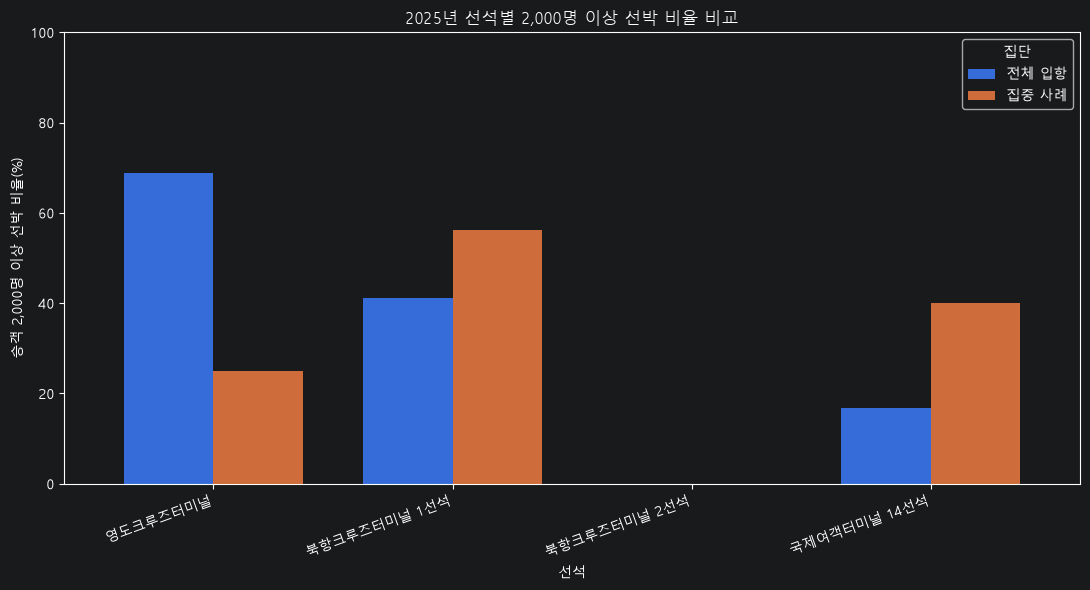

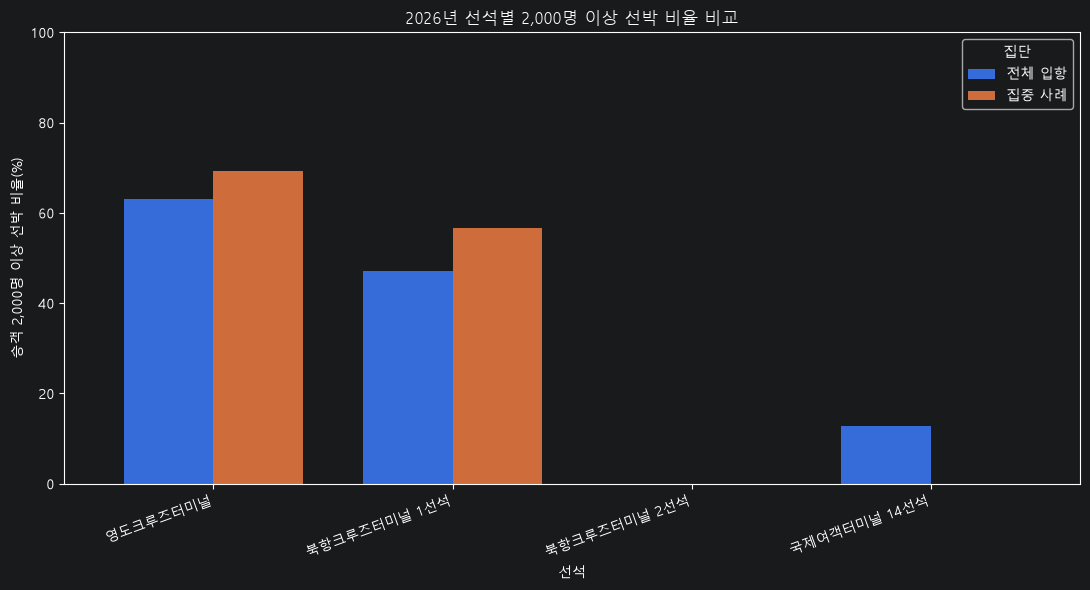


=== 집중 사례와 전체 입항의 대형 선박 비율 차이 ===
  연도          선석명  전체 입항  집중 사례  비율차이(%p)
2025 국제여객터미널 14선석   16.7   40.0      23.3
2025 북항크루즈터미널 1선석   41.1   56.2      15.1
2025 북항크루즈터미널 2선석    0.0    0.0       0.0
2025     영도크루즈터미널   68.8   25.0     -43.8
2026 국제여객터미널 14선석   12.9    0.0     -12.9
2026 북항크루즈터미널 1선석   47.1   56.7       9.5
2026 북항크루즈터미널 2선석    0.0    0.0       0.0
2026     영도크루즈터미널   63.0   69.2       6.2


In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 한글 그래프 설정 (Windows)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

target_berths = [
    "영도크루즈터미널",
    "북항크루즈터미널 1선석",
    "북항크루즈터미널 2선석",
    "국제여객터미널 14선석"
]

# 1. 두 집단의 승객 규모 비율 계산
def calculate_large_ship_rate(data, group_name):
    d = data.copy()

    d["승객"] = pd.to_numeric(d["승객"], errors="coerce")
    d = d[d["선석명"].isin(target_berths)].copy()

    summary = (
        d.groupby(["연도", "선석명"])
        .agg(
            전체척수=("선명", "size"),
            승객기록건수=("승객", "count"),
            이천명이상=("승객", lambda x: (x >= 2000).sum()),
            사천명이상=("승객", lambda x: (x >= 4000).sum())
        )
        .reset_index()
    )

    # 승객 기록이 있는 선박을 분모로 사용
    summary["2000명이상비율(%)"] = (
        summary["이천명이상"] / summary["승객기록건수"] * 100
    )
    summary["4000명이상비율(%)"] = (
        summary["사천명이상"] / summary["승객기록건수"] * 100
    )

    summary["집단"] = group_name
    return summary


all_rate = calculate_large_ship_rate(all_ships, "전체 입항")
focus_rate = calculate_large_ship_rate(concentrated, "집중 사례")

rate_comparison = pd.concat(
    [all_rate, focus_rate],
    ignore_index=True
)

print("=== 선석별·연도별 대형 승객 선박 비율 ===")
print(
    rate_comparison[
        [
            "연도", "선석명", "집단",
            "승객기록건수",
            "이천명이상", "2000명이상비율(%)",
            "사천명이상", "4000명이상비율(%)"
        ]
    ].sort_values(["선석명", "연도", "집단"])
    .round(1)
    .to_string(index=False)
)

# 2. 2,000명 이상 선박 비율 비교 그래프
for year in [2025, 2026]:
    plot_data = rate_comparison[
        rate_comparison["연도"] == year
    ]

    pivot = plot_data.pivot(
        index="선석명",
        columns="집단",
        values="2000명이상비율(%)"
    ).reindex(target_berths)

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 6),
        width=0.75
    )

    ax.set_title(f"{year}년 선석별 2,000명 이상 선박 비율 비교")
    ax.set_xlabel("선석")
    ax.set_ylabel("승객 2,000명 이상 선박 비율(%)")
    ax.set_ylim(0, 100)
    ax.legend(title="집단")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

# 3. 집중 사례 비율 - 전체 입항 비율 차이 계산
wide = rate_comparison.pivot(
    index=["연도", "선석명"],
    columns="집단",
    values="2000명이상비율(%)"
).reset_index()

wide["비율차이(%p)"] = (
    wide["집중 사례"] - wide["전체 입항"]
)

print("\n=== 집중 사례와 전체 입항의 대형 선박 비율 차이 ===")
print(
    wide.sort_values(["연도", "선석명"])
    .round(1)
    .to_string(index=False)
)

=== 운영 준비 유형별 요약 ===
      운영준비유형  사례수  평균입항척수  평균기록승객합계  최대기록승객합계  평균대응거점수  사례비율(%)
   복수 거점 대응형   38     2.0    1859.0    3456.0      2.0     64.4
소수 척·대규모 승객형   17     2.0    5437.1    8277.0      2.0     28.8
  다척·다거점 대응형    3     3.3    3261.3    4761.0      3.3      5.1
  다척·대규모 승객형    1     3.0    7761.0    7761.0      3.0      1.7

=== 운영 준비 유형별 주요 사례 ===
      입항일자                구간시작                구간종료  집중입항건수  동시대응거점수  기록승객합계                                               집중선석       운영준비유형
2026-09-29 2026-09-29 09:00:00 2026-09-29 09:49:00       4        4  4761.0 국제여객터미널 14선석, 북항크루즈터미널 1선석, 북항크루즈터미널 2선석, 영도크루즈터미널   다척·다거점 대응형
2026-03-24 2026-03-24 05:30:00 2026-03-24 06:30:00       3        3  4425.0               북항크루즈터미널 1선석, 북항크루즈터미널 2선석, 영도크루즈터미널   다척·다거점 대응형
2026-04-12 2026-04-12 07:00:00 2026-04-12 08:00:00       3        3   598.0               국제여객터미널 14선석, 북항크루즈터미널 1선석, 영도크루즈터미널   다척·다거점 대응형
2025-04-03 2025-04-03 05:30:00 2025-04-03 06:30:00       3        3  7761.

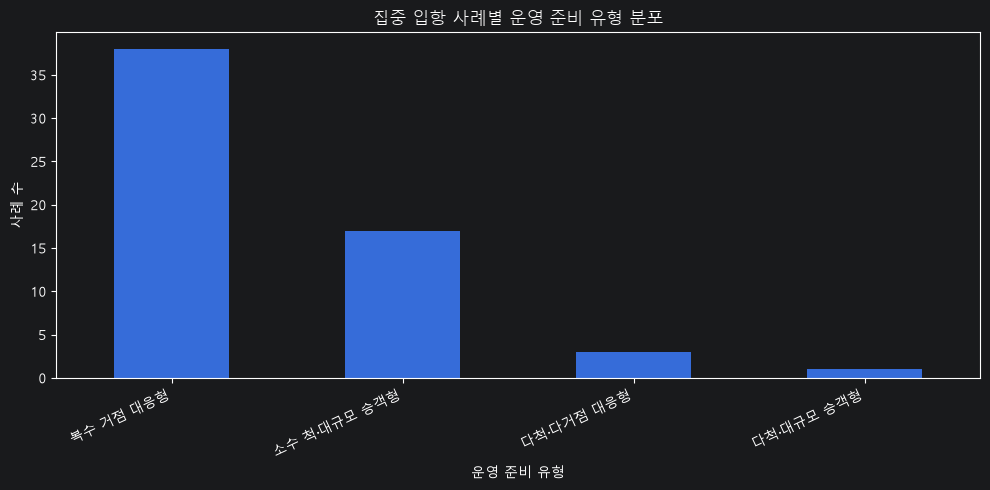

In [86]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 한글 그래프 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 기존 집중 사례 데이터 복사
risk_df = result.copy()

# 데이터 형식 정리
numeric_cols = [
    "집중입항건수",
    "기록승객합계",
    "동시대응거점수"
]

for col in numeric_cols:
    risk_df[col] = pd.to_numeric(
        risk_df[col], errors="coerce"
    )

risk_df["입항일자"] = pd.to_datetime(
    risk_df["입항일자"], errors="coerce"
)

# 2025년 및 2026년 1월~10월 16일 비교
risk_df = risk_df[
    (
        (risk_df["입항일자"].dt.year == 2025)
        & (risk_df["입항일자"].dt.month <= 10)
    )
    |
    (
        (risk_df["입항일자"].dt.year == 2026)
        & (
            (risk_df["입항일자"].dt.month < 10)
            |
            (
                (risk_df["입항일자"].dt.month == 10)
                & (risk_df["입항일자"].dt.day <= 16)
            )
        )
    )
].copy()

# 예비 운영 준비 유형 분류
def classify_case(row):
    ships = row["집중입항건수"]
    passengers = row["기록승객합계"]
    hubs = row["동시대응거점수"]

    if pd.isna(ships) or pd.isna(passengers) or pd.isna(hubs):
        return "분류 불가"

    if ships >= 3 and passengers >= 6000:
        return "다척·대규모 승객형"

    elif ships >= 3 and hubs >= 3:
        return "다척·다거점 대응형"

    elif ships >= 3:
        return "다척 입항형"

    elif passengers >= 4000:
        return "소수 척·대규모 승객형"

    elif hubs >= 2:
        return "복수 거점 대응형"

    else:
        return "일반 집중형"

risk_df["운영준비유형"] = risk_df.apply(
    classify_case, axis=1
)

# 유형별 사례 수와 주요 지표
type_summary = (
    risk_df.groupby("운영준비유형")
    .agg(
        사례수=("입항일자", "size"),
        평균입항척수=("집중입항건수", "mean"),
        평균기록승객합계=("기록승객합계", "mean"),
        최대기록승객합계=("기록승객합계", "max"),
        평균대응거점수=("동시대응거점수", "mean")
    )
    .reset_index()
)

type_summary["사례비율(%)"] = (
    type_summary["사례수"]
    / type_summary["사례수"].sum()
    * 100
)

print("=== 운영 준비 유형별 요약 ===")
print(
    type_summary.sort_values(
        "사례수", ascending=False
    ).round(1).to_string(index=False)
)

print("\n=== 운영 준비 유형별 주요 사례 ===")
print(
    risk_df[
        [
            "입항일자",
            "구간시작",
            "구간종료",
            "집중입항건수",
            "동시대응거점수",
            "기록승객합계",
            "집중선석",
            "운영준비유형"
        ]
    ]
    .sort_values(
        ["운영준비유형", "기록승객합계"],
        ascending=[True, False]
    )
    .to_string(index=False)
)

# 유형별 사례 수 그래프
plot_data = type_summary.sort_values(
    "사례수", ascending=False
)

ax = plot_data.plot(
    kind="bar",
    x="운영준비유형",
    y="사례수",
    legend=False,
    figsize=(10, 5)
)

ax.set_title("집중 입항 사례별 운영 준비 유형 분포")
ax.set_xlabel("운영 준비 유형")
ax.set_ylabel("사례 수")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


=== 연도별 운영 준비 유형 사례 수 ===
운영준비유형  다척·다거점 대응형  다척·대규모 승객형  복수 거점 대응형  소수 척·대규모 승객형
연도                                                     
2025             0           1         14             1
2026             3           0         24            16

=== 연도별 운영 준비 유형 구성비(%) ===
운영준비유형  다척·다거점 대응형  다척·대규모 승객형  복수 거점 대응형  소수 척·대규모 승객형
연도                                                     
2025           0.0         6.2       87.5           6.2
2026           7.0         0.0       55.8          37.2


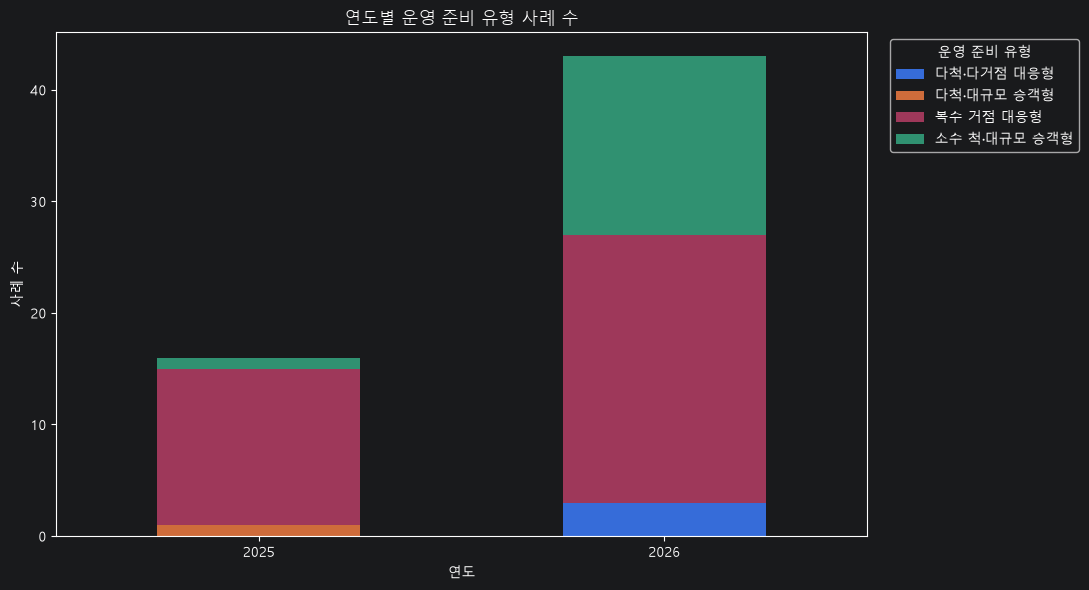

In [87]:

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

df = risk_df.copy()

df["입항일자"] = pd.to_datetime(df["입항일자"], errors="coerce")
df["연도"] = df["입항일자"].dt.year
df["기록승객합계"] = pd.to_numeric(
    df["기록승객합계"], errors="coerce"
)

# 연도별 운영 준비 유형 사례 수
year_type = pd.crosstab(
    df["연도"],
    df["운영준비유형"]
)

print("=== 연도별 운영 준비 유형 사례 수 ===")
print(year_type.to_string())

# 연도별 유형 구성비(%)
year_type_pct = (
    year_type.div(year_type.sum(axis=1), axis=0) * 100
)

print("\n=== 연도별 운영 준비 유형 구성비(%) ===")
print(year_type_pct.round(1).to_string())

# 사례 수 그래프
ax = year_type.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

ax.set_title("연도별 운영 준비 유형 사례 수")
ax.set_xlabel("연도")
ax.set_ylabel("사례 수")
ax.legend(title="운영 준비 유형", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


=== 운영 준비 유형별 기록 승객 규모 분포 ===
승객규모구간        2,000명 미만  2,000~3,999명  4,000~5,999명  6,000명 이상
운영준비유형                                                        
다척·다거점 대응형            1             0             2          0
다척·대규모 승객형            0             0             0          1
복수 거점 대응형            18            20             0          0
소수 척·대규모 승객형          0             0            14          3

=== 연도별 기록 승객 규모 분포 ===
승객규모구간  2,000명 미만  2,000~3,999명  4,000~5,999명  6,000명 이상
연도                                                      
2025            7             7             1          1
2026           12            13            15          3


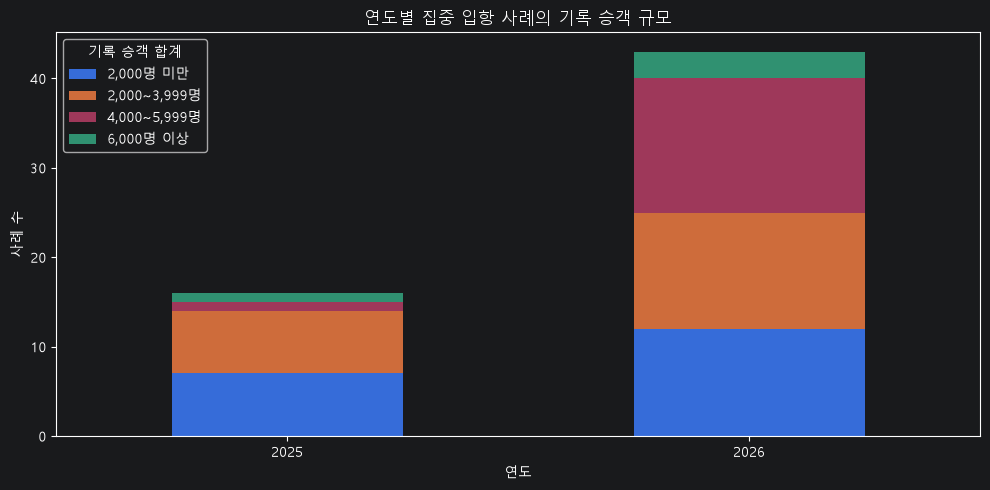

In [88]:

# 기록 승객 합계 구간 분류
bins = [0, 2000, 4000, 6000, float("inf")]

labels = [
    "2,000명 미만",
    "2,000~3,999명",
    "4,000~5,999명",
    "6,000명 이상"
]

df["승객규모구간"] = pd.cut(
    df["기록승객합계"],
    bins=bins,
    labels=labels,
    right=False
)

# 유형별 승객 규모 구간 분포
passenger_distribution = pd.crosstab(
    df["운영준비유형"],
    df["승객규모구간"]
).reindex(columns=labels, fill_value=0)

print("=== 운영 준비 유형별 기록 승객 규모 분포 ===")
print(passenger_distribution.to_string())

# 연도별 승객 규모 구간 분포
year_passenger = pd.crosstab(
    df["연도"],
    df["승객규모구간"]
).reindex(columns=labels, fill_value=0)

print("\n=== 연도별 기록 승객 규모 분포 ===")
print(year_passenger.to_string())

# 연도별 승객 규모 분포 그래프
ax = year_passenger.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

ax.set_title("연도별 집중 입항 사례의 기록 승객 규모")
ax.set_xlabel("연도")
ax.set_ylabel("사례 수")
ax.legend(title="기록 승객 합계")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


=== 동일 기간 연도별 운영 준비 유형 사례 수 ===
운영준비유형  다척·다거점 대응형  다척·대규모 승객형  복수 거점 대응형  소수 척·대규모 승객형
연도                                                     
2025             0           1         14             1
2026             3           0         24            16

=== 동일 기간 연도별 운영 준비 유형 구성비(%) ===
운영준비유형  다척·다거점 대응형  다척·대규모 승객형  복수 거점 대응형  소수 척·대규모 승객형
연도                                                     
2025           0.0         6.2       87.5           6.2
2026           7.0         0.0       55.8          37.2

=== 연도별 전체 집중 사례 수 ===
연도
2025    16
2026    43

=== 동일 기간 연도별 기록 승객 규모 ===
승객규모구간  2,000명 미만  2,000~3,999명  4,000~5,999명  6,000명 이상
연도                                                      
2025            7             7             1          1
2026           12            13            15          3


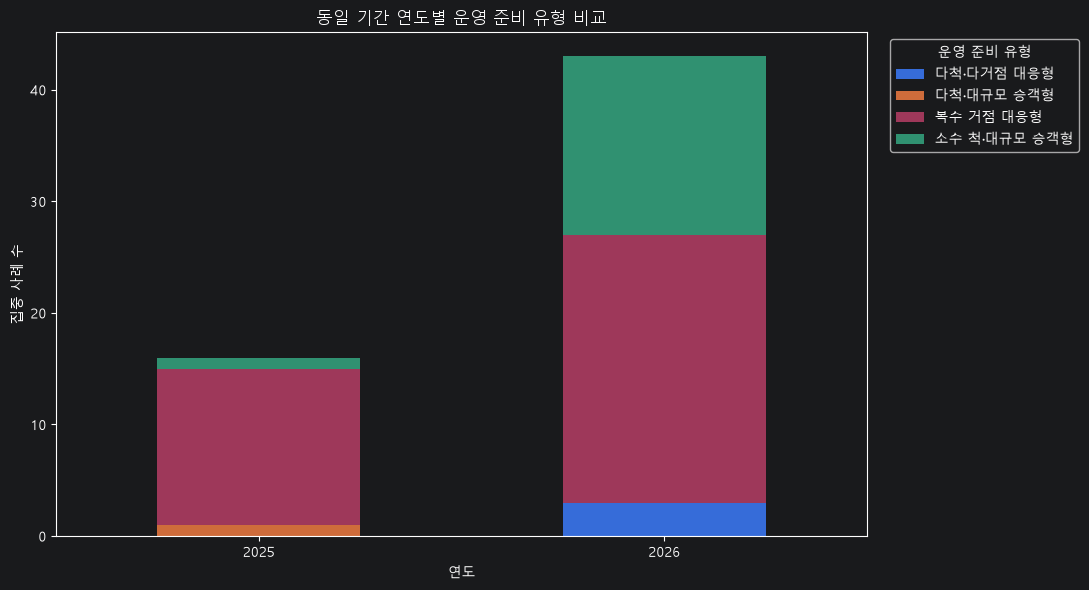

In [89]:

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 1. 원본 집중 사례 데이터 준비
risk_compare = result.copy()

risk_compare["입항일자"] = pd.to_datetime(
    risk_compare["입항일자"], errors="coerce"
)

for col in ["집중입항건수", "기록승객합계", "동시대응거점수"]:
    risk_compare[col] = pd.to_numeric(
        risk_compare[col], errors="coerce"
    )

# 2. 두 연도 모두 1월 1일~10월 16일로 통일
risk_compare = risk_compare[
    (
        risk_compare["입항일자"].dt.year.isin([2025, 2026])
    )
    & (
        (
            risk_compare["입항일자"].dt.month < 10
        )
        | (
            (risk_compare["입항일자"].dt.month == 10)
            & (risk_compare["입항일자"].dt.day <= 16)
        )
    )
].copy()

risk_compare["연도"] = risk_compare["입항일자"].dt.year

# 3. 동일한 분류 기준 적용
def classify_case(row):
    ships = row["집중입항건수"]
    passengers = row["기록승객합계"]
    hubs = row["동시대응거점수"]

    if pd.isna(ships) or pd.isna(passengers) or pd.isna(hubs):
        return "분류 불가"

    if ships >= 3 and passengers >= 6000:
        return "다척·대규모 승객형"
    elif ships >= 3 and hubs >= 3:
        return "다척·다거점 대응형"
    elif ships >= 3:
        return "다척 입항형"
    elif passengers >= 4000:
        return "소수 척·대규모 승객형"
    elif hubs >= 2:
        return "복수 거점 대응형"
    else:
        return "일반 집중형"

risk_compare["운영준비유형"] = risk_compare.apply(
    classify_case, axis=1
)

# 4. 연도별 사례 수와 구성비
year_type = pd.crosstab(
    risk_compare["연도"],
    risk_compare["운영준비유형"]
)

year_type_pct = (
    year_type.div(year_type.sum(axis=1), axis=0) * 100
)

print("=== 동일 기간 연도별 운영 준비 유형 사례 수 ===")
print(year_type.to_string())

print("\n=== 동일 기간 연도별 운영 준비 유형 구성비(%) ===")
print(year_type_pct.round(1).to_string())

print("\n=== 연도별 전체 집중 사례 수 ===")
print(risk_compare.groupby("연도").size().to_string())

# 5. 연도별 기록 승객 규모 분포
bins = [0, 2000, 4000, 6000, float("inf")]
labels = [
    "2,000명 미만",
    "2,000~3,999명",
    "4,000~5,999명",
    "6,000명 이상"
]

risk_compare["승객규모구간"] = pd.cut(
    risk_compare["기록승객합계"],
    bins=bins,
    labels=labels,
    right=False
)

passenger_by_year = pd.crosstab(
    risk_compare["연도"],
    risk_compare["승객규모구간"]
).reindex(columns=labels, fill_value=0)

print("\n=== 동일 기간 연도별 기록 승객 규모 ===")
print(passenger_by_year.to_string())

# 6. 유형별 사례 수 그래프
ax = year_type.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

ax.set_title("동일 기간 연도별 운영 준비 유형 비교")
ax.set_xlabel("연도")
ax.set_ylabel("집중 사례 수")
ax.legend(title="운영 준비 유형", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# ==========================================
# 1. 데이터 불러오기 및 입항 기록 추출
# ==========================================

df = pd.read_csv("i(2).csv", encoding="cp949")

df["입항일시_dt"] = pd.to_datetime(
    df["입항일시"], errors="coerce"
)

arrival = df[
    (df["입출"] == "입항")
    & (df["입항일시_dt"].notna())
].copy()

arrival["날짜"] = arrival["입항일시_dt"].dt.normalize()

print("전체 입항 기록:", len(arrival))
print("분석 시작:", arrival["날짜"].min())
print("분석 종료:", arrival["날짜"].max())


# ==========================================
# 2. 분석 가능한 날짜 범위 생성
#    2020~2022년은 데이터 공백이므로 제외
# ==========================================

date_blocks = [
    ("2013-01-01", "2019-12-31"),
    ("2023-01-01", "2026-10-16")
]

all_dates = pd.DatetimeIndex([])

for start, end in date_blocks:
    all_dates = all_dates.append(
        pd.date_range(start=start, end=end, freq="D")
    )

daily = pd.DataFrame(index=all_dates)
daily.index.name = "날짜"

# 날짜별 전체 입항 건수
daily["입항건수"] = (
    arrival.groupby("날짜").size()
    .reindex(daily.index, fill_value=0)
)


# ==========================================
# 3. 예측 목표 생성
#    하루 중 60분 이내 2척 이상 입항 여부
# ==========================================

daily["집중입항"] = 0

for date, group in arrival.groupby("날짜"):
    times = sorted(group["입항일시_dt"].tolist())

    left = 0
    max_ships = 0

    for right in range(len(times)):
        while (
            times[right] - times[left]
            > pd.Timedelta(minutes=60)
        ):
            left += 1

        max_ships = max(max_ships, right - left + 1)

    if date in daily.index:
        daily.loc[date, "집중입항"] = int(max_ships >= 2)


# ==========================================
# 4. 예측 변수 생성
# ==========================================

daily["월"] = daily.index.month
daily["요일"] = daily.index.dayofweek
daily["연도"] = daily.index.year

# 월과 요일의 순환 특성 반영
daily["월_sin"] = np.sin(2 * np.pi * daily["월"] / 12)
daily["월_cos"] = np.cos(2 * np.pi * daily["월"] / 12)

daily["요일_sin"] = np.sin(
    2 * np.pi * daily["요일"] / 7
)
daily["요일_cos"] = np.cos(
    2 * np.pi * daily["요일"] / 7
)

# 데이터가 연속적으로 존재하는 구간별로
# 과거 입항 건수 계산
daily["직전7일입항"] = np.nan
daily["직전30일입항"] = np.nan

for start, end in date_blocks:
    block_index = pd.date_range(start, end, freq="D")
    block = daily.loc[block_index, "입항건수"]

    daily.loc[block_index, "직전7일입항"] = (
        block.shift(1).rolling(7, min_periods=7).sum()
    )

    daily.loc[block_index, "직전30일입항"] = (
        block.shift(1).rolling(30, min_periods=30).sum()
    )


# ==========================================
# 5. 학습 데이터와 검증 데이터 분리
# ==========================================

features = [
    "연도",
    "월_sin", "월_cos",
    "요일_sin", "요일_cos",
    "직전7일입항",
    "직전30일입항"
]

model_data = daily.dropna(subset=features).copy()

train = model_data[
    model_data.index < "2025-01-01"
]

test = model_data[
    (model_data.index >= "2025-01-01")
    & (model_data.index <= "2026-10-16")
]

X_train = train[features]
y_train = train["집중입항"]

X_test = test[features]
y_test = test["집중입항"]

print("\n학습 기간:", train.index.min(), "~", train.index.max())
print("검증 기간:", test.index.min(), "~", test.index.max())

print("학습 데이터:", len(train))
print("학습 집중 입항 사례:", int(y_train.sum()))
print("검증 데이터:", len(test))
print("검증 집중 입항 사례:", int(y_test.sum()))


# ==========================================
# 6. 모델 학습
# ==========================================

models = {
    "기준모델": DummyClassifier(strategy="prior"),

    "로지스틱 회귀": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),

    "랜덤포레스트": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    # 집중 입항일일 확률
    probabilities = model.predict_proba(X_test)[:, 1]

    # 우선 0.5를 기준으로 분류
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("\n혼동행렬 [실제 0/1, 예측 0/1]")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

    print("\n분류 성능")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["일반일", "집중입항일"],
            zero_division=0
        )
    )

    ap = average_precision_score(y_test, probabilities)

    # 검증 데이터에 양성/음성 클래스가 모두 있을 때 계산
    auc = (
        roc_auc_score(y_test, probabilities)
        if y_test.nunique() == 2
        else np.nan
    )

    results.append({
        "모델": name,
        "집중입항_평균정밀도": ap,
        "ROC_AUC": auc,
        "예측집중일수": int(predictions.sum())
    })


# ==========================================
# 7. 모델별 성능 비교
# ==========================================

comparison = pd.DataFrame(results).sort_values(
    "집중입항_평균정밀도",
    ascending=False
)

print("\n=== 모델 성능 비교 ===")
print(comparison.to_string(index=False))


# ==========================================
# 8. 랜덤포레스트 기준 예측 결과 저장
# ==========================================

rf = models["랜덤포레스트"]

forecast = test.copy()
forecast["집중입항확률"] = rf.predict_proba(X_test)[:, 1]

forecast["예측결과"] = np.where(
    forecast["집중입항확률"] >= 0.5,
    "집중 입항 예상",
    "일반 입항 예상"
)

forecast = forecast[
    [
        "입항건수",
        "집중입항",
        "직전7일입항",
        "직전30일입항",
        "집중입항확률",
        "예측결과"
    ]
]

forecast.to_csv(
    "크루즈_집중입항_예측결과.csv",
    encoding="utf-8-sig"
)

print("\n=== 예측 결과 상위 20일 ===")
print(
    forecast.sort_values(
        "집중입항확률", ascending=False
    ).head(20).to_string()
)

print("\n예측 결과를 CSV 파일로 저장했습니다.")
